# Evaluate and visualise temporal MLP models


In [4]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Arial",   
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

## Data loading function




In [5]:
# prompt: Load data from mounted google drive In colab folder

import pandas as pd
import os

def load_data(data_path):
    # Load your data using pandas or any other suitable library
    import pandas as pd
    try:
      df = pd.read_csv(data_path, index_col=False)
      print("Data loaded successfully.")
      if 'UniqueID' in df.columns:
        df = df.drop('UniqueID', axis=1)
      if 'Unnamed: 0' in df.columns:
        df = df.drop('Unnamed: 0', axis=1)
      df['TiltDistToStart'] = df['TiltStartPosition'] - df['TiltPosition']
      df['PanDistToStart'] = df['PanStartPosition'] - df['PanPosition']
      # Now you can work with the DataFrame 'df'
    except FileNotFoundError:
      print(f"Error: File not found at {data_path}")
    except Exception as e:
      print(f"An error occurred: {e}")

    return df

## Model and training parameters

In [6]:

all_data_path = '../tMLP_models/all_data_position_control_raw_20250901.csv'
targets = ['TiltCurrent', 'PanCurrent']
features_to_exclude = ['TiltCurrent', 'PanCurrent', 'TiltEffectiveCurrent', 'PanEffectiveCurrent']
#features_tilt = ['GyroX', 'GyroY', 'GyroZ', 'AccelX', 'AccelY', 'AccelZ', 'AngleX','AngleY', 'AngleZ', 'TiltPosition', 'TiltDistToGoal', 'TiltDistToStart']
#features_pan = ['GyroX', 'GyroY', 'GyroZ', 'AccelX', 'AccelY', 'AccelZ','AngleX','AngleY', 'AngleZ', 'PanPosition', 'PanDistToGoal', 'PanDistToStart', 'TiltPosition']
features = ['GyroX', 'GyroY', 'GyroZ', 'AccelX', 'AccelY', 'AccelZ','AngleX','AngleY', 'AngleZ', 'TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
features_no_IMU = ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
features_no_imu_with_current  =['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'TiltCurrent', 'PanPosition', 'PanDistToGoal', 'PanDistToStart', 'PanCurrent']

combined=True


In [7]:
data = load_data(all_data_path)
data.shape

Data loaded successfully.


(39394, 23)

In [8]:
correlations = {}
for feature in ['TiltCurrent', 'TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanCurrent', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']:
    if feature in data.columns:
        target = 'TiltCurrent' if 'Tilt' in feature else 'PanCurrent'
        corr = data[feature].corr(data[target].shift(1))  # Correlation with next timestep
        correlations[feature] = corr
        print(f"{feature:20s}: r = {corr:.4f}")

TiltCurrent         : r = 0.9187
TiltPosition        : r = -0.7506
TiltDistToGoal      : r = 0.5631
TiltDistToStart     : r = 0.1993
PanCurrent          : r = 0.7216
PanPosition         : r = 0.0328
PanDistToGoal       : r = 0.2908
PanDistToStart      : r = -0.0910


## Splitting and scaling data

In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

if combined:
    print("Processing data for combined model...")

    # Features are the same for predicting both TiltCurrent and PanCurrent
    # The target variables are TiltCurrent and PanCurrent
    X = data
    y = data[['TiltCurrent', 'PanCurrent']] # Target variables

    # Split the data into training and testing sets
    X_combined_train, X_combined_test, y_combined_train, y_combined_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)


    # Standardize the combined data using the mean and standard deviation of the training data
    X_combined_train_mean = X_combined_train.mean()
    X_combined_train_std = X_combined_train.std()
    X_combined_train_scaled = (X_combined_train - X_combined_train_mean) / X_combined_train_std
    X_combined_test_scaled = (X_combined_test - X_combined_train_mean) / X_combined_train_std

    # Calculate mean and std for tilt and pan targets from the combined training data
    y_tilt_train_mean = y_combined_train['TiltCurrent'].mean()
    y_tilt_train_std = y_combined_train['TiltCurrent'].std()
    y_pan_train_mean = y_combined_train['PanCurrent'].mean()
    y_pan_train_std = y_combined_train['PanCurrent'].std()

    y_combined_train_mean_combined = y_combined_train.mean() # Renamed to avoid conflict
    y_combined_train_std_combined = y_combined_train.std()   # Renamed to avoid conflict
    y_combined_train_scaled = (y_combined_train - y_combined_train_mean_combined) / y_combined_train_std_combined
    y_combined_test_scaled = (y_combined_test - y_combined_train_mean_combined) / y_combined_train_std_combined


    print("Combined Data Scaled Shapes:")
    print("X_combined_train_scaled:", X_combined_train_scaled.shape)
    print("X_combined_test_scaled:", X_combined_test_scaled.shape)
    print("y_combined_train_scaled:", y_combined_train_scaled.shape)
    print("y_combined_test_scaled:", y_combined_test_scaled.shape)
    print("Features: " + str(features))


else:
    print("Processing data for separate tilt and pan models...")
    # Split tilt data
    X_tilt = data[features]
    y_tilt = data[['TiltCurrent']]  # Target variable # Use double brackets to select multiple columns
    X_tilt_train, X_tilt_test, y_tilt_train, y_tilt_test = train_test_split(X_tilt, y_tilt, test_size=0.2, random_state=42, shuffle=False) # Adjust test_size as needed

    # Split pan data
    X_pan = data[features]
    y_pan = data[['PanCurrent']]  # Target variable # Use double brackets to select multiple columns
    X_pan_train, X_pan_test, y_pan_train, y_pan_test = train_test_split(X_pan, y_pan, test_size=0.2, random_state=42, shuffle=False) # Adjust test_size as needed

    num_inputs = X_tilt.shape[1]

    print("Tilt Data Shapes:")
    print("X_tilt_train:", X_tilt_train.shape)
    print("X_tilt_test:", X_tilt_test.shape)
    print("y_tilt_train:", y_tilt_train.shape)
    print("y_tilt_test:", y_tilt_test.shape)

    print("\nPan Data Shapes:")
    print("X_pan_train:", X_pan_train.shape)
    print("X_pan_test:", X_pan_test.shape)
    print("y_pan_train:", y_pan_train.shape)
    print("y_pan_test:", y_pan_test.shape)


    # Standardize the data using the mean and standard deviation of the training data
    X_tilt_train_mean = X_tilt_train.mean()
    X_tilt_train_std = X_tilt_train.std()
    X_tilt_train_scaled = (X_tilt_train - X_tilt_train_mean) / X_tilt_train_std
    X_tilt_test_scaled = (X_tilt_test - X_tilt_train_mean) / X_tilt_train_std

    y_tilt_train_mean = y_tilt_train.mean()
    y_tilt_train_std = y_tilt_train.std()
    y_tilt_train_scaled = (y_tilt_train - y_tilt_train_mean) / y_tilt_train_std
    y_tilt_test_scaled = (y_tilt_test - y_tilt_train_mean) / y_tilt_train_std


    X_pan_train_mean = X_pan_train.mean()
    X_pan_train_std = X_pan_train.std()
    X_pan_train_scaled = (X_pan_train - X_pan_train_mean) / X_pan_train_std
    X_pan_test_scaled = (X_pan_test - X_pan_train_mean) / X_pan_train_std


    y_pan_train_mean = y_pan_train.mean()
    y_pan_train_std = y_pan_train.std()
    y_pan_train_scaled = (y_pan_train - y_pan_train_mean) / y_pan_train_std
    y_pan_test_scaled = (y_pan_test - y_pan_train_mean) / y_pan_train_std

    print("Tilt Data Scaled Shapes:")
    print("X_tilt_train_scaled:", X_tilt_train_scaled.shape)
    print("X_tilt_test_scaled:", X_tilt_test_scaled.shape)
    print("y_tilt_train_scaled:", y_tilt_train_scaled.shape)
    y_tilt_test_scaled = y_tilt_test_scaled.astype(np.float32) # Ensure correct dtype
    print("y_tilt_test_scaled:", y_tilt_test_scaled.shape)

    print("\nPan Data Scaled Shapes:")
    print("X_pan_train_scaled:", X_pan_train_scaled.shape)
    print("X_pan_test_scaled:", X_pan_test_scaled.shape)
    print("y_pan_train_scaled:", y_pan_train_scaled.shape)
    y_pan_test_scaled = y_pan_test_scaled.astype(np.float32) # Ensure correct dtype
    print("y_pan_test_scaled:", y_pan_test_scaled.shape)

Processing data for combined model...
Combined Data Scaled Shapes:
X_combined_train_scaled: (31515, 23)
X_combined_test_scaled: (7879, 23)
y_combined_train_scaled: (31515, 2)
y_combined_test_scaled: (7879, 2)
Features: ['GyroX', 'GyroY', 'GyroZ', 'AccelX', 'AccelY', 'AccelZ', 'AngleX', 'AngleY', 'AngleZ', 'TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']


In [10]:
def combine_mean_std(mean_series, std_series):
  """Combines mean and std Series into a dictionary with mean and std keys."""
  combined_dict = {}
  # Ensure mean_series and std_series are pandas Series
  mean_series = pd.Series(mean_series)
  std_series = pd.Series(std_series)

  for col in mean_series.index:
    combined_dict[col] = {'mean': float(mean_series[col]), 'std': float(std_series[col])}
  return combined_dict

import json
import pandas as pd # Import pandas here
import numpy as np # Import numpy

# Ensure y_tilt_train_mean/std and y_pan_train_mean/std are Series even if they were single values
# This is now handled in the combine_mean_std function by converting to Series


#save mean and stds dict
if combined:
  # For combined model, we already have combined mean and std
  # Use y_combined_train_mean_combined and y_combined_train_std_combined
  mean_std = combine_mean_std(y_combined_train_mean_combined, y_combined_train_std_combined)


else:
  # Combine means and stds for tilt data
  tilt_mean_std = combine_mean_std(pd.concat([X_tilt_train_mean, pd.Series([y_tilt_train_mean])]), pd.concat([X_tilt_train_std, pd.Series([y_tilt_train_std])]))
  pan_mean_std = combine_mean_std(pd.concat([X_pan_train_mean, pd.Series([y_pan_train_mean])]), pd.concat([X_pan_train_std, pd.Series([y_pan_train_std])]))


## Sequence data function

In [11]:
import pandas as pd
import numpy as np

def create_sequences(data_array, sequence_length=10):
    """
    Create sequences of consecutive rows for neural network input from a NumPy array.

    Args:
        data_array (np.ndarray): The input NumPy array.
        sequence_length (int): The number of previous time steps to include in each sequence.

    Returns:
        np.ndarray: Time-stepped feature data (samples, time_step, features).
    """
    sequences = []

    for i in range(len(data_array) - sequence_length + 1):
        # Get sequence of 10 rows
        sequence = data_array[i:i + sequence_length]
        sequences.append(sequence)

    return np.array(sequences)



In [12]:
from re import I
# prompt: apply time_step to combined data if model_name is combined, otherwise apply to tilt and pan data separately

def sequence_data(X_scaled_train, X_scaled_test, y_scaled_train, y_scaled_test, time_step):
    """
    Creates time-stepped sequences for features and aligns targets.
    """
    print("Applying time-stepping to combined data...")

    # Create sequences for features
    X_train_ts = create_sequences(X_scaled_train.values, sequence_length=time_step)
    X_test_ts = create_sequences(X_scaled_test.values, sequence_length=time_step)

    # Align targets with the last step of each sequence.
    # The number of sequences will be `len(original_data) - time_step + 1`.
    # The corresponding targets are the values from the original y_scaled_data
    # starting from the `time_step`-th row (index `time_step-1`).
    y_train_ts_targets = y_scaled_train.values[time_step-1:]
    y_test_ts_targets = y_scaled_test.values[time_step-1:]

    print("Time-stepped Data Shapes:")
    print("X_train_ts:", X_train_ts.shape)
    print("X_test_ts:", X_test_ts.shape)
    print("y_train_ts_targets:", y_train_ts_targets.shape)
    print("y_test_ts_targets:", y_test_ts_targets.shape)

    return X_train_ts, X_test_ts, y_train_ts_targets, y_test_ts_targets


## Custom weighted loss



In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout, LeakyReLU, Flatten, GRU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.losses import Huber
import keras.backend as K
import json
import os
import sys
import pickle
import pandas as pd # Import pandas for binning
import numpy as np # Import numpy

@tf.function
def weighted_mse_high_current(y_true, y_pred):
    threshold = 1.8 # Adjust based on your scaled data's range
    is_high_magnitude = tf.cast(tf.abs(y_true) > threshold, tf.float32)
    # Give e.g., 5x more weight to high magnitude samples
    weights = 1.0 + is_high_magnitude * 4.0
    # Use tf.reduce_mean instead of K.mean
    return tf.reduce_mean(weights * tf.square(y_pred - y_true), axis=-1)

# Refined weighted_mse loss function using spike analysis data
@tf.function
def weighted_mse_refined(y_true, y_pred, X_batch, avg_spike_data, features_tilt, features_pan, time_step):
    """Custom Mean Squared Error loss with weighting based on spike analysis."""
    # Ensure X_batch is a TensorFlow tensor
    X_batch = tf.cast(X_batch, tf.float32)

    # Extract relevant features from the last time step of the batch
    # We need the original scale features for binning
    # Assuming X_batch contains scaled features and needs inverse transformation
    # This part needs to be carefully aligned with how your data is structured and scaled

    # For demonstration purposes, let's assume X_batch is already in the correct shape
    # (batch_size, time_step, features) and we need to get the features for the last time step
    last_time_step_features = X_batch[:, -1, :] # Get features from the last time step

    # This is a simplified approach. You would need to map these scaled features back to original scale
    # using your mean/std values if your bin edges are based on original scale.
    # For now, let's assume you have a way to get the features in the scale used for binning.

    # Example: Get TiltPosition and PanPosition from the batch (indices will depend on your feature order)
    # You'll need to adjust indices based on the order of features in your X_combined_train_scaled/X_tilt/X_pan
    tilt_pos_idx = features_tilt.index('TiltPosition') if 'TiltPosition' in features_tilt else None
    pan_pos_idx = features_pan.index('PanPosition') if 'PanPosition' in features_pan else None
    tilt_dist_start_idx = features_tilt.index('TiltDistToStart') if 'TiltDistToStart' in features_tilt else None
    pan_dist_start_idx = features_pan.index('PanDistToStart') if 'PanDistToStart' in features_pan else None
    tilt_dist_goal_idx = features_tilt.index('TiltDistToGoal') if 'TiltDistToGoal' in features_tilt else None
    pan_dist_goal_idx = features_pan.index('PanDistToGoal') if 'PanDistToGoal' in features_pan else None


    # Determine weights based on average spike data
    weights = tf.ones_like(y_true) # Start with weights of 1

    # This part is complex to implement directly in a @tf.function due to dynamic binning lookup.
    # A common approach is to pre-calculate weights for your training data based on their bins
    # and pass these weights during model.fit using the `sample_weight` argument.
    # Or, create a lookup structure that is compatible with TensorFlow operations.

    # For demonstration, let's use a simplified weighting based on a threshold on the target
    # You can replace this with your bin-based weighting logic
    threshold = 1.8 # Example threshold on scaled target
    is_high_magnitude = tf.cast(tf.abs(y_true) > threshold, tf.float32)
    weights = 1.0 + is_high_magnitude * 4.0 # Example weighting


    # Apply weights to the squared error
    # Ensure weights shape matches the squared error shape
    weighted_squared_error = weights * tf.square(y_pred - y_true)

    return tf.reduce_mean(weighted_squared_error, axis=-1)
    # Helper function to calculate sample weights based on spike analysis
def calculate_sample_weights(X_data, y_data, avg_spike_data, features_tilt, features_pan, time_step, pan_pos_bins_edges, tilt_pos_bins_edges, pan_dist_start_bins_edges, tilt_dist_start_bins_edges, pan_dist_goal_bins_edges, tilt_dist_goal_bins_edges):
    """
    Calculates sample weights based on average spike data for each sample.

    Args:
        X_data (np.ndarray): The input feature data (samples, time_step, features).
        y_data (np.ndarray): The target data (samples, targets).
        avg_spike_data (dict): Dictionary containing average spike data by bins.
        features_tilt (list): List of tilt features.
        features_pan (list): List of pan features.
        time_step (int): The time step used for sequences.
        pan_pos_bins_edges (np.ndarray): Edges for pan position bins.
        tilt_pos_bins_edges (np.ndarray): Edges for tilt position bins.
        pan_dist_start_bins_edges (np.ndarray): Edges for pan distance to start bins.
        tilt_dist_start_bins_edges (np.ndarray): Edges for tilt distance to start bins.
        pan_dist_goal_bins_edges (np.ndarray): Edges for pan distance to goal bins.
        tilt_dist_goal_bins_edges (np.ndarray): Edges for tilt distance to goal bins.


    Returns:
        np.ndarray: Array of sample weights.
    """
    # Initialize weights to 1
    weights = np.ones(len(X_data))

    # Get features from the last time step (corresponding to the target)
    last_time_step_features = X_data[:, -1, :]

    # Assuming your features in X_data are in the order defined by features_tilt and features_pan (for combined model)
    # or just features_tilt/features_pan for separate models.
    # You need to map these back to original scale if your bins are based on original scale.
    # This is a placeholder and needs actual inverse scaling if necessary.
    # For demonstration, we'll assume features are in a scale compatible with the bin edges.

    if 'combined' in model_name:
        # Assuming a combined model where features are concatenated
        # Need to adjust indices based on the order of features in X_combined_train_scaled
        try:
            # Ensure 'features' is accessible, assuming it's defined globally or passed
            features_list = features.tolist() if isinstance(features, np.ndarray) else features
            tilt_pos_idx = features_list.index('TiltPosition')
            pan_pos_idx = features_list.index('PanPosition')
            tilt_dist_start_idx = features_list.index('TiltDistToStart')
            pan_dist_start_idx = features_list.index('PanDistToStart')
            tilt_dist_goal_idx = features_list.index('TiltDistToGoal')
            pan_dist_goal_idx = features_list.index('PanDistToGoal')

            tilt_pos_batch = last_time_step_features[:, tilt_pos_idx]
            pan_pos_batch = last_time_step_features[:, pan_pos_idx]
            tilt_dist_start_batch = last_time_step_features[:, tilt_dist_start_idx]
            pan_dist_start_batch = last_time_step_features[:, pan_dist_start_idx]
            tilt_dist_goal_batch = last_time_step_features[:, tilt_dist_goal_idx]
            pan_dist_goal_batch = last_time_step_features[:, pan_dist_goal_idx]

        except ValueError as e:
            print(f"Error finding feature index: {e}. Ensure features list is correctly defined.")
            return weights # Return default weights if features are not found


        # Assign weights based on average spike in corresponding bins
        # This part requires mapping batch values to bins and looking up average spike values.
        # This is non-trivial to implement efficiently in NumPy/TensorFlow without pre-calculated lookups or more advanced indexing.
        # A simplified approach is to iterate or use pandas binning on a temporary DataFrame (less efficient within a training loop)

        # For a practical implementation during training, it's better to pre-calculate weights for your entire training dataset
        # and pass them to model.fit using the `sample_weight` argument.

        # --- Placeholder for actual bin-based weighting logic ---
        # Example: Assign higher weight if absolute true current is high (similar to weighted_mse_high_current but can be combined with bin info)
        threshold = 1.8 # Example threshold on scaled target
        is_high_magnitude_tilt = np.abs(y_data[:, 0]) > threshold
        is_high_magnitude_pan = np.abs(y_data[:, 1]) > threshold
        is_high_magnitude = is_high_magnitude_tilt | is_high_magnitude_pan
        weights[is_high_magnitude] = 5.0 # Example: Assign weight of 5 to high magnitude samples

        # You would replace the above with logic that finds the bin for each sample's features
        # and assigns a weight based on the average spike value in that bin from avg_spike_data.
        # This would likely involve using pd.cut or similar logic.

    else:
        # Assuming separate tilt and pan models
         try:
            tilt_pos_idx = features_tilt.index('TiltPosition')
            tilt_dist_start_idx = features_tilt.index('TiltDistToStart')
            tilt_dist_goal_idx = features_tilt.index('TiltDistToGoal')

            pan_pos_idx = features_pan.index('PanPosition')
            pan_dist_start_idx = features_pan.index('PanDistToStart')
            pan_dist_goal_idx = features_pan.index('PanDistToGoal')

            tilt_pos_batch = last_time_step_features[:, tilt_pos_idx]
            tilt_dist_start_batch = last_time_step_features[:, tilt_dist_start_idx]
            tilt_dist_goal_batch = last_time_step_features[:, tilt_dist_goal_idx]

            pan_pos_batch = last_time_step_features[:, pan_pos_idx]
            pan_dist_start_batch = last_time_step_features[:, pan_dist_start_idx]
            pan_dist_goal_batch = last_time_step_features[:, pan_dist_goal_idx]


         except ValueError as e:
            print(f"Error finding feature index: {e}. Ensure features list is correctly defined.")
            return weights # Return default weights if features are not found







## Load models

In [14]:
import keras
import tensorflow as tf

print("keras:", keras.__version__)
print("tensorflow:", tf.__version__)


keras: 3.13.2
tensorflow: 2.19.0


In [15]:
from tensorflow.keras.models import load_model

TS_0_no_IMU = load_model('../tMLP_models/temporal_mlp_TimeSteps0_no_IMU.keras')
TS_1_no_IMU = load_model('../tMLP_models/temporal_mlp_TimeSteps1_no_IMU.keras')
TS_3_no_IMU = load_model('../tMLP_models/temporal_mlp_TimeSteps3_no_IMU.keras')
TS_5_no_IMU = load_model('../tMLP_models/temporal_mlp_TimeSteps5_no_IMU.keras')
TS_10_no_IMU = load_model('../tMLP_models/temporal_mlp_TimeSteps10_no_IMU.keras')
TS_15_no_IMU = load_model('../tMLP_models/temporal_mlp_TimeSteps15_no_IMU.keras')

TS_1_no_IMU_with_current = load_model('../tMLP_models/temporal_mlp_TimeSteps1_no_IMU_with_current.keras')
TS_3_no_IMU_with_current = load_model('../tMLP_models/temporal_mlp_TimeSteps3_no_IMU_with_current.keras')
TS_5_no_IMU_with_current = load_model('../tMLP_models/temporal_mlp_TimeSteps5_no_IMU_with_current.keras')
TS_10_no_IMU_with_current = load_model('../tMLP_models/temporal_mlp_TimeSteps10_no_IMU_with_current.keras')
TS_15_no_IMU_with_current = load_model('../tMLP_models/temporal_mlp_TimeSteps15_no_IMU_with_current.keras')
TS_0 = load_model('../tMLP_models/temporal_mlp_TimeSteps0.keras')
TS_1 = load_model('../tMLP_models/temporal_mlp_TimeSteps1.keras')
TS_3 = load_model('../tMLP_models/temporal_mlp_TimeSteps3.keras')
TS_5 = load_model('../tMLP_models/temporal_mlp_TimeSteps5.keras')
TS_10 = load_model('../tMLP_models/temporal_mlp_TimeSteps10.keras')
TS_15 = load_model('../tMLP_models/temporal_mlp_TimeSteps15.keras')

TS_models_lst = [TS_1_no_IMU, TS_3_no_IMU, TS_5_no_IMU, TS_10_no_IMU, TS_15_no_IMU, TS_1, TS_3, TS_5, TS_10, TS_15, TS_1_no_IMU_with_current,  TS_3_no_IMU_with_current, TS_5_no_IMU_with_current, TS_10_no_IMU_with_current, TS_15_no_IMU_with_current]

single_step_models_lst = [TS_0_no_IMU, TS_0] 

all_models_lst = single_step_models_lst + TS_models_lst


In [16]:
mean_std = pd.read_json('../tMLP_models/scalars_features/mean_std.json')


In [17]:
import matplotlib.pyplot as plt

def prediction_errors_distance_plots(predictions, y_true, X_test, mean_std, features, timestep, IMU_model=False, model_name='None'):
    """
    Plots prediction errors against distance to start and goal for tilt and pan.

    Args:
        predictions (np.ndarray): Model predictions.
        y_true (np.ndarray): True target values.
        X_combined_test (pd.DataFrame): Original test features (unscaled).
        mean_std (pd.DataFrame): DataFrame containing mean and std for unstandardization.
        features (list): List of feature names.
        timestep (int): The time step used in the model.
    """

    # Unstandardise test features
    X_test_unscaled = X_test[timestep-1:] * mean_std.loc['std', features].values + mean_std.loc['mean', features].values

    prediction_errors = predictions - y_true
    # Extract distance to start and goal columns
    tilt_dist_to_start = X_test_unscaled['TiltDistToGoal']
    tilt_dist_to_goal = X_test_unscaled['TiltDistToGoal']
    pan_dist_to_start = X_test_unscaled['PanDistToStart']
    pan_dist_to_goal = X_test_unscaled['PanDistToGoal']

    fig, axs = plt.subplots(2, 2, figsize=(14, 10))

    # Tilt predictions vs TiltDistToStart
    axs[0, 0].scatter(tilt_dist_to_start, prediction_errors[:, 0], alpha=0.5)
    axs[0, 0].set_xlabel('TiltDistToStart')
    axs[0, 0].set_ylabel('Predicted TiltCurrent')
    axs[0, 0].set_title('Predicted TiltCurrent vs TiltDistToStart')

    # Tilt predictions vs TiltDistToGoal
    axs[0, 1].scatter(tilt_dist_to_goal, prediction_errors[:, 0], alpha=0.5)
    axs[0, 1].set_xlabel('TiltDistToGoal')
    axs[0, 1].set_ylabel('Predicted TiltCurrent')
    axs[0, 1].set_title('Predicted TiltCurrent vs TiltDistToGoal')

    # Pan predictions vs PanDistToStart
    axs[1, 0].scatter(pan_dist_to_start, prediction_errors[:, 1], alpha=0.5)
    axs[1, 0].set_xlabel('PanDistToStart')
    axs[1, 0].set_ylabel('Predicted PanCurrent')
    axs[1, 0].set_title('Predicted PanCurrent vs PanDistToStart')

    # Pan predictions vs PanDistToGoal
    axs[1, 1].scatter(pan_dist_to_goal, prediction_errors[:, 1], alpha=0.5)
    axs[1, 1].set_xlabel('PanDistToGoal')
    axs[1, 1].set_ylabel('Predicted PanCurrent')
    axs[1, 1].set_title('Predicted PanCurrent vs PanDistToGoal')

    IMU_model_str = "with IMU" if IMU_model else "without IMU"
    current_model_str = "with Current" if 'with_current' in model_name else "without Current"

    plt.suptitle(f'Prediction Errors vs Distance Plots for Time Step {timestep} {IMU_model_str} and {current_model_str}')
    plt.tight_layout()
    plt.savefig(f'./plots/prediction_errors_distance_plots_timestep{timestep}_{IMU_model_str}_{current_model_str}.jpeg')
   
    



Evaluating model: temporal_mlp_TimeSteps1_no_IMU with time step 1 using features: ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
Applying time-stepping to combined data...
Time-stepped Data Shapes:
X_train_ts: (31515, 1, 6)
X_test_ts: (7879, 1, 6)
y_train_ts_targets: (31515, 2)
y_test_ts_targets: (7879, 2)
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 463us/step
Pltos saved in ./plots/ folder
Model: temporal_mlp_TimeSteps1_no_IMU - Loss: 0.08761753141880035, MSE: 0.27067849040031433
Evaluating model: temporal_mlp_TimeSteps3_no_IMU with time step 3 using features: ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
Applying time-stepping to combined data...
Time-stepped Data Shapes:
X_train_ts: (31513, 3, 6)
X_test_ts: (7877, 3, 6)
y_train_ts_targets: (31513, 2)
y_test_ts_targets: (7877, 2)
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 552us/step
Pltos saved in ./plots/ folder
Model: temporal_mlp_TimeSteps3

I0000 00:00:1781699792.169670 24849162 service.cc:152] XLA service 0x307d4a820 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781699792.169680 24849162 service.cc:160]   StreamExecutor device (0): Host, Default Version
2026-06-17 14:36:32.197452: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


135/246 ━━━━━━━━━━━━━━━━━━━━ 0s 375us/step  

I0000 00:00:1781699792.479254 24849162 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


246/246 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Pltos saved in ./plots/ folder
Model: temporal_mlp_TimeSteps15 - Loss: 0.037772197276353836, MSE: 0.16191235184669495
Evaluating model: temporal_mlp_TimeSteps1_no_IMU_with_current with time step 1 using features: ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'TiltCurrent', 'PanPosition', 'PanDistToGoal', 'PanDistToStart', 'PanCurrent']
Applying time-stepping to combined data...
Time-stepped Data Shapes:
X_train_ts: (31515, 1, 8)
X_test_ts: (7879, 1, 8)
y_train_ts_targets: (31515, 2)
y_test_ts_targets: (7879, 2)
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step
Pltos saved in ./plots/ folder
Model: temporal_mlp_TimeSteps1_no_IMU_with_current - Loss: 0.0030767107382416725, MSE: 0.03026357665657997
Evaluating model: temporal_mlp_TimeSteps3_no_IMU_with_current with time step 3 using features: ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'TiltCurrent', 'PanPosition', 'PanDistToGoal', 'PanDistToStart', 'PanCurrent']
Applying time-stepping to

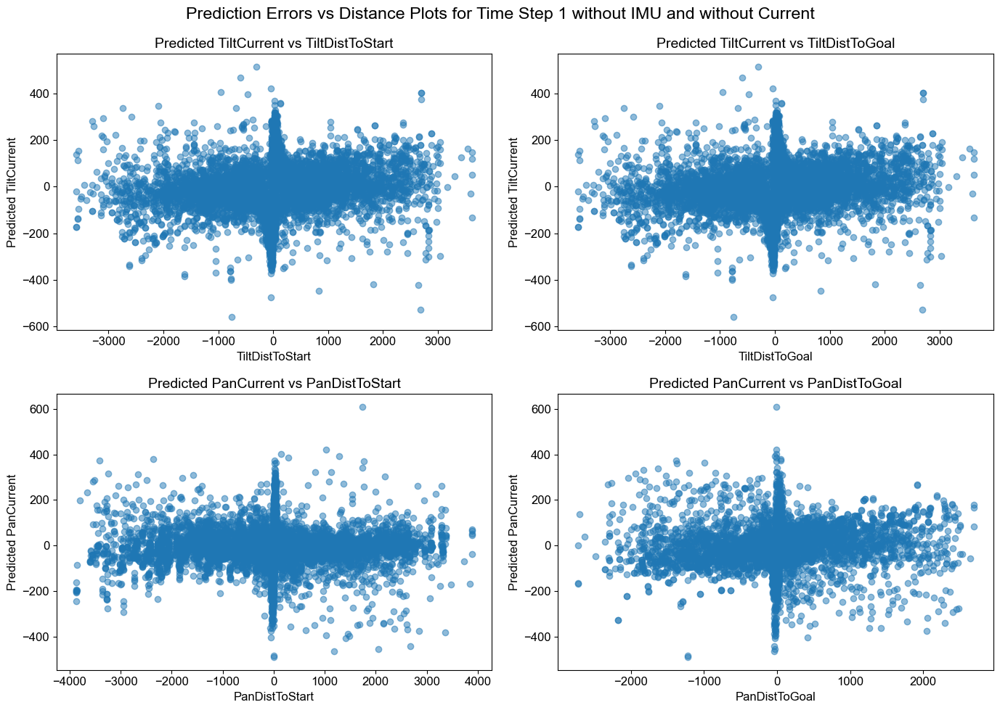

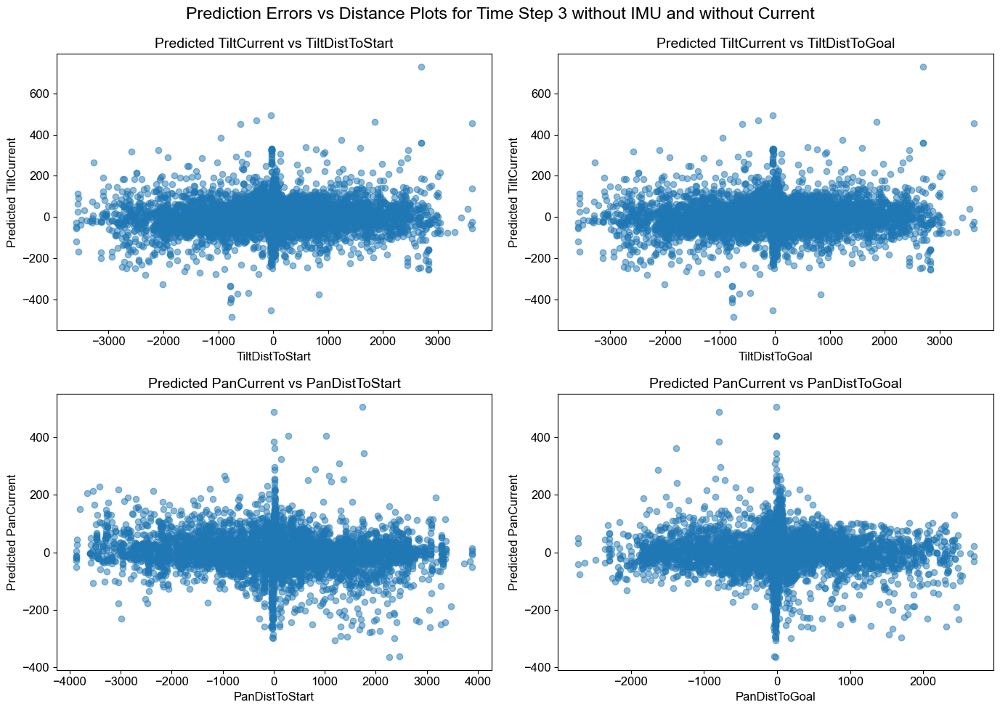

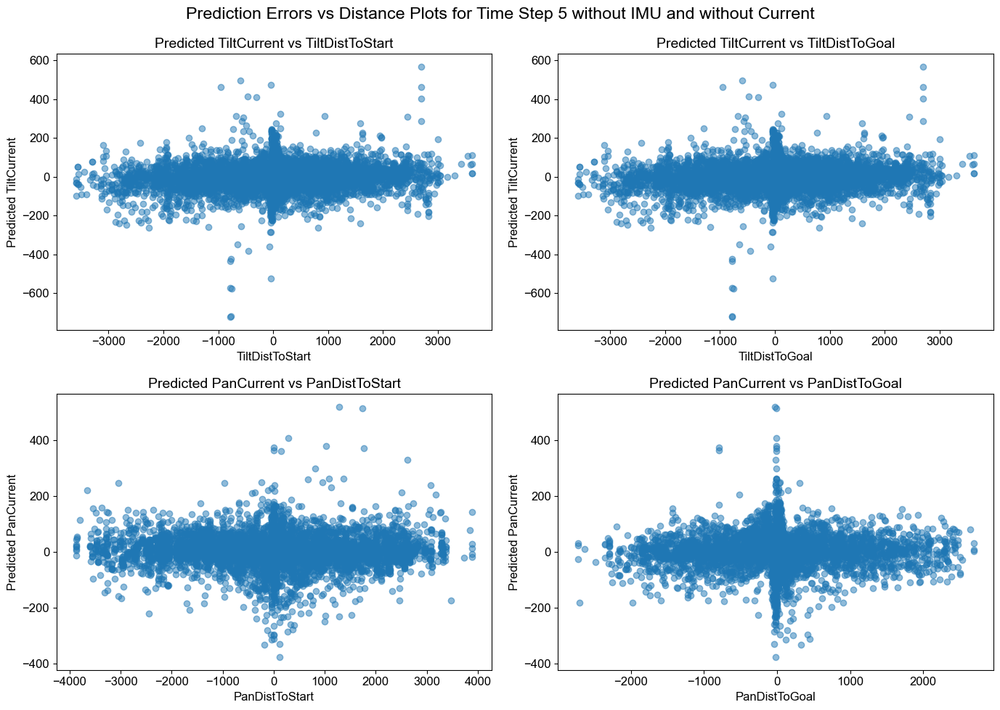

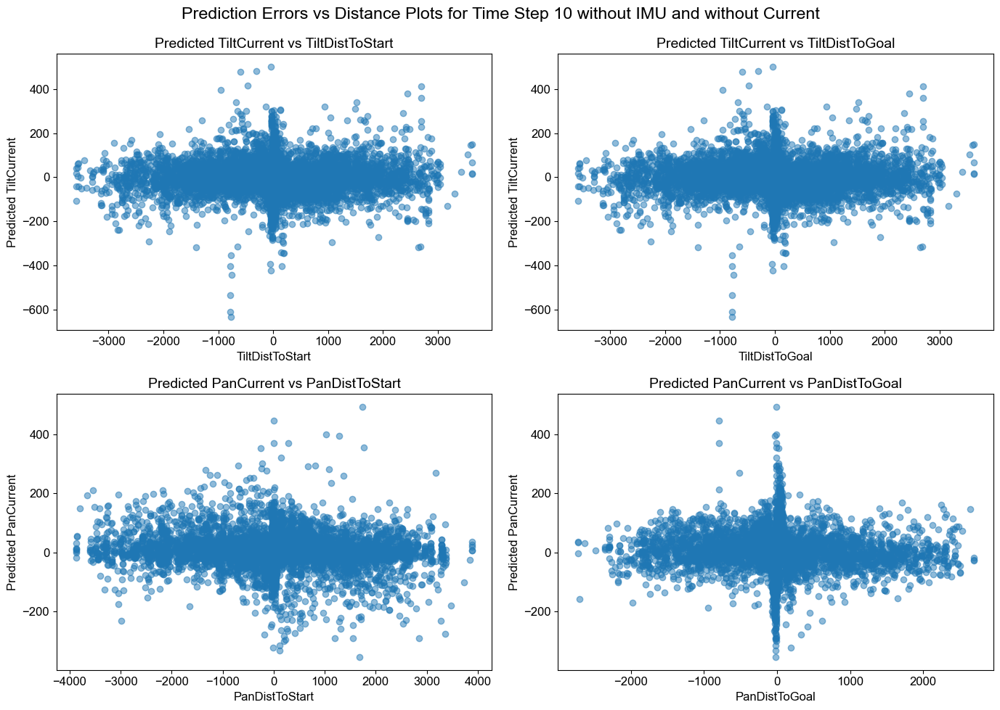

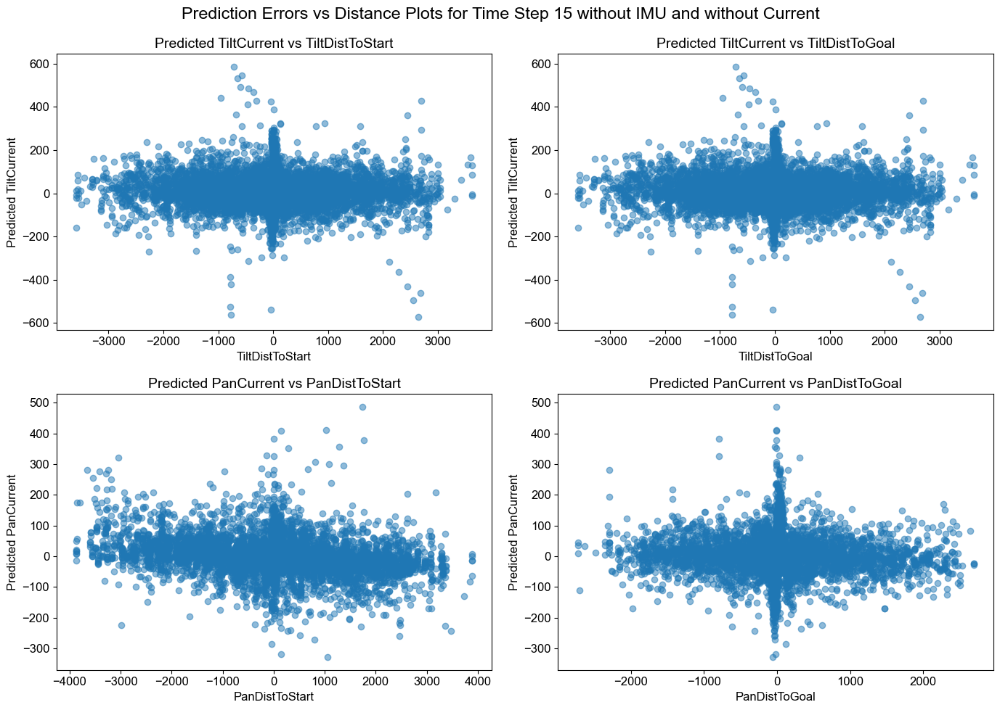

...

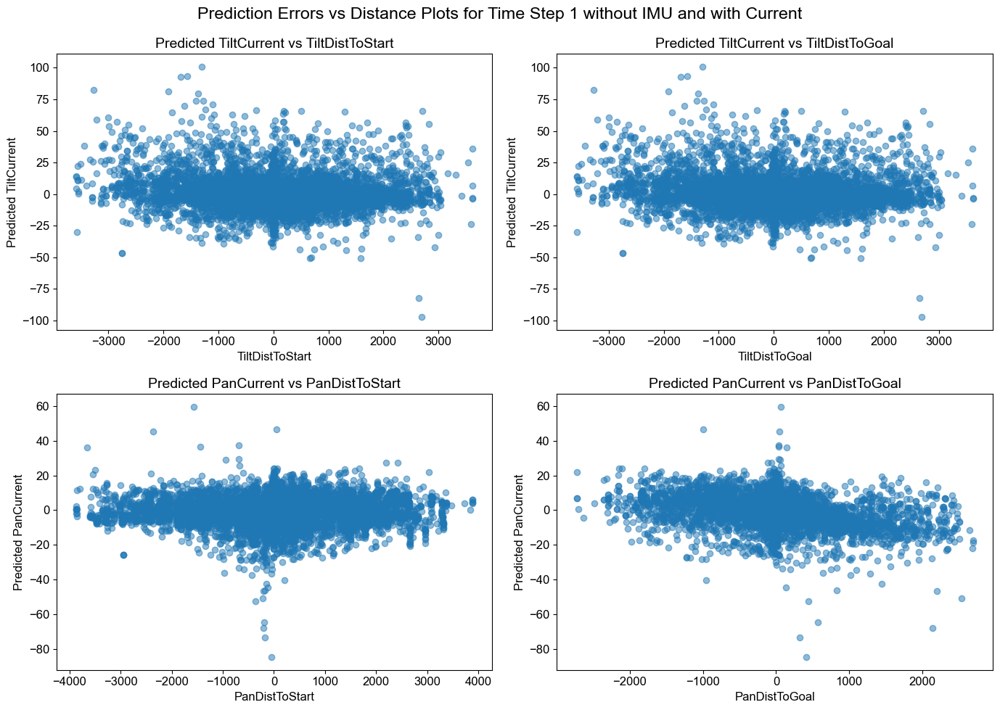

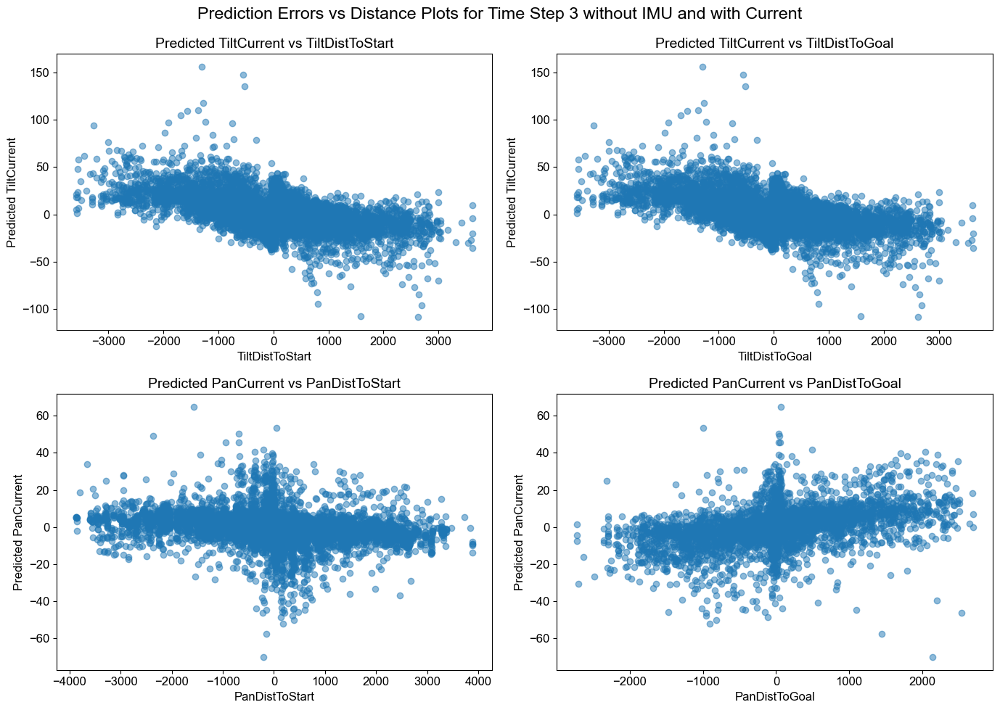

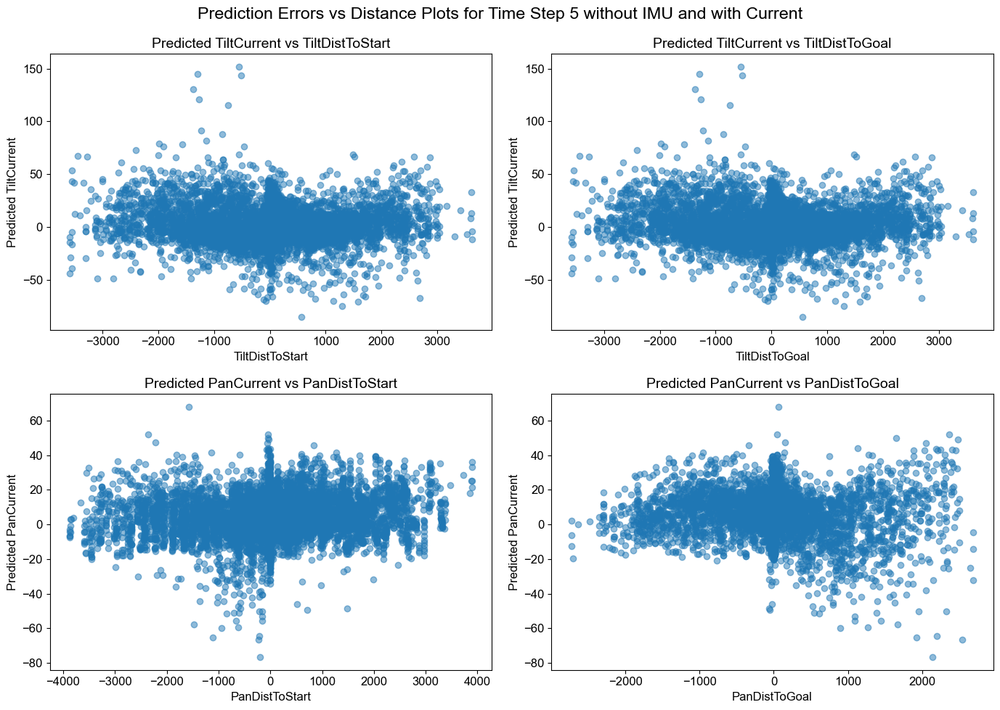

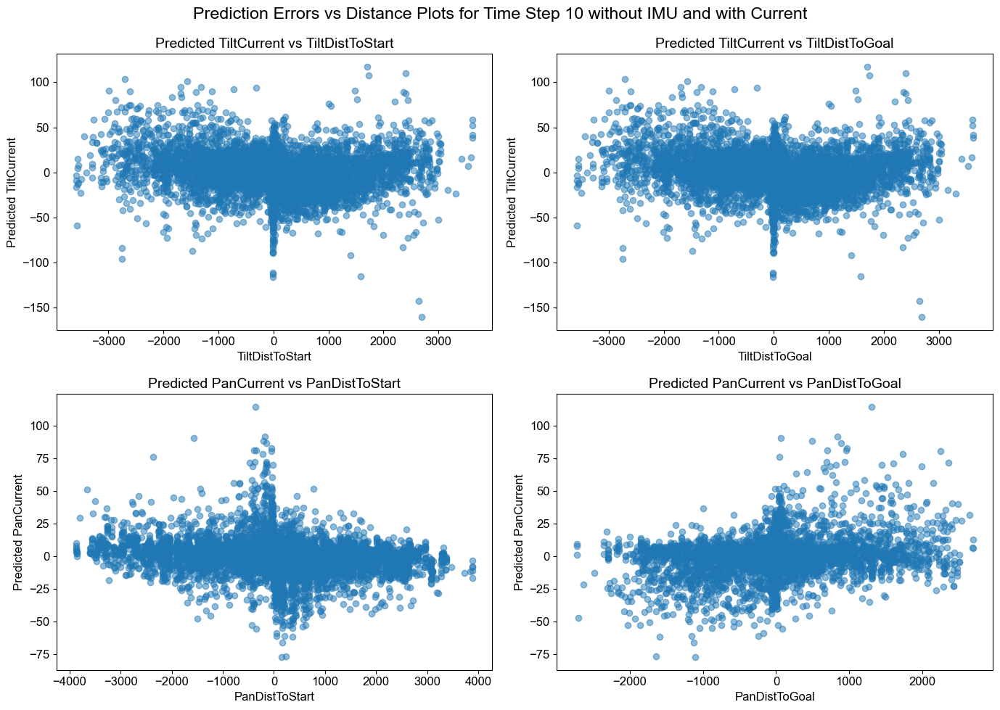

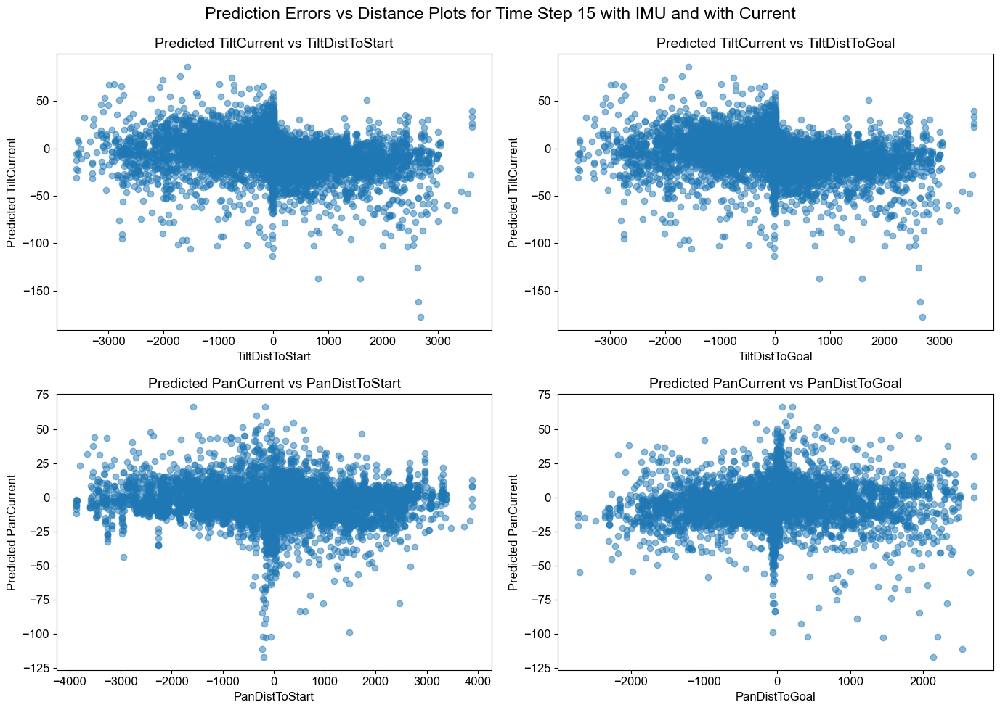

In [18]:
import tensorflow as tf
metrics = {}


for model in TS_models_lst:
    timestep = int(model.name.split('TimeSteps')[1].split('_')[0])

    features_in_use = features_no_IMU if 'no_IMU' in model.name else features

    if 'with_current' in model.name:
        features_in_use = features_no_imu_with_current
    IMU_model = True if 'no_IMU' not in model.name else False
    print(f"Evaluating model: {model.name} with time step {timestep} using features: {features_in_use}")

    if timestep >0:
        X_train_ts, X_test_ts, y_train_ts, y_test_ts = sequence_data(X_combined_train_scaled[features_in_use], X_combined_test_scaled[features_in_use], y_combined_train_scaled, y_combined_test_scaled, time_step=timestep)
    else:
        X_train_ts, X_test_ts, y_train_ts, y_test_ts= X_combined_train_scaled[features_in_use], X_combined_test_scaled[features_in_use], y_combined_train_scaled, y_combined_test_scaled

    predictions_scaled = model.predict(X_test_ts)
    predictions = predictions_scaled * mean_std.loc['std', targets].values + mean_std.loc['mean', targets].values
    X_test = X_combined_test[features_in_use]
    y_true = y_test_ts *  mean_std.loc['std', targets].values + mean_std.loc['mean', targets].values
    prediction_errors_distance_plots(predictions, y_true, X_test, mean_std, features_in_use, timestep, IMU_model=IMU_model, model_name=model.name)
    print("Pltos saved in ./plots/ folder")

   
    #using evaluate
    loss, mse = model.evaluate(X_test_ts, y_test_ts, verbose=0)
    print(f"Model: {model.name} - Loss: {loss}, MSE: {mse}")

    metrics[model.name] = {
        'Loss': float(loss),
        'MSE': float(mse)
    }




In [19]:
X_combined_test.shape

(7879, 23)

In [20]:
TS_15_no_IMU_with_current.name = 'temporal_mlp_TimeSteps15_no_IMU_with_current.keras'
TS_models_lst = [TS_1_no_IMU, TS_3_no_IMU, TS_5_no_IMU, TS_10_no_IMU, TS_15_no_IMU, TS_1, TS_3, TS_5, TS_10, TS_15, TS_1_no_IMU_with_current,  TS_3_no_IMU_with_current, TS_5_no_IMU_with_current, TS_10_no_IMU_with_current, TS_15_no_IMU_with_current]

single_step_models_lst = [TS_0_no_IMU, TS_0] 

all_models_lst = single_step_models_lst + TS_models_lst

In [21]:
for model in all_models_lst:
    timestep = int(model.name.split('TimeSteps')[1].split('_')[0])
    features_in_use = features_no_IMU if 'no_IMU' in model.name else features
    if 'with_current' in model.name:
        features_in_use = features_no_imu_with_current
    IMU_model = True if 'no_IMU' not in model.name else False
    print(f"Evaluating model: {model.name} with time step {timestep} using features: {features_in_use}")
     #using evaluate
    if timestep >0:
        X_train_ts, X_test_ts, y_train_ts, y_test_ts = sequence_data(X_combined_train_scaled[features_in_use], X_combined_test_scaled[features_in_use], y_combined_train_scaled, y_combined_test_scaled, time_step=timestep)
    else:
        X_train_ts, X_test_ts, y_train_ts, y_test_ts= X_combined_train_scaled[features_in_use], X_combined_test_scaled[features_in_use], y_combined_train_scaled, y_combined_test_scaled

    loss, mse = model.evaluate(X_test_ts, y_test_ts, verbose=0)
    print(f"Model: {model.name} - Loss: {loss}, MSE: {mse}")

    metrics[model.name] = {
        'Loss': float(loss),
        'MSE': float(mse)
    }

Evaluating model: temporal_mlp_TimeSteps0_no_IMU with time step 0 using features: ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
Model: temporal_mlp_TimeSteps0_no_IMU - Loss: 0.08259864151477814, MSE: 0.2566351294517517
Evaluating model: temporal_mlp_TimeSteps0 with time step 0 using features: ['GyroX', 'GyroY', 'GyroZ', 'AccelX', 'AccelY', 'AccelZ', 'AngleX', 'AngleY', 'AngleZ', 'TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
Model: temporal_mlp_TimeSteps0 - Loss: 0.045238591730594635, MSE: 0.1742619127035141
Evaluating model: temporal_mlp_TimeSteps1_no_IMU with time step 1 using features: ['TiltPosition', 'TiltDistToGoal', 'TiltDistToStart', 'PanPosition', 'PanDistToGoal', 'PanDistToStart']
Applying time-stepping to combined data...
Time-stepped Data Shapes:
X_train_ts: (31515, 1, 6)
X_test_ts: (7879, 1, 6)
y_train_ts_targets: (31515, 2)
y_test_ts_targets: (7879, 2)
Model: 

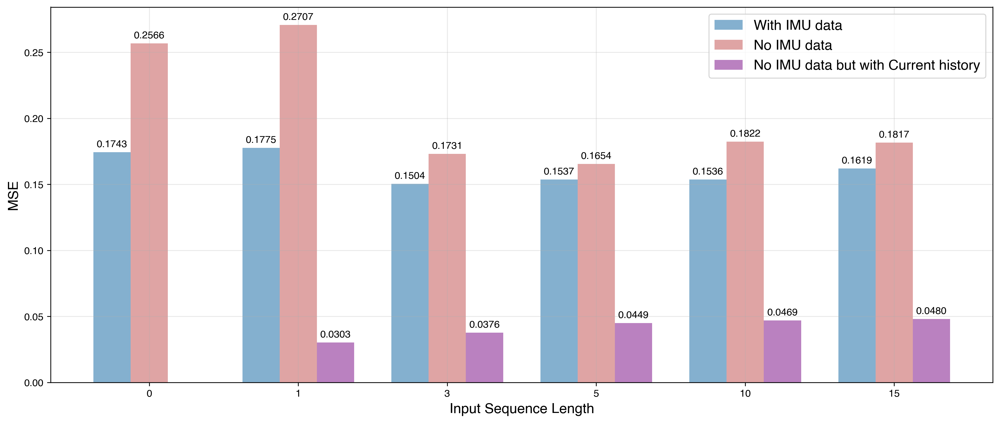


Comprehensive Summary Table:
Time Step | With IMU MSE | No IMU MSE | No IMU + Current MSE
----------------------------------------------------------------------
        0 | 0.1743       | 0.2566     | N/A             
        1 | 0.1775       | 0.2707     | 0.0303          
        3 | 0.1504       | 0.1731     | 0.0376          
        5 | 0.1537       | 0.1654     | 0.0449          
       10 | 0.1536       | 0.1822     | 0.0469          
       15 | 0.1619       | 0.1817     | 0.0480          

Model Availability Summary:
With IMU models available for timesteps: [0, 1, 3, 5, 10, 15]
No IMU models available for timesteps: [0, 1, 3, 5, 10, 15]
No IMU + Current models available for timesteps: [1, 3, 5, 10, 15]


In [75]:
metrics_df = pd.DataFrame(metrics).T

# Separate IMU and no_IMU models
imu_models = metrics_df[~metrics_df.index.str.contains('no_IMU') & ~metrics_df.index.str.contains('with_current')]
# Get models with 'no_IMU' but exclude those with 'with_current'
no_imu_models = metrics_df[metrics_df.index.str.contains('no_IMU') & ~metrics_df.index.str.contains('with_current')]
current_no_imu_models = metrics_df[metrics_df.index.str.contains('no_IMU_with_current')]


# Extract time steps from model names
def extract_timestep(model_name):
    return int(model_name.split('_TimeSteps')[1].split('_')[0])

# Create DataFrames with time steps as index
imu_df = pd.DataFrame(index=sorted(imu_models.index.map(extract_timestep).unique()))
no_imu_df = pd.DataFrame(index=sorted(no_imu_models.index.map(extract_timestep).unique()))
current_no_imu_models_df = pd.DataFrame(index=sorted(current_no_imu_models.index.map(extract_timestep).unique()))

# Fill in the MSE values
for file_name, row in imu_models.iterrows():
    timestep = extract_timestep(file_name)
    imu_df.loc[timestep, 'MSE'] = row['MSE']

for file_name, row in no_imu_models.iterrows():
    timestep = extract_timestep(file_name)
    no_imu_df.loc[timestep, 'MSE'] = row['MSE']

for file_name, row in current_no_imu_models.iterrows():
    timestep = extract_timestep(file_name)
    current_no_imu_models_df.loc[timestep, 'MSE'] = row['MSE']

# Create grouped bar plot with dynamic positioning
fig, ax = plt.subplots(figsize=(14, 6))

#plot font to helvetica
plt.rcParams['font.family'] = 'Helvetica'

# Get all unique timesteps across all model categories
all_timesteps = sorted(set(imu_df.index) | set(no_imu_df.index) | set(current_no_imu_models_df.index))
x = np.arange(len(all_timesteps))
width = 0.25  # Adjusted width for three categories

# Prepare data arrays with NaN for missing timesteps
imu_mse_values = [imu_df.loc[ts, 'MSE'] if ts in imu_df.index else np.nan for ts in all_timesteps]
no_imu_mse_values = [no_imu_df.loc[ts, 'MSE'] if ts in no_imu_df.index else np.nan for ts in all_timesteps]
current_no_imu_mse_values = [current_no_imu_models_df.loc[ts, 'MSE'] if ts in current_no_imu_models_df.index else np.nan for ts in all_timesteps]

# Create masks for existing data
imu_mask = ~np.isnan(imu_mse_values)
no_imu_mask = ~np.isnan(no_imu_mse_values)
current_no_imu_mask = ~np.isnan(current_no_imu_mse_values)

# Plot bars only where data exists
bars1 = ax.bar(x[imu_mask] - width, np.array(imu_mse_values)[imu_mask], width, 
               label='With IMU data', alpha=0.8, color="#659cc3")
bars2 = ax.bar(x[no_imu_mask], np.array(no_imu_mse_values)[no_imu_mask], width, 
               label='No IMU data', alpha=0.8, color="#D88D8D")
bars3 = ax.bar(x[current_no_imu_mask] + width, np.array(current_no_imu_mse_values)[current_no_imu_mask], width, 
               label='No IMU data but with Current history', alpha=0.8, color="#A962B1")

# Customize the plot
ax.set_xlabel('Input Sequence Length', fontsize=14)
ax.set_ylabel('MSE', fontsize=14)
#ax.set_title('Temporal MLP Evaluation Metrics: MSE by Time Steps and Model Types')
ax.set_xticks(x)
ax.set_xticklabels(all_timesteps)
ax.legend(fontsize=14)
ax.grid(True, alpha=0.3)

# Add value labels on bars - only for existing bars
def add_value_labels(bars):
    for bar in bars:
        if bar.get_height() > 0:  # Only add labels for visible bars
            height = bar.get_height()
            ax.annotate(f'{height:.4f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom',
                        fontsize=10)

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

plt.tight_layout()
plt.savefig('./plots/temporal_mlp_evaluation_metrics_comparison.jpeg', dpi=300)
plt.show()

# Also print a comprehensive summary table
print("\nComprehensive Summary Table:")
print("Time Step | With IMU MSE | No IMU MSE | No IMU + Current MSE")
print("-" * 70)
for ts in all_timesteps:
    imu_mse = f"{imu_df.loc[ts, 'MSE']:.4f}" if ts in imu_df.index else 'N/A'
    no_imu_mse = f"{no_imu_df.loc[ts, 'MSE']:.4f}" if ts in no_imu_df.index else 'N/A'
    current_mse = f"{current_no_imu_models_df.loc[ts, 'MSE']:.4f}" if ts in current_no_imu_models_df.index else 'N/A'
    print(f"{ts:9} | {imu_mse:12} | {no_imu_mse:10} | {current_mse:16}")

# Print model availability summary
print(f"\nModel Availability Summary:")
print(f"With IMU models available for timesteps: {sorted(imu_df.index.tolist())}")
print(f"No IMU models available for timesteps: {sorted(no_imu_df.index.tolist())}")
print(f"No IMU + Current models available for timesteps: {sorted(current_no_imu_models_df.index.tolist())}")

In [23]:
#get optimiser and loss function details for all models and print in a table
print("\nModel Optimizer and Loss Function Summary:")
print("Model Name | Optimizer | Loss Function")
print("-" * 50)
for model in all_models_lst:
    optimizer = model.optimizer.__class__.__name__
    loss_function = model.loss.__class__.__name__ if hasattr(model.loss, '__class__') else str(model.loss)
    print(f"{model.name:30} | {optimizer:10} | {loss_function:20}")


Model Optimizer and Loss Function Summary:
Model Name | Optimizer | Loss Function
--------------------------------------------------
temporal_mlp_TimeSteps0_no_IMU | Adam       | Huber               
temporal_mlp_TimeSteps0        | Adam       | Huber               
temporal_mlp_TimeSteps1_no_IMU | Adam       | Huber               
temporal_mlp_TimeSteps3_no_IMU | Adam       | Huber               
temporal_mlp_TimeSteps5_no_IMU | Adam       | Huber               
temporal_mlp_TimeSteps10_no_IMU | Adam       | Huber               
temporal_mlp_TimeSteps15_no_IMU | Adam       | Huber               
temporal_mlp_TimeSteps1        | Adam       | Huber               
temporal_mlp_TimeSteps3        | Adam       | Huber               
temporal_mlp_TimeSteps5        | Adam       | Huber               
temporal_mlp_TimeSteps10       | Adam       | Huber               
temporal_mlp_TimeSteps15       | Adam       | Huber               
temporal_mlp_TimeSteps1_no_IMU_with_current | Adam       | H

In [24]:
import pickle
import os

def get_epochs_from_history(model_name):
    """
    Load training history from pickle file and extract number of epochs.
    
    Args:
        model_name (str): Name of the model (without extension)
    
    Returns:
        int: Number of epochs trained, or None if file not found
    """
    history_file = f"../tMLP_models/history/history_{model_name}.pkl"
    
    if os.path.exists(history_file):
        try:
            with open(history_file, 'rb') as f:
                history = pickle.load(f)
            
            # The history object typically has a 'history' attribute with loss/metrics per epoch
            if hasattr(history, 'history'):
                epochs = len(history.history['loss'])
            elif isinstance(history, dict) and 'loss' in history:
                epochs = len(history['loss'])
            else:
                epochs = len(history) if isinstance(history, list) else None
                
            return epochs
        except Exception as e:
            print(f"Error loading history for {model_name}: {e}")
            return None
    else:
        print(f"History file not found: {history_file}")
        return None

# Get epochs for each model
model_epochs = {}
for model in all_models_lst:
    file_name = model.name
    epochs = get_epochs_from_history(file_name)
    model_epochs[file_name] = epochs
    print(f"{file_name}: {epochs} epochs")

# Add epochs to metrics
for file_name in metrics:
    if file_name in model_epochs:
        metrics[file_name]['Epochs'] = model_epochs[file_name]

temporal_mlp_TimeSteps0_no_IMU: 205 epochs
temporal_mlp_TimeSteps0: 137 epochs
temporal_mlp_TimeSteps1_no_IMU: 135 epochs
temporal_mlp_TimeSteps3_no_IMU: 107 epochs
temporal_mlp_TimeSteps5_no_IMU: 142 epochs
temporal_mlp_TimeSteps10_no_IMU: 108 epochs
temporal_mlp_TimeSteps15_no_IMU: 132 epochs
temporal_mlp_TimeSteps1: 148 epochs
temporal_mlp_TimeSteps3: 137 epochs
temporal_mlp_TimeSteps5: 117 epochs
temporal_mlp_TimeSteps10: 113 epochs
temporal_mlp_TimeSteps15: 155 epochs
temporal_mlp_TimeSteps1_no_IMU_with_current: 73 epochs
temporal_mlp_TimeSteps3_no_IMU_with_current: 129 epochs
temporal_mlp_TimeSteps5_no_IMU_with_current: 79 epochs
temporal_mlp_TimeSteps10_no_IMU_with_current: 84 epochs
History file not found: ../tMLP_models/history/history_temporal_mlp_TimeSteps15_no_IMU_with_current.keras.pkl
temporal_mlp_TimeSteps15_no_IMU_with_current.keras: None epochs



Detailed Summary Table:
Model Name                | Time Step | Model Type       | MSE     | Epochs
--------------------------------------------------------------------------------
temporal_mlp_TimeSteps1_no_IMU |         1 | No IMU           |  0.2707 | 135.0
temporal_mlp_TimeSteps3_no_IMU |         3 | No IMU           |  0.1731 | 107.0
temporal_mlp_TimeSteps5_no_IMU |         5 | No IMU           |  0.1654 | 142.0
temporal_mlp_TimeSteps10_no_IMU |        10 | No IMU           |  0.1822 | 108.0
temporal_mlp_TimeSteps15_no_IMU |        15 | No IMU           |  0.1817 | 132.0
temporal_mlp_TimeSteps1   |         1 | With IMU         |  0.1775 | 148.0
temporal_mlp_TimeSteps3   |         3 | With IMU         |  0.1504 | 137.0
temporal_mlp_TimeSteps5   |         5 | With IMU         |  0.1537 | 117.0
temporal_mlp_TimeSteps10  |        10 | With IMU         |  0.1536 | 113.0
temporal_mlp_TimeSteps15  |        15 | With IMU         |  0.1619 | 155.0
temporal_mlp_TimeSteps1_no_IMU_with_curre

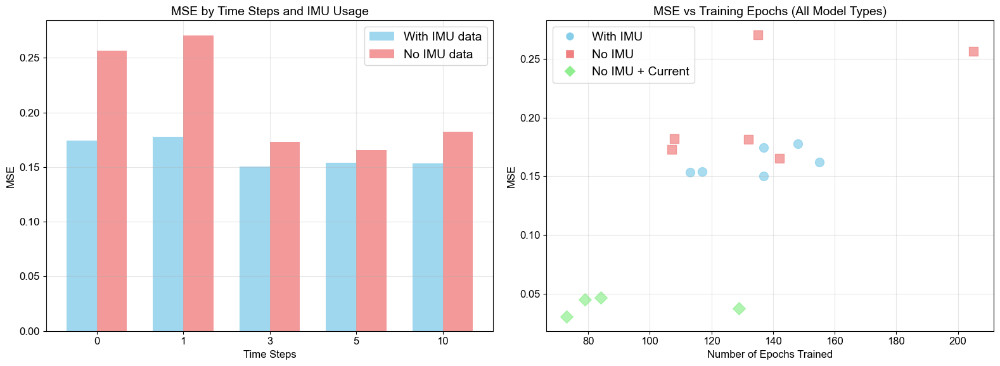

In [25]:
# Create an updated metrics DataFrame with epochs
metrics_with_epochs_df = pd.DataFrame(metrics).T

# Print detailed summary table including epochs
print("\nDetailed Summary Table:")
print("Model Name                | Time Step | Model Type       | MSE     | Epochs")
print("-" * 80)
for file_name, row in metrics_with_epochs_df.iterrows():
    timestep = int(file_name.split('TimeSteps')[1].split('_')[0])
    
    # Determine model type more specifically
    if 'no_IMU_with_current' in file_name:
        model_type = "No IMU + Current"
    elif 'no_IMU' in file_name:
        model_type = "No IMU"
    else:
        model_type = "With IMU"
    
    mse = row['MSE']
    epochs = row.get('Epochs', 'N/A')
    print(f"{file_name:<25} | {timestep:9} | {model_type:<16} | {mse:7.4f} | {epochs}")

# Create a plot showing MSE vs Epochs for comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: MSE vs Time Steps - separate into three categories
imu_models_updated = metrics_with_epochs_df[~metrics_with_epochs_df.index.str.contains('no_IMU')]
no_imu_pure_models = metrics_with_epochs_df[metrics_with_epochs_df.index.str.contains('no_IMU') & ~metrics_with_epochs_df.index.str.contains('with_current')]
no_imu_current_models = metrics_with_epochs_df[metrics_with_epochs_df.index.str.contains('no_IMU_with_current')]

# Remove time step 15 from imu_models for better comparison
imu_models_updated = imu_models_updated[~imu_models_updated.index.str.contains('TimeSteps15')]

# Extract time steps and create comparison DataFrames
imu_df_updated = pd.DataFrame(index=sorted(imu_models_updated.index.map(extract_timestep).unique()))
no_imu_pure_df = pd.DataFrame(index=sorted(no_imu_pure_models.index.map(extract_timestep).unique()))
no_imu_current_df = pd.DataFrame(index=sorted(no_imu_current_models.index.map(extract_timestep).unique()))

for file_name, row in imu_models_updated.iterrows():
    timestep = extract_timestep(file_name)
    imu_df_updated.loc[timestep, 'MSE'] = row['MSE']
    imu_df_updated.loc[timestep, 'Epochs'] = row.get('Epochs', 0)

for file_name, row in no_imu_pure_models.iterrows():
    timestep = extract_timestep(file_name)
    no_imu_pure_df.loc[timestep, 'MSE'] = row['MSE']
    no_imu_pure_df.loc[timestep, 'Epochs'] = row.get('Epochs', 0)

for file_name, row in no_imu_current_models.iterrows():
    timestep = extract_timestep(file_name)
    no_imu_current_df.loc[timestep, 'MSE'] = row['MSE']
    no_imu_current_df.loc[timestep, 'Epochs'] = row.get('Epochs', 0)

# First subplot: MSE vs Time Steps - using only common timesteps for cleaner comparison
common_timesteps = sorted(set(imu_df_updated.index) & set(no_imu_pure_df.index))
x = np.arange(len(common_timesteps))
width = 0.35

# Only plot the two main categories for cleaner comparison
imu_mse_common = [imu_df_updated.loc[ts, 'MSE'] for ts in common_timesteps]
no_imu_mse_common = [no_imu_pure_df.loc[ts, 'MSE'] for ts in common_timesteps]

bars1 = ax1.bar(x - width/2, imu_mse_common, width, label='With IMU data', alpha=0.8, color='skyblue')
bars2 = ax1.bar(x + width/2, no_imu_mse_common, width, label='No IMU data', alpha=0.8, color='lightcoral')

ax1.set_xlabel('Time Steps')
ax1.set_ylabel('MSE')
ax1.set_title('MSE by Time Steps and IMU Usage')
ax1.set_xticks(x)
ax1.set_xticklabels(common_timesteps)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Second subplot: MSE vs Epochs
# Scatter plot showing relationship between epochs and MSE - include all three categories
for file_name, row in metrics_with_epochs_df.iterrows():
    if row.get('Epochs') is not None:
        timestep = extract_timestep(file_name)
        
        # Determine color and marker based on model type
        if 'no_IMU_with_current' in file_name:
            color = 'lightgreen'
            marker = 'D'
            model_type = 'No IMU + Current'
        elif 'no_IMU' in file_name:
            color = 'lightcoral'
            marker = 's'
            model_type = 'No IMU'
        else:
            color = 'skyblue'
            marker = 'o'
            model_type = 'With IMU'
            
        ax2.scatter(row['Epochs'], row['MSE'], color=color, s=100, alpha=0.7, marker=marker,
                   label=f"TS{timestep} {model_type}")

ax2.set_xlabel('Number of Epochs Trained')
ax2.set_ylabel('MSE')
ax2.set_title('MSE vs Training Epochs (All Model Types)')
ax2.grid(True, alpha=0.3)

# Create custom legend for the second plot with all three categories
imu_line = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='skyblue', markersize=10, label='With IMU')
no_imu_line = plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='lightcoral', markersize=10, label='No IMU')
current_line = plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='lightgreen', markersize=10, label='No IMU + Current')
ax2.legend(handles=[imu_line, no_imu_line, current_line])

plt.tight_layout()
plt.savefig('./plots/temporal_mlp_comprehensive_analysis.jpeg', dpi=300, bbox_inches='tight')
plt.show()

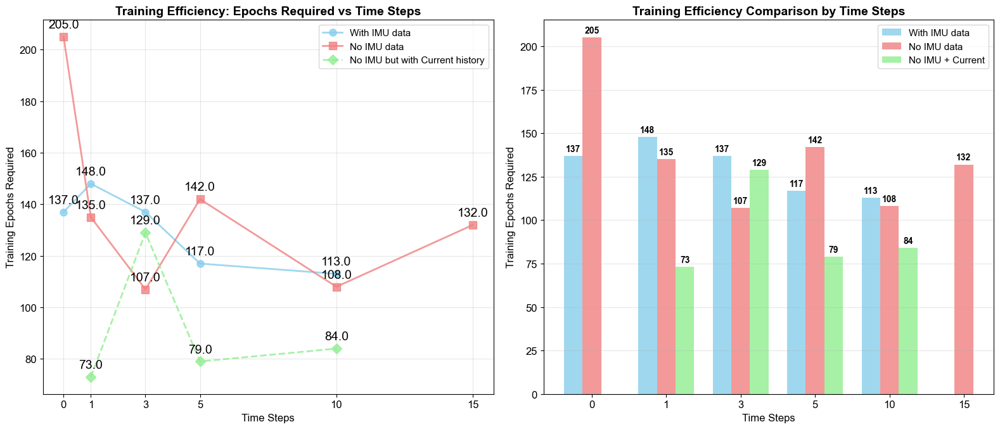


TRAINING EFFICIENCY ANALYSIS

Epochs Required for Convergence:
----------------------------------------------------------------------
Time Step | With IMU | No IMU | No IMU+Current | IMU vs NoIMU | IMU vs Current
----------------------------------------------------------------------
        0 | 137.0    | 205.0  | N/A            | +68.0        | N/A        
        1 | 148.0    | 135.0  | 73.0           | -13.0        | -75.0      
        3 | 137.0    | 107.0  | 129.0          | -30.0        | -8.0       
        5 | 117.0    | 142.0  | 79.0           | +25.0        | -38.0      
       10 | 113.0    | 108.0  | 84.0           | -5.0         | -29.0      
       15 | N/A      | 132.0  | nan            | N/A          | N/A        

Model Availability by Time Step:
• With IMU models: [0, 1, 3, 5, 10]
• No IMU models: [0, 1, 3, 5, 10, 15]
• No IMU + Current models: [1, 3, 5, 10, 15]

Key Insights:
• Positive difference = Second model needed MORE epochs than first
• Negative difference = 

In [26]:
# Create a dedicated plot showing how IMU data and time steps affected training
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Prepare data for plotting
imu_epochs = []
no_imu_epochs = []
with_current_epochs = []
imu_timesteps = []
no_imu_timesteps = []
with_current_timesteps = []

for file_name, row in metrics_with_epochs_df.iterrows():
    if row.get('Epochs') is not None:
        timestep = extract_timestep(file_name)
        epochs = row['Epochs']
        
        if 'no_IMU' in file_name and 'with_current' not in file_name:
            no_imu_epochs.append(epochs)
            no_imu_timesteps.append(timestep)
        elif 'no_IMU_with_current' in file_name:
            with_current_epochs.append(epochs)
            with_current_timesteps.append(timestep)
        else:
            # Skip timestep 15 for better comparison
            if timestep != 15:
                imu_epochs.append(epochs)
                imu_timesteps.append(timestep)
    
imu_epochs, imu_timesteps = zip(*sorted(zip(imu_epochs, imu_timesteps), key=lambda x: x[1]))
no_imu_epochs, no_imu_timesteps = zip(*sorted(zip(no_imu_epochs, no_imu_timesteps), key=lambda x: x[1]))
with_current_epochs, with_current_timesteps = zip(*sorted(zip(with_current_epochs, with_current_timesteps), key=lambda x: x[1]))

# Plot 1: Epochs vs Time Steps (Line plot)
ax1.plot(imu_timesteps, imu_epochs, 'o-', color='skyblue', linewidth=2, markersize=8, 
         label='With IMU data', alpha=0.8)
ax1.plot(no_imu_timesteps, no_imu_epochs, 's-', color='lightcoral', linewidth=2, markersize=8, 
         label='No IMU data', alpha=0.8)
ax1.plot(with_current_timesteps, with_current_epochs, 'D--', color='lightgreen', linewidth=2, markersize=8, 
         label='No IMU but with Current history', alpha=0.8)

ax1.set_xlabel('Time Steps')
ax1.set_ylabel('Training Epochs Required')
ax1.set_title('Training Efficiency: Epochs Required vs Time Steps', fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(sorted(set(imu_timesteps + no_imu_timesteps)))

# Add value labels on points
for i, (ts, epochs) in enumerate(zip(imu_timesteps, imu_epochs)):
    ax1.annotate(f'{epochs}', (ts, epochs), textcoords="offset points", 
                xytext=(0,10), ha='center')
for i, (ts, epochs) in enumerate(zip(no_imu_timesteps, no_imu_epochs)):
    ax1.annotate(f'{epochs}', (ts, epochs), textcoords="offset points", 
                xytext=(0,10), ha='center')
for i, (ts, epochs) in enumerate(zip(with_current_timesteps, with_current_epochs)):
    ax1.annotate(f'{epochs}', (ts, epochs), textcoords="offset points", 
                xytext=(0,10), ha='center')

# Plot 2: Training Efficiency Bar Chart (Epochs grouped by time step)
# Create grouped bar chart for epochs - include all three categories
timesteps_all = sorted(set(imu_timesteps) | set(no_imu_timesteps) | set(with_current_timesteps))

# Prepare data arrays with NaN for missing timesteps
imu_epochs_ordered = [imu_epochs[imu_timesteps.index(ts)] if ts in imu_timesteps else np.nan for ts in timesteps_all]
no_imu_epochs_ordered = [no_imu_epochs[no_imu_timesteps.index(ts)] if ts in no_imu_timesteps else np.nan for ts in timesteps_all]
with_current_epochs_ordered = [with_current_epochs[with_current_timesteps.index(ts)] if ts in with_current_timesteps else np.nan for ts in timesteps_all]

x2 = np.arange(len(timesteps_all))
width = 0.25  # Adjusted width for three categories

# Create masks for existing data
imu_mask = ~np.isnan(imu_epochs_ordered)
no_imu_mask = ~np.isnan(no_imu_epochs_ordered)
with_current_mask = ~np.isnan(with_current_epochs_ordered)

# Plot bars only where data exists
bars1 = ax2.bar(x2[imu_mask] - width, np.array(imu_epochs_ordered)[imu_mask], width, 
                label='With IMU data', alpha=0.8, color='skyblue')
bars2 = ax2.bar(x2[no_imu_mask], np.array(no_imu_epochs_ordered)[no_imu_mask], width, 
                label='No IMU data', alpha=0.8, color='lightcoral')
bars3 = ax2.bar(x2[with_current_mask] + width, np.array(with_current_epochs_ordered)[with_current_mask], width, 
                label='No IMU + Current', alpha=0.8, color='lightgreen')



ax2.set_xlabel('Time Steps')
ax2.set_ylabel('Training Epochs Required')
ax2.set_title('Training Efficiency Comparison by Time Steps', fontweight='bold')
ax2.set_xticks(x2)
ax2.set_xticklabels(timesteps_all)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
def add_value_labels_epochs(bars, ax):
    for bar in bars:
        if bar.get_height() > 0:  # Only add labels for visible bars
            height = bar.get_height()
            ax.annotate(f'{int(height)}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom',
                        fontsize=10, fontweight='bold')

add_value_labels_epochs(bars1, ax2)
add_value_labels_epochs(bars2, ax2)
add_value_labels_epochs(bars3, ax2)

plt.tight_layout()
plt.savefig('./plots/training_efficiency_analysis.jpeg', dpi=300, bbox_inches='tight')
plt.show()

# Print analysis summary
print("\n" + "="*80)
print("TRAINING EFFICIENCY ANALYSIS")
print("="*80)
print("\nEpochs Required for Convergence:")
print("-" * 70)
print("Time Step | With IMU | No IMU | No IMU+Current | IMU vs NoIMU | IMU vs Current")
print("-" * 70)

for ts in timesteps_all:
    # Get epochs for each category (if available)
    imu_ep = imu_epochs[imu_timesteps.index(ts)] if ts in imu_timesteps else None
    no_imu_ep = no_imu_epochs[no_imu_timesteps.index(ts)] if ts in no_imu_timesteps else None
    current_ep = with_current_epochs[with_current_timesteps.index(ts)] if ts in with_current_timesteps else None
    
    # Format values
    imu_str = f"{imu_ep:3}" if imu_ep is not None else "N/A"
    no_imu_str = f"{no_imu_ep:3}" if no_imu_ep is not None else "N/A"
    current_str = f"{current_ep:3}" if current_ep is not None else "N/A"
    
    # Calculate differences
    diff1_str = f"{no_imu_ep - imu_ep:+3}" if (imu_ep is not None and no_imu_ep is not None) else "N/A"
    diff2_str = f"{current_ep - imu_ep:+3}" if (imu_ep is not None and current_ep is not None) else "N/A"
    
    print(f"{ts:9} | {imu_str:8} | {no_imu_str:6} | {current_str:14} | {diff1_str:12} | {diff2_str:11}")

print("\nModel Availability by Time Step:")
print(f"• With IMU models: {sorted(imu_timesteps)}")
print(f"• No IMU models: {sorted(no_imu_timesteps)}")
print(f"• No IMU + Current models: {sorted(with_current_timesteps)}")

print("\nKey Insights:")
print("• Positive difference = Second model needed MORE epochs than first")
print("• Negative difference = Second model needed FEWER epochs than first")
print("• Current data can help compensate for missing IMU information in training efficiency")

# Prediction Error Plots

## load data


In [27]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

model_name = "temporal_mlp_TimeSteps3_no_IMU_with_current"

In [28]:


#combine json files containing in moving_data folder into a single dataframe
def load_json_folder_to_dataframe(folder_path, header_key=None):
    """
    Load all JSON files in a folder into one DataFrame.

    Args:
        folder_path (str): Path to folder containing JSON files.
        header_key (str | None): JSON top-level key containing the list of records.
                                 If None, the function auto-detects a suitable key.

    Returns:
        pd.DataFrame
    """
    all_data = []

    if not os.path.exists(folder_path):
        print(f"Folder not found: {folder_path}")
        return pd.DataFrame()

    def infer_header_key(data):
        # Prefer keys with list-of-dict values, choose longest list
        candidates = [
            (k, v) for k, v in data.items()
            if isinstance(v, list) and (len(v) == 0 or isinstance(v[0], dict))
        ]
        if not candidates:
            return None
        return max(candidates, key=lambda kv: len(kv[1]))[0]

    print(f"Loading JSON files from: {folder_path}")

    for filename in os.listdir(folder_path):
        if not filename.endswith(".json"):
            continue

        file_path = os.path.join(folder_path, filename)
        try:
            with open(file_path, "r") as f:
                data = json.load(f)

            key = header_key if header_key is not None else infer_header_key(data)
            if key is None or key not in data or not isinstance(data[key], list):
                print(f"Skipping {filename}: no valid list header found")
                continue

            for entry in data[key]:
                if isinstance(entry, dict):
                    row = entry.copy()
                    row["source_file"] = filename
                    row["json_header"] = key
                    all_data.append(row)

        except Exception as e:
            print(f"Error loading {filename}: {e}")

    if not all_data:
        print("No JSON records loaded.")
        return pd.DataFrame()
    else:
        print(f"Loaded {len(all_data)} records from {folder_path}")

    return pd.DataFrame(all_data)


moving_data_df = load_json_folder_to_dataframe(f"{model_name}/moving_mode/")
static_data_df = load_json_folder_to_dataframe(f"{model_name}/static_mode/")


Loading JSON files from: temporal_mlp_TimeSteps3_no_IMU_with_current/moving_mode/
Loaded 11144 records from temporal_mlp_TimeSteps3_no_IMU_with_current/moving_mode/
Loading JSON files from: temporal_mlp_TimeSteps3_no_IMU_with_current/static_mode/
Loaded 17229 records from temporal_mlp_TimeSteps3_no_IMU_with_current/static_mode/


In [29]:
moving_data_df.head()

,tick,time,transition,perturbation_type,phase_elapsed,present_position,goal_position,present_current,model_prediction,gyro,accel,euler_angles,starting_positions,source_file,json_header
0,3,0.076,0,obstacle,0.026,"[180.4395, 152.0508]","[180.0, 150.0]","[0.0, 0.0]","[0.0, 0.0]","[-0.1881, 0.4279, -0.4279]","[0.1326, -0.0862, -0.9533]","[5.0757, 8.1299, -21.4453]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
1,4,0.100,0,obstacle,0.050,"[180.3516, 152.0508]","[180.0, 150.0]","[0.0, 0.0]","[0.0, 0.0]","[-0.0966, 0.5796, -0.3361]","[0.1331, -0.0858, -0.9529]","[5.0647, 8.1299, -21.4563]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
2,5,0.125,0,obstacle,0.075,"[180.3516, 152.0508]","[180.0, 150.0]","[-16.8, -60.48]","[18.5611, 24.0088]","[-0.0347, 0.4562, -0.4298]","[0.1333, -0.0855, -0.9529]","[5.0647, 8.1299, -21.4673]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
3,6,0.151,0,obstacle,0.101,"[180.4395, 151.875]","[180.0, 150.0]","[-191.52, -144.48]","[24.6803, -78.7653]","[-0.2193, 0.4241, -0.3681]","[0.1328, -0.0856, -0.9528]","[5.0647, 8.1299, -21.4783]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
4,7,0.175,0,obstacle,0.125,"[180.4395, 151.3477]","[180.0, 150.0]","[-215.04, -20.16]","[-18.3506, -148.5378]","[-0.1272, 0.5798, -0.3982]","[0.1332, -0.0858, -0.9523]","[5.0647, 8.1299, -21.4893]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data


In [30]:
non_perturbed_df = moving_data_df[moving_data_df['perturbation_type']=='none']
static_push_df = static_data_df[static_data_df['perturbation_type']=='push']
static_sustained_df = static_data_df[static_data_df['perturbation_type']=='sustained']

In [31]:
def plot_all_transitions(tilt_df, pan_df, title_suffix='', save_suffix='', figsize=(15, 12)):
    """
    Plot all transitions for both tilt and pan motors.
    
    Args:
        tilt_df (pd.DataFrame): DataFrame containing tilt motor data
        pan_df (pd.DataFrame): DataFrame containing pan motor data
        title_suffix (str): Additional text to add to the plot title
        save_suffix (str): Additional text to add to the saved filename
        figsize (tuple): Figure size (width, height)
    
    Returns:
        None (saves plot to file and displays it)
    """
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize)

    def plot_motor(ax, df, current_index, title, ylabel):
        if df.empty:
            ax.set_xlabel('Phase Elapsed')
            ax.set_ylabel(ylabel)
            ax.set_title(title, fontweight='bold')
            ax.grid(True, alpha=0.3)
            return 0

        group_columns = ['transition']
        if 'source_file' in df.columns:
            group_columns.insert(0, 'source_file')

        sorted_df = df.sort_values(group_columns + ['phase_elapsed'])
        grouped = sorted_df.groupby(group_columns, sort=True, observed=True)

        groups_plotted = 0
        for _, transition_data in grouped:
            motor_current = transition_data['present_current'].apply(
                lambda x: x[current_index] if isinstance(x, (list, tuple, np.ndarray)) and len(x) > current_index else np.nan
            )

            valid_mask = motor_current.notna()
            if valid_mask.any():
                ax.plot(
                    transition_data.loc[valid_mask, 'phase_elapsed'],
                    motor_current.loc[valid_mask],
                    alpha=0.6,
                    linewidth=1.5,
                )
                groups_plotted += 1

        ax.set_xlabel('Phase Elapsed')
        ax.set_ylabel(ylabel)
        ax.set_title(title, fontweight='bold')
        ax.grid(True, alpha=0.3)
        return groups_plotted

    tilt_groups = plot_motor(
        ax1,
        tilt_df,
        current_index=0,
        title=f'Tilt Motor - All Transitions{title_suffix}',
        ylabel='Tilt Current (mA)'
    )
    pan_groups = plot_motor(
        ax2,
        pan_df,
        current_index=1,
        title=f'Pan Motor - All Transitions{title_suffix}',
        ylabel='Pan Current (mA)'
    )

    plt.tight_layout()

    filename = f'./plots/all_transitions_tilt_and_pan{save_suffix}.jpeg'
    os.makedirs('./plots', exist_ok=True)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\nPlot Summary:")
    print(f"Tilt Motor: {tilt_groups} transition runs plotted")
    print(f"Pan Motor: {pan_groups} transition runs plotted")
    print(f"Saved to: {filename}")

In [32]:
# Check the structure of the dataframe
print("Columns:", static_data_df.columns.tolist())
print("\nUnique transitions:", static_data_df['transition'].nunique())

print("\nFirst few rows:")
static_data_df.head()

Columns: ['transition', 'tick', 'time', 'perturbation_type', 'phase_elapsed', 'present_position', 'goal_position', 'present_current', 'model_prediction', 'gyro', 'accel', 'euler_angles', 'source_file', 'json_header']

Unique transitions: 60

First few rows:


,transition,tick,time,perturbation_type,phase_elapsed,present_position,goal_position,present_current,model_prediction,gyro,accel,euler_angles,source_file,json_header
0,0,42,1.050,sustained,0.024,"[174.9023, 179.9121]","[174.8145, 179.9121]","[0.0, 0.0]","[-12.4078, 2.1849]","[0.0855, 0.9756, 0.0292]","[0.1997, -0.0323, -0.9496]","[1.9116, 12.1619, -124.1785]",tilt_static_mode_log_20260420_103929_sustained...,static_push_data
1,0,43,1.075,sustained,0.049,"[174.9023, 179.9121]","[174.8145, 179.9121]","[0.0, 0.0]","[-12.4022, 2.1892]","[-0.2795, 0.6105, -0.2431]","[0.2023, -0.0335, -0.95]","[1.9116, 12.1619, -124.1785]",tilt_static_mode_log_20260420_103929_sustained...,static_push_data
2,0,44,1.100,sustained,0.074,"[174.9023, 179.9121]","[174.8145, 179.9121]","[0.0, 0.0]","[-12.388, 2.1855]","[-0.1283, -0.061, -0.641]","[0.2026, -0.0327, -0.9501]","[1.9116, 12.1619, -124.2004]",tilt_static_mode_log_20260420_103929_sustained...,static_push_data
3,0,45,1.125,sustained,0.099,"[174.9023, 179.9121]","[174.8145, 179.9121]","[0.0, 0.0]","[-12.378, 2.1856]","[-0.1278, 0.5767, -0.2175]","[0.2, -0.0332, -0.9505]","[1.9116, 12.1619, -124.2004]",tilt_static_mode_log_20260420_103929_sustained...,static_push_data
4,0,46,1.150,sustained,0.124,"[174.9023, 179.9121]","[174.8145, 179.9121]","[0.0, 0.0]","[-12.3707, 2.1857]","[-0.311, 0.5792, -0.489]","[0.2008, -0.0335, -0.9507]","[1.9116, 12.1619, -124.2114]",tilt_static_mode_log_20260420_103929_sustained...,static_push_data


In [33]:
def plot_all_transitions_grouped(df, motor='tilt', title_suffix='', save_suffix='', figsize=(15, 10)):
    """
    Plot all transitions for a motor, grouped by transition and model name.
    Multiple runs with the same transition are averaged within each model.
    
    Args:
        df (pd.DataFrame): DataFrame containing motor data with 'transition', 'model_name', 
                          'phase_elapsed', and 'present_current' columns
        motor (str): Which motor to plot ('tilt' or 'pan')
        title_suffix (str): Additional text to add to the plot title
        save_suffix (str): Additional text to add to the saved filename
        figsize (tuple): Figure size (width, height)
    
    Returns:
        None (saves plot to file and displays it)
    """
    import matplotlib.pyplot as plt
    import numpy as np
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Get unique transitions and model names
    unique_transitions = sorted(df['transition'].unique())
    unique_source_files = sorted(df['source_file'].unique())
    
    print(f"\nFound {len(unique_transitions)} unique transitions")
    print(f"Found {len(unique_source_files)} unique files: {unique_source_files}")
    
    # Determine which current index to use (0 for tilt, 1 for pan)
    current_index = 0 if motor.lower() == 'tilt' else 1
    
    # Generate colors for each model
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_source_files)))
    
    # Track statistics
    total_groups_plotted = 0
    
    # Group by transition and model_name, then plot each group
    for transition in unique_transitions:
        transition_df = df[df['transition'] == transition]
        
        for model_idx, file_name in enumerate(unique_source_files):
            model_transition_df = transition_df[transition_df['source_file'] == file_name]
            
            if len(model_transition_df) > 0:
                # Extract current values
                current_values = [row[current_index] for row in model_transition_df['present_current']]
                
                # Plot this group
                label = f'{file_name} - T{transition}' if len(unique_transitions) <= 10 else None
                ax.plot(model_transition_df['phase_elapsed'], current_values, 
                       alpha=0.5, linewidth=1.2, color=colors[model_idx], label=label)
                
                total_groups_plotted += 1
    
    motor_title = motor.capitalize()
    ax.set_xlabel('Phase Elapsed')
    ax.set_ylabel(f'{motor_title} Current (mA)')
    ax.set_title(f'{motor_title} Motor - All Transitions by Model{title_suffix}', 
                fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add legend if not too many items
    if len(unique_transitions) <= 10:
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    
    # Save the plot
    filename = f'./plots/all_transitions_{motor}_grouped{save_suffix}.jpeg'
    os.makedirs('./plots', exist_ok=True)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nPlot Summary:")
    print(f"Motor: {motor_title}")
    print(f"Total transition-model combinations plotted: {total_groups_plotted}")
    print(f"Saved to: {filename}")
    
    return fig, ax

In [34]:
static_push_df

,transition,tick,time,perturbation_type,phase_elapsed,present_position,goal_position,present_current,model_prediction,gyro,accel,euler_angles,source_file,json_header
4000,0,42,1.050,push,0.024,"[180.0879, 182.1973]","[180.0879, 182.1973]","[0.0, 0.0]","[-11.8583, 2.5706]","[-0.2193, 0.519, -0.4265]","[0.1442, -0.0244, -0.9572]","[1.3513, 8.7891, -303.4424]",tilt_static_mode_log_20260420_104743_push.json,static_push_data
4001,0,43,1.075,push,0.049,"[180.0, 182.1973]","[180.0879, 182.1973]","[0.0, 0.0]","[-11.8775, 2.5776]","[-0.3119, 0.1807, -0.4264]","[0.1458, -0.0247, -0.958]","[1.3513, 8.7891, -303.4534]",tilt_static_mode_log_20260420_104743_push.json,static_push_data
4002,0,44,1.100,push,0.074,"[180.0, 182.1094]","[180.0879, 182.1973]","[0.0, -3.36]","[-11.8863, 2.5834]","[-0.3412, 0.3658, -0.3052]","[0.1442, -0.0249, -0.958]","[1.3513, 8.7891, -303.4534]",tilt_static_mode_log_20260420_104743_push.json,static_push_data
4003,0,45,1.125,push,0.099,"[180.0, 182.1973]","[180.0879, 182.1973]","[0.0, 0.0]","[-11.8143, -0.7193]","[-0.2201, 0.581, -0.3657]","[0.144, -0.0248, -0.958]","[1.3513, 8.7781, -303.4644]",tilt_static_mode_log_20260420_104743_push.json,static_push_data
4004,0,46,1.150,push,0.124,"[180.0879, 182.1973]","[180.0879, 182.1973]","[0.0, 0.0]","[-11.8381, 2.5613]","[-0.4011, 0.7622, -0.4299]","[0.1432, -0.0252, -0.9579]","[1.3513, 8.7781, -303.4753]",tilt_static_mode_log_20260420_104743_push.json,static_push_data
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17224,12,2053,51.325,push,1.900,"[180.7031, 182.6367]","[180.4395, 182.373]","[0.0, 0.0]","[-11.7456, 2.6604]","[-0.1583, 0.0617, -0.6104]","[0.1266, -0.0252, -0.9603]","[1.3623, 7.6904, -24.2688]",tilt_static_mode_log_20260420_105123_push.json,static_push_data
17225,12,2054,51.350,push,1.925,"[180.7031, 182.5488]","[180.4395, 182.373]","[0.0, 0.0]","[-11.739, 2.6614]","[-0.2497, 0.3963, -0.5804]","[0.1251, -0.0261, -0.9608]","[1.3733, 7.6794, -24.2908]",tilt_static_mode_log_20260420_105123_push.json,static_push_data
17226,12,2055,51.375,push,1.950,"[180.7031, 182.5488]","[180.4395, 182.373]","[0.0, 0.0]","[-11.7466, 2.6538]","[-0.249, 1.0969, -0.1231]","[0.1235, -0.0256, -0.9607]","[1.3733, 7.6794, -24.3018]",tilt_static_mode_log_20260420_105123_push.json,static_push_data
17227,12,2056,51.401,push,1.976,"[180.7031, 182.5488]","[180.4395, 182.373]","[3.36, 0.0]","[-11.7401, 2.6585]","[-0.3107, 0.4269, -0.2738]","[0.1248, -0.0239, -0.9597]","[1.3733, 7.6794, -24.3018]",tilt_static_mode_log_20260420_105123_push.json,static_push_data



Found 50 unique transitions
Found 2 unique files: ['pan_static_mode_log_20260413_111415_sustained.json', 'tilt_static_mode_log_20260420_103929_sustained.json']


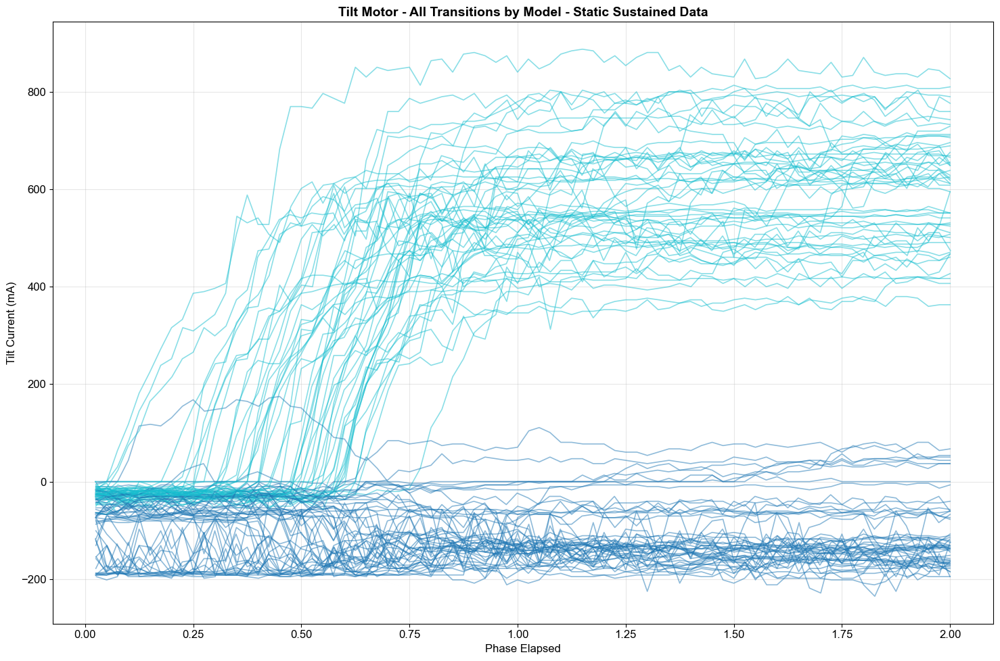


Plot Summary:
Motor: Tilt
Total transition-model combinations plotted: 100
Saved to: ./plots/all_transitions_tilt_grouped_static_sustained{model_name}.jpeg


(<Figure size 1500x1000 with 1 Axes>,
 <Axes: title={'center': 'Tilt Motor - All Transitions by Model - Static Sustained Data'}, xlabel='Phase Elapsed', ylabel='Tilt Current (mA)'>)

In [35]:
static_sustained_df = static_data_df[static_data_df['perturbation_type']=='sustained']
plot_all_transitions_grouped(static_sustained_df, motor='tilt', title_suffix=' - Static Sustained Data', save_suffix='_static_sustained{model_name}', figsize=(15, 10))

In [36]:
moving_data_df

,tick,time,transition,perturbation_type,phase_elapsed,present_position,goal_position,present_current,model_prediction,gyro,accel,euler_angles,starting_positions,source_file,json_header
0,3,0.076,0,obstacle,0.026,"[180.4395, 152.0508]","[180.0, 150.0]","[0.0, 0.0]","[0.0, 0.0]","[-0.1881, 0.4279, -0.4279]","[0.1326, -0.0862, -0.9533]","[5.0757, 8.1299, -21.4453]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
1,4,0.100,0,obstacle,0.050,"[180.3516, 152.0508]","[180.0, 150.0]","[0.0, 0.0]","[0.0, 0.0]","[-0.0966, 0.5796, -0.3361]","[0.1331, -0.0858, -0.9529]","[5.0647, 8.1299, -21.4563]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
2,5,0.125,0,obstacle,0.075,"[180.3516, 152.0508]","[180.0, 150.0]","[-16.8, -60.48]","[18.5611, 24.0088]","[-0.0347, 0.4562, -0.4298]","[0.1333, -0.0855, -0.9529]","[5.0647, 8.1299, -21.4673]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
3,6,0.151,0,obstacle,0.101,"[180.4395, 151.875]","[180.0, 150.0]","[-191.52, -144.48]","[24.6803, -78.7653]","[-0.2193, 0.4241, -0.3681]","[0.1328, -0.0856, -0.9528]","[5.0647, 8.1299, -21.4783]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
4,7,0.175,0,obstacle,0.125,"[180.4395, 151.3477]","[180.0, 150.0]","[-215.04, -20.16]","[-18.3506, -148.5378]","[-0.1272, 0.5798, -0.3982]","[0.1332, -0.0858, -0.9523]","[5.0647, 8.1299, -21.4893]","[180.4395, 152.0508]",pan_moving_mode_log_20260413_0939_obstacle.json,deviance_data
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11139,2929,73.225,49,none,1.375,"[180.1758, 179.9121]","[180.0, 180.0]","[-33.6, 3.36]","[-28.1389, 3.1371]","[-0.5242, 1.1865, -0.3971]","[0.1333, -0.0411, -0.9529]","[2.3181, 8.811, -317.3291]","[149.7656, 179.9121]",tilt_moving_mode_log_20260413_0955_none_big.json,deviance_data
11140,2930,73.250,49,none,1.400,"[180.1758, 179.9121]","[180.0, 180.0]","[-33.6, 0.0]","[-28.0241, 6.4674]","[0.18, 1.9179, 0.0674]","[0.1349, -0.0375, -0.9544]","[2.3181, 8.8, -317.3291]","[149.7656, 179.9121]",tilt_moving_mode_log_20260413_0955_none_big.json,deviance_data
11141,2931,73.275,49,none,1.425,"[180.1758, 179.9121]","[180.0, 180.0]","[-30.24, 3.36]","[-27.9486, 3.1786]","[0.1104, 0.1785, -0.4043]","[0.1413, -0.0387, -0.9553]","[2.3181, 8.8, -317.3181]","[149.7656, 179.9121]",tilt_moving_mode_log_20260413_0955_none_big.json,deviance_data
11142,2932,73.300,49,none,1.450,"[180.1758, 179.9121]","[180.0, 180.0]","[-33.6, 0.0]","[-25.0388, 6.4913]","[-0.5245, -0.4279, -0.6406]","[0.1416, -0.0413, -0.9542]","[2.3181, 8.7781, -317.3401]","[149.7656, 179.9121]",tilt_moving_mode_log_20260413_0955_none_big.json,deviance_data


### Filtering moving data

In [37]:

mask_tilt = (
    ((moving_data_df['starting_positions'].str[0] - moving_data_df['goal_position'].str[0]) > 20) &
    (moving_data_df['perturbation_type'].eq('none')& (moving_data_df['source_file'].str.contains('20260413')))
)

big_move_tilt_df = moving_data_df[mask_tilt].copy()

mask_pan = (
    ((moving_data_df['starting_positions'].str[1] - moving_data_df['goal_position'].str[1]) > 20) &
    (moving_data_df['perturbation_type'].eq('none') & (moving_data_df['source_file'].str.contains('20260413')))
)

big_move_pan_df = moving_data_df.loc[mask_pan].copy()

mask_tilt_obstacle = (
    ((moving_data_df['starting_positions'].str[0] - moving_data_df['goal_position'].str[0]) > 20) &
    (moving_data_df['perturbation_type'].eq('obstacle') & (moving_data_df['source_file'].str.contains('20260413')))
)
big_move_obstacle_tilt_df = moving_data_df[mask_tilt_obstacle].copy()

mask_pan_obstacle = (
    ((moving_data_df['starting_positions'].str[1] - moving_data_df['goal_position'].str[1]) > 20) &
    (moving_data_df['perturbation_type'].eq('obstacle'))
)
big_move_obstacle_pan_df = moving_data_df.loc[mask_pan_obstacle].copy()

small_move_mask_tilt = (
    ((moving_data_df['starting_positions'].str[0] - moving_data_df['goal_position'].str[0]) <= 10) &
    (moving_data_df['perturbation_type'].eq('none'))
)
small_move_tilt_df = moving_data_df[small_move_mask_tilt].copy()

small_move_mask_pan = (
    ((moving_data_df['starting_positions'].str[1] - moving_data_df['goal_position'].str[1]) <= 10) &
    (moving_data_df['perturbation_type'].eq('none'))
)
small_move_pan_df = moving_data_df.loc[small_move_mask_pan].copy()



### Filtering static data

In [38]:
static_data_df['source_file'].unique()

array(['tilt_static_mode_log_20260420_103929_sustained.json',
       'tilt_static_mode_log_20260420_104743_push.json',
       'pan_static_mode_log_20251021_090220_push.json',
       'pan_static_mode_log_20260413_111415_sustained.json',
       'tilt_static_mode_log_20260420_105123_push.json'], dtype=object)

In [39]:
tilt_static_push_df = static_data_df[
    (static_data_df['perturbation_type'].eq('push')) &
    (static_data_df['source_file'].str.contains('tilt', case=False, na=False)) &
    ((static_data_df['present_position'].str[0] - static_data_df['goal_position'].str[0]).abs() <= 5)
].copy()

pan_static_push_df = static_data_df[
    (static_data_df['perturbation_type'].eq('push')) &
    (static_data_df['source_file'].str.contains('pan', case=False, na=False)) &
    ((static_data_df['present_position'].str[1] - static_data_df['goal_position'].str[1]).abs() <= 5)
].copy()

tilt_static_sustained_df = static_data_df[
    (static_data_df['perturbation_type'].eq('sustained')) &
    (static_data_df['source_file'].str.contains('tilt' , case=False, na=False)) &
    ((static_data_df['present_position'].str[0] - static_data_df['goal_position'].str[0]).abs() <= 5)
].copy()

pan_static_sustained_df = static_data_df[
    (static_data_df['perturbation_type'].eq('sustained')) &
    (static_data_df['source_file'].str.contains('pan', case=False, na=False)) &
    ((static_data_df['present_position'].str[1] - static_data_df['goal_position'].str[1]).abs() <= 5)  
].copy()

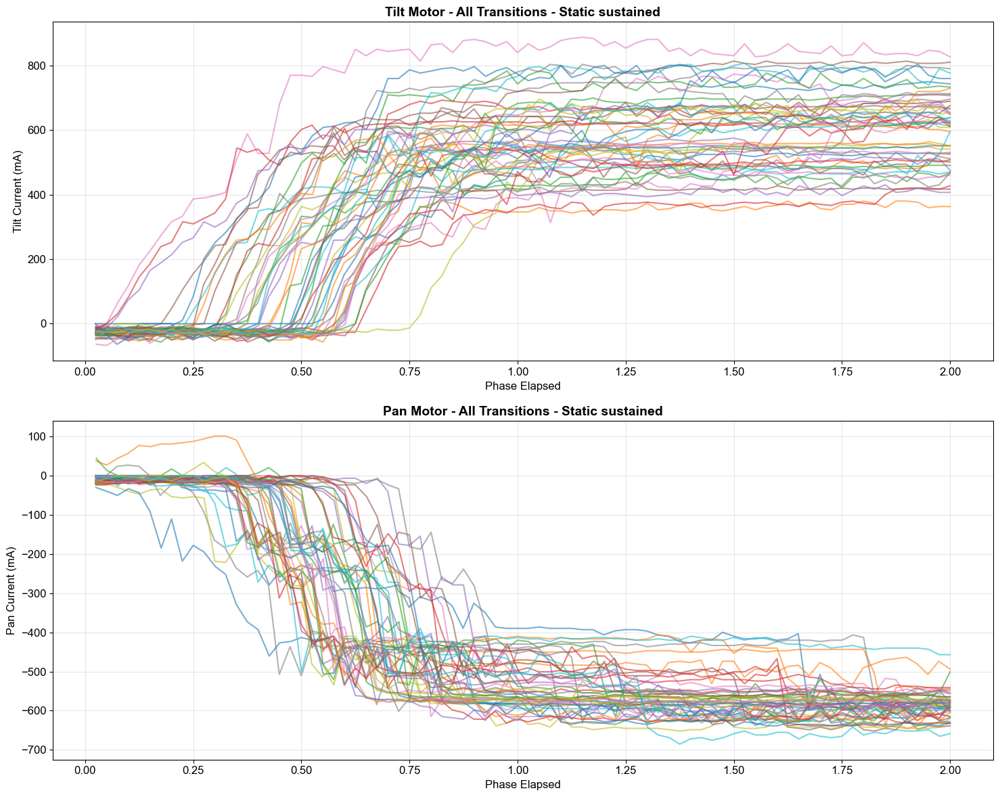


Plot Summary:
Tilt Motor: 50 transition runs plotted
Pan Motor: 50 transition runs plotted
Saved to: ./plots/all_transitions_tilt_and_panstatic_sustained_{model_name}.jpeg


In [40]:
import matplotlib.pyplot as plt
import numpy as np
plot_all_transitions(tilt_static_sustained_df, pan_static_sustained_df, title_suffix=' - Static sustained', save_suffix='static_sustained_{model_name}', figsize=(15, 12))

## Prediciton error statistics

In [41]:
import scipy.stats as sps

def sem(x):
    return sps.sem(x, ddof=1) if len(x) > 1 else 0.0

def compute_prediction_error_stats(df_in, n_bins=25, align_phase=True):
    """
    Compute phase-aligned prediction error statistics for tilt and pan motors.

    IMPORTANT:
    - This function assumes df_in is already filtered to ONE condition
      (for example only static push OR only small movement).
    - To avoid overweighting long/oversampled runs, we first aggregate within each
      (source_file, transition) run per phase bin, and then average across runs.
    - If align_phase=True, each run is normalized to phase [0, 1] before binning.

    Args:
        df_in (pd.DataFrame): Filtered condition-specific input DataFrame.
        n_bins (int): Number of equal-width phase bins.
        align_phase (bool): Normalize phase per run to [0, 1] before averaging.

    Returns:
        pd.DataFrame with columns:
            phase_mean, tilt_error_mean, tilt_error_sem,
            pan_error_mean, pan_error_sem,
            n_runs, n_samples
    """
    import numpy as np
    import pandas as pd

    required_cols = {
        'phase_elapsed', 'model_prediction', 'present_current',
        'transition', 'source_file'
    }
    missing = required_cols.difference(df_in.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    df = df_in.copy()

    # Safety check: prevent accidental mixing of different perturbation conditions.
    if 'perturbation_type' in df.columns:
        unique_conditions = df['perturbation_type'].dropna().unique().tolist()
        if len(unique_conditions) > 1:
            raise ValueError(
                "df_in contains multiple perturbation_type values: "
                f"{unique_conditions}. Filter to one condition before calling this function."
            )

    df['abs_tilt_error'] = [
        abs(float(pred[0])) - abs(float(actual[0]))
        for pred, actual in zip(df['model_prediction'], df['present_current'])
    ]
    df['abs_pan_error'] = [
        abs(float(pred[1])) - abs(float(actual[1]))
        for pred, actual in zip(df['model_prediction'], df['present_current'])
    ]

    # Build stable run identifier
    df['run_id'] = df['source_file'].astype(str) + '::' + df['transition'].astype(str)

    # Optionally align phase per run to [0, 1]
    if align_phase:
        run_phase_min = df.groupby('run_id')['phase_elapsed'].transform('min')
        run_phase_max = df.groupby('run_id')['phase_elapsed'].transform('max')
        run_phase_span = run_phase_max - run_phase_min
        run_phase_span = run_phase_span.replace(0, np.nan)

        df['phase_for_bin'] = (df['phase_elapsed'] - run_phase_min) / run_phase_span
        # Degenerate runs with constant phase get phase 0
        df['phase_for_bin'] = df['phase_for_bin'].fillna(0.0).clip(0.0, 1.0)

        phase_min = 0.0
        phase_max = 1.0
    else:
        df['phase_for_bin'] = df['phase_elapsed']
        phase_min = float(df['phase_for_bin'].min())
        phase_max = float(df['phase_for_bin'].max())

    # Phase binning
    bin_edges = np.linspace(phase_min, phase_max, n_bins + 1)
    df['phase_bin'] = pd.cut(df['phase_for_bin'], bins=bin_edges, include_lowest=True)

    # 1) Within each run/bin: average repeated samples
    run_bin = (
        df.groupby(['run_id', 'phase_bin'], observed=True)
          .agg(
              phase_mean=('phase_for_bin', 'mean'),
              tilt_error=('abs_tilt_error', 'mean'),
              pan_error=('abs_pan_error', 'mean'),
              n_points=('abs_tilt_error', 'count')
          )
          .reset_index()
    )



    stats = (
        run_bin.groupby('phase_bin', observed=True)
            .agg(
                phase_mean=('phase_mean', 'mean'),
                tilt_error_mean=('tilt_error', 'mean'),
                tilt_error_sem=('tilt_error', sem),
                pan_error_mean=('pan_error', 'mean'),
                pan_error_sem=('pan_error', sem),
                n_runs=('run_id', 'nunique'),
                n_samples=('n_points', 'sum'),
            
        )

    )
    condition = (
        df['perturbation_type'].iloc[0]
        if 'perturbation_type' in df.columns and len(df) > 0
        else 'unknown'
    )

    print(
        f"compute_prediction_error_stats: condition={condition}, align_phase={align_phase}, "
        f"rows={len(df)}, runs={df['run_id'].nunique()}, bins={len(stats)}"
    )


    return stats


In [42]:
# Compute condition-specific error statistics (each call receives one filtered condition)
tilt_push_error_stats = compute_prediction_error_stats(tilt_static_push_df)
tilt_sustained_error_stats = compute_prediction_error_stats(tilt_static_sustained_df)
big_tilt_moving_error_stats = compute_prediction_error_stats(big_move_tilt_df)
small_tilt_moving_error_stats = compute_prediction_error_stats(small_move_tilt_df)
big_obstacle_tilt_moving_error_stats = compute_prediction_error_stats(big_move_obstacle_tilt_df)

pan_push_error_stats = compute_prediction_error_stats(pan_static_push_df)
pan_sustained_error_stats = compute_prediction_error_stats(pan_static_sustained_df)
big_pan_moving_error_stats = compute_prediction_error_stats(big_move_pan_df)
small_pan_moving_error_stats = compute_prediction_error_stats(small_move_pan_df)
big_obstacle_pan_moving_error_stats = compute_prediction_error_stats(big_move_obstacle_pan_df)



compute_prediction_error_stats: condition=push, align_phase=True, rows=4429, runs=56, bins=25
compute_prediction_error_stats: condition=sustained, align_phase=True, rows=4000, runs=50, bins=25
compute_prediction_error_stats: condition=none, align_phase=True, rows=1456, runs=50, bins=25
compute_prediction_error_stats: condition=none, align_phase=True, rows=4115, runs=100, bins=25
compute_prediction_error_stats: condition=obstacle, align_phase=True, rows=1456, runs=50, bins=25
compute_prediction_error_stats: condition=push, align_phase=True, rows=4800, runs=60, bins=25
compute_prediction_error_stats: condition=sustained, align_phase=True, rows=4000, runs=50, bins=25
compute_prediction_error_stats: condition=none, align_phase=True, rows=1276, runs=49, bins=25
compute_prediction_error_stats: condition=none, align_phase=True, rows=4295, runs=100, bins=25
compute_prediction_error_stats: condition=obstacle, align_phase=True, rows=1276, runs=49, bins=25


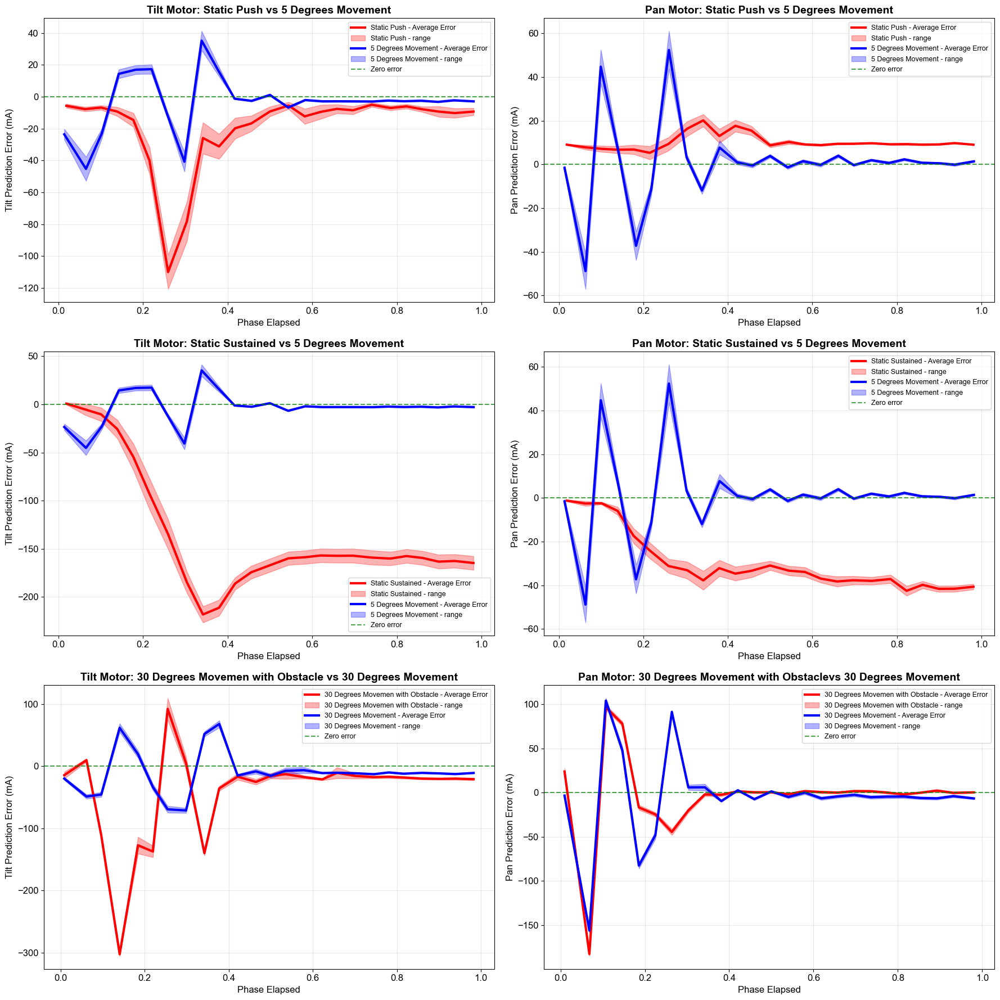

Combined comparison plot created and saved to : ./plots/combined_tilt_pan_error_comparisons_temporal_mlp_TimeSteps3_no_IMU_with_current.jpeg


In [43]:
import matplotlib.pyplot as plt

def create_combined_comparison_plots(save_siffix=''):
    """
    Create a combined 3x2 subplot figure comparing error profiles.
    Left column: Tilt motor comparisons
    Right column: Pan motor comparisons
    """
    fig, axes = plt.subplots(3, 2, figsize=(18, 18))
    
    # Define the comparisons for each row
    comparisons = [
        {
            'tilt': (tilt_push_error_stats, small_tilt_moving_error_stats, 'Static Push vs 5 Degrees Movement'),
            'pan': (pan_push_error_stats, small_pan_moving_error_stats, 'Static Push vs 5 Degrees Movement')
        },
        {
            'tilt': (tilt_sustained_error_stats, small_tilt_moving_error_stats, 'Static Sustained vs 5 Degrees Movement'),
            'pan': (pan_sustained_error_stats, small_pan_moving_error_stats, 'Static Sustained vs 5 Degrees Movement')
        },
        {
            'tilt': (big_obstacle_tilt_moving_error_stats, big_tilt_moving_error_stats, '30 Degrees Movemen with Obstacle vs 30 Degrees Movement'),
            'pan': (big_obstacle_pan_moving_error_stats, big_pan_moving_error_stats,'30 Degrees Movement with Obstaclevs 30 Degrees Movement')
        }
    ]
    
    # Plot each comparison
    for row_idx, comparison in enumerate(comparisons):
        # Tilt motor (left column)
        ax_tilt = axes[row_idx, 0]
        static_error, moving_error, comparison_name = comparison['tilt']
        
        # Extract labels from comparison name
        labels = [label.strip() for label in comparison_name.split('vs')]
        first_label = labels[0]
        second_label = labels[1]
        
        # Plot tilt data
        ax_tilt.plot(static_error['phase_mean'], static_error['tilt_error_mean'], 
                     color='red', linewidth=3, label=f'{first_label} - Average Error')
        ax_tilt.fill_between(static_error['phase_mean'], 
                            static_error['tilt_error_mean'] - static_error['tilt_error_sem'], 
                            static_error['tilt_error_mean'] + static_error['tilt_error_sem'],
                             alpha=0.3, color='red', label=f'{first_label} - range')
        
        ax_tilt.plot(moving_error['phase_mean'], moving_error['tilt_error_mean'], 
                     color='blue', linewidth=3, label=f'{second_label} - Average Error')
        ax_tilt.fill_between(moving_error['phase_mean'], 
                            moving_error['tilt_error_mean'] - moving_error['tilt_error_sem'], 
                            moving_error['tilt_error_mean'] + moving_error['tilt_error_sem'],     
                             alpha=0.3, color='blue', label=f'{second_label} - range')
        
        ax_tilt.axhline(y=0, color='green', linestyle='--', alpha=0.7, label='Zero error')
        ax_tilt.set_xlabel('Phase Elapsed')
        ax_tilt.set_ylabel('Tilt Prediction Error (mA)')
        ax_tilt.set_title(f'Tilt Motor: {comparison_name}', fontweight='bold')
        ax_tilt.legend(fontsize=9)
        ax_tilt.grid(True, alpha=0.3)
        
        # Pan motor (right column)
        ax_pan = axes[row_idx, 1]
        static_error, moving_error, comparison_name = comparison['pan']
        
        # Plot pan data
        ax_pan.plot(static_error['phase_mean'], static_error['pan_error_mean'], 
                    color='red', linewidth=3, label=f'{first_label} - Average Error')
        ax_pan.fill_between(static_error['phase_mean'], 
                            static_error['pan_error_mean'] - static_error['pan_error_sem'], 
                            static_error['pan_error_mean'] + static_error['pan_error_sem'] , 
                            alpha=0.3, color='red', label=f'{first_label} - range')
        
        ax_pan.plot(moving_error['phase_mean'], moving_error['pan_error_mean'], 
                    color='blue', linewidth=3, label=f'{second_label} - Average Error')
        ax_pan.fill_between(moving_error['phase_mean'], 
                            moving_error['pan_error_mean'] - moving_error['pan_error_sem'], 
                            moving_error['pan_error_mean'] + moving_error['pan_error_sem'] ,
                            alpha=0.3, color='blue', label=f'{second_label} - range')
        
        ax_pan.axhline(y=0, color='green', linestyle='--', alpha=0.7, label='Zero error')
        ax_pan.set_xlabel('Phase Elapsed')
        ax_pan.set_ylabel('Pan Prediction Error (mA)')
        ax_pan.set_title(f'Pan Motor: {comparison_name}', fontweight='bold')
        ax_pan.legend(fontsize=9)
        ax_pan.grid(True, alpha=0.3)
    

    plt.tight_layout()
    
    output = f'./plots/combined_tilt_pan_error_comparisons{save_siffix}.jpeg'
    # Save the combined plot
    plt.savefig(output, 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Combined comparison plot created and saved to :", output)

# Create the combined plot
create_combined_comparison_plots(save_siffix=f"_{model_name}")

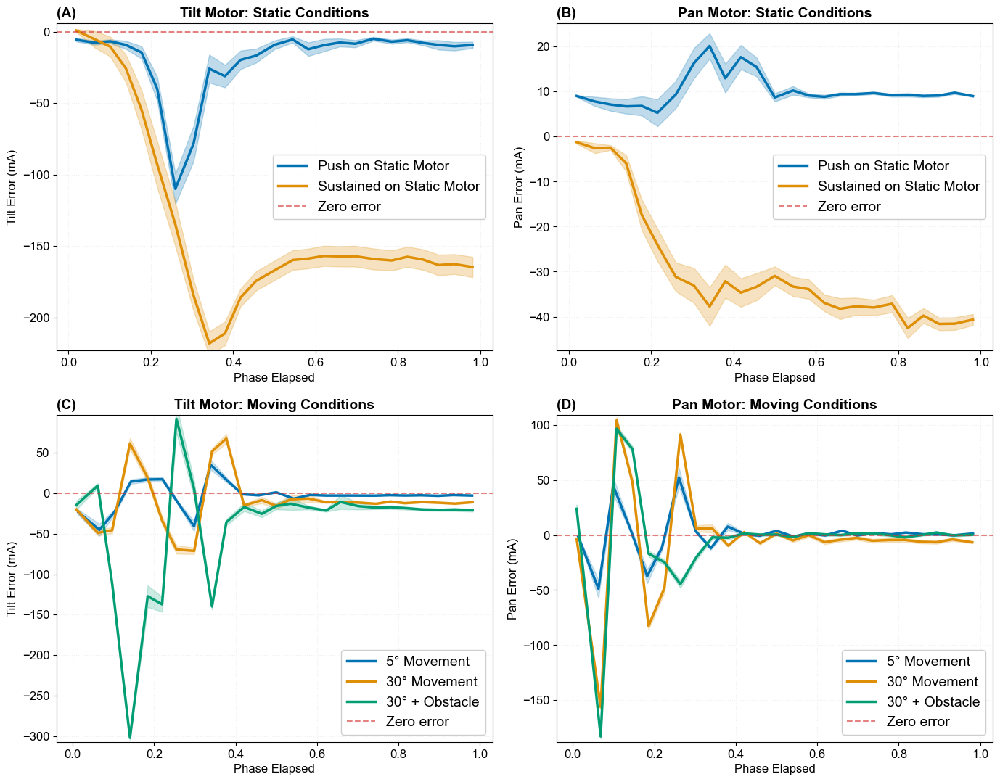

Combined plot saved to: ./plots/combined_comparison_temporal_mlp_TimeSteps3_no_IMU_with_current.jpeg


In [44]:
def create_grouped_comparison_plots(save_suffix=''):
    """
    Create a single 2x2 figure:
      Top-left: Tilt Motor - Static Conditions (Push vs Sustained)
      Top-right: Pan Motor - Static Conditions (Push vs Sustained)
      Bottom-left: Tilt Motor - Moving Conditions (3 overlaid)
      Bottom-right: Pan Motor - Moving Conditions (3 overlaid)
    """
    from IPython.display import display

    # Colorblind-friendly palette (Okabe-Ito)
    COLOR_BLUE = '#0173B2'
    COLOR_ORANGE = '#DE8F05'
    COLOR_GREEN = '#029E73'
    COLOR_RED_LINE = '#D32F2F'

    # Prepare comparisons
    moving_comparison = {
        'tilt': (
            small_tilt_moving_error_stats,
            big_tilt_moving_error_stats,
            big_obstacle_tilt_moving_error_stats,
            '5 Degrees, 30 Degrees Movement, 30 Degrees Movement with Obstacle'
        ),
        'pan': (
            small_pan_moving_error_stats,
            big_pan_moving_error_stats,
            big_obstacle_pan_moving_error_stats,
            '5 Degrees, 30 Degrees Movement, 30 Degrees Movement with Obstacle'
        )
    }

    static_comparisons = [
        {
            'tilt': (tilt_push_error_stats, tilt_sustained_error_stats, 'Push on Static Motor vs Sustained on Static Motor'),
            'pan': (pan_push_error_stats, pan_sustained_error_stats, 'Push on Static Motor vs Sustained on Static Motor')
        }
    ]

    # Collect all error values to compute y-limits for static plots
    all_tilt_errors = []
    all_pan_errors = []
    for comparison in static_comparisons:
        tilt_stats_1, tilt_stats_2, _ = comparison['tilt']
        pan_stats_1, pan_stats_2, _ = comparison['pan']
        all_tilt_errors.extend([tilt_stats_1['tilt_error_mean'], tilt_stats_2['tilt_error_mean']])
        all_pan_errors.extend([pan_stats_1['pan_error_mean'], pan_stats_2['pan_error_mean']])

    tilt_static_min = min([e.min() for e in all_tilt_errors]) - 5
    tilt_static_max = max([e.max() for e in all_tilt_errors]) + 5
    pan_static_min = min([e.min() for e in all_pan_errors]) - 5
    pan_static_max = max([e.max() for e in all_pan_errors]) + 5

    # Prepare moving y-limits
    tilt_small, tilt_big, tilt_obstacle, _ = moving_comparison['tilt']
    pan_small, pan_big, pan_obstacle, _ = moving_comparison['pan']
    moving_conditions = [
        ('5° Movement', COLOR_BLUE, tilt_small, pan_small),
        ('30° Movement', COLOR_ORANGE, tilt_big, pan_big),
        ('30° + Obstacle', COLOR_GREEN, tilt_obstacle, pan_obstacle),
    ]
    all_moving_tilt_errors = [condition[2]['tilt_error_mean'] for condition in moving_conditions]
    all_moving_pan_errors = [condition[3]['pan_error_mean'] for condition in moving_conditions]
    tilt_moving_min = min(e.min() for e in all_moving_tilt_errors) - 5
    tilt_moving_max = max(e.max() for e in all_moving_tilt_errors) + 5
    pan_moving_min = min(e.min() for e in all_moving_pan_errors) - 5
    pan_moving_max = max(e.max() for e in all_moving_pan_errors) + 5

    # Create single 2x2 figure
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    ax_tilt_static = axes[0, 0]
    ax_pan_static = axes[0, 1]
    ax_tilt_moving = axes[1, 0]
    ax_pan_moving = axes[1, 1]

    # Static - Tilt
    comparison = static_comparisons[0]
    error1, error2, comparison_name = comparison['tilt']
    labels = [label.strip() for label in comparison_name.split('vs')]
    ax_tilt_static.plot(error1['phase_mean'], error1['tilt_error_mean'], color=COLOR_BLUE, linewidth=2.5, label=labels[0])
    ax_tilt_static.fill_between(error1['phase_mean'],
                                 error1['tilt_error_mean'] - error1['tilt_error_sem'],
                                 error1['tilt_error_mean'] + error1['tilt_error_sem'],
                                 alpha=0.25, color=COLOR_BLUE)
    ax_tilt_static.plot(error2['phase_mean'], error2['tilt_error_mean'], color=COLOR_ORANGE, linewidth=2.5, label=labels[1])
    ax_tilt_static.fill_between(error2['phase_mean'],
                                 error2['tilt_error_mean'] - error2['tilt_error_sem'],
                                 error2['tilt_error_mean'] + error2['tilt_error_sem'],
                                 alpha=0.25, color=COLOR_ORANGE)
    ax_tilt_static.axhline(y=0, color=COLOR_RED_LINE, linestyle='--', linewidth=1.5, alpha=0.6, label='Zero error')
    ax_tilt_static.set_xlabel('Phase Elapsed')
    ax_tilt_static.set_ylabel('Tilt Error (mA)')
    ax_tilt_static.set_title('Tilt Motor: Static Conditions', fontweight='bold')
    ax_tilt_static.legend( loc='right', framealpha=0.95)
    ax_tilt_static.grid(True, alpha=0.2, linestyle=':')
    ax_tilt_static.set_ylim([tilt_static_min, tilt_static_max])
    ax_tilt_static.text(0, 1.05, '(A)', transform=ax_tilt_static.transAxes, fontweight='bold', verticalalignment='top')

    # Static - Pan
    error1, error2, comparison_name = comparison['pan']
    labels_pan = [label.strip() for label in comparison_name.split('vs')]
    ax_pan_static.plot(error1['phase_mean'], error1['pan_error_mean'], color=COLOR_BLUE, linewidth=2.5, label=labels_pan[0])
    ax_pan_static.fill_between(error1['phase_mean'],
                               error1['pan_error_mean'] - error1['pan_error_sem'],
                               error1['pan_error_mean'] + error1['pan_error_sem'],
                               alpha=0.25, color=COLOR_BLUE)
    ax_pan_static.plot(error2['phase_mean'], error2['pan_error_mean'], color=COLOR_ORANGE, linewidth=2.5, label=labels_pan[1])
    ax_pan_static.fill_between(error2['phase_mean'],
                               error2['pan_error_mean'] - error2['pan_error_sem'],
                               error2['pan_error_mean'] + error2['pan_error_sem'],
                               alpha=0.25, color=COLOR_ORANGE)
    ax_pan_static.axhline(y=0, color=COLOR_RED_LINE, linestyle='--', linewidth=1.5, alpha=0.6, label='Zero error')
    ax_pan_static.set_xlabel('Phase Elapsed')
    ax_pan_static.set_ylabel('Pan Error (mA)')
    ax_pan_static.set_title('Pan Motor: Static Conditions', fontweight='bold')
    ax_pan_static.legend( loc='right', framealpha=0.95)
    ax_pan_static.grid(True, alpha=0.2, linestyle=':')
    ax_pan_static.set_ylim([pan_static_min, pan_static_max])
    ax_pan_static.text(0, 1.05, '(B)', transform=ax_pan_static.transAxes, fontweight='bold', verticalalignment='top')

    # Moving - overlayed conditions
    for condition_label, color, tilt_stats, pan_stats in moving_conditions:
        ax_tilt_moving.plot(tilt_stats['phase_mean'], tilt_stats['tilt_error_mean'], color=color, linewidth=2.5, label=condition_label)
        ax_tilt_moving.fill_between(tilt_stats['phase_mean'],
                                    tilt_stats['tilt_error_mean'] - tilt_stats['tilt_error_sem'],
                                    tilt_stats['tilt_error_mean'] + tilt_stats['tilt_error_sem'],
                                    alpha=0.2, color=color)
        ax_pan_moving.plot(pan_stats['phase_mean'], pan_stats['pan_error_mean'], color=color, linewidth=2.5, label=condition_label)
        ax_pan_moving.fill_between(pan_stats['phase_mean'],
                                   pan_stats['pan_error_mean'] - pan_stats['pan_error_sem'],
                                   pan_stats['pan_error_mean'] + pan_stats['pan_error_sem'],
                                   alpha=0.2, color=color)

    ax_tilt_moving.axhline(y=0, color=COLOR_RED_LINE, linestyle='--', linewidth=1.5, alpha=0.6, label='Zero error')
    ax_tilt_moving.set_xlabel('Phase Elapsed')
    ax_tilt_moving.set_ylabel('Tilt Error (mA)')
    ax_tilt_moving.set_title('Tilt Motor: Moving Conditions', fontweight='bold')
    ax_tilt_moving.legend( loc='lower right', framealpha=0.95)
    ax_tilt_moving.grid(True, alpha=0.2, linestyle=':')
    ax_tilt_moving.set_ylim([tilt_moving_min, tilt_moving_max])
    ax_tilt_moving.text(0, 1.05, '(C)', transform=ax_tilt_moving.transAxes, fontweight='bold', verticalalignment='top')

    ax_pan_moving.axhline(y=0, color=COLOR_RED_LINE, linestyle='--', linewidth=1.5, alpha=0.6, label='Zero error')
    ax_pan_moving.set_xlabel('Phase Elapsed')
    ax_pan_moving.set_ylabel('Pan Error (mA)')
    ax_pan_moving.set_title('Pan Motor: Moving Conditions', fontweight='bold')
    ax_pan_moving.legend( loc='lower right', framealpha=0.95)
    ax_pan_moving.grid(True, alpha=0.2, linestyle=':')
    ax_pan_moving.set_ylim([pan_moving_min, pan_moving_max])
    ax_pan_moving.text(0, 1.05, '(D)', transform=ax_pan_moving.transAxes,  fontweight='bold', verticalalignment='top')

    fig.tight_layout()
    output_path = f'./plots/combined_comparison{save_suffix}.jpeg'
    fig.savefig(output_path, dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)
    print(f"Combined plot saved to: {output_path}")

create_grouped_comparison_plots(save_suffix=f"_{model_name}")


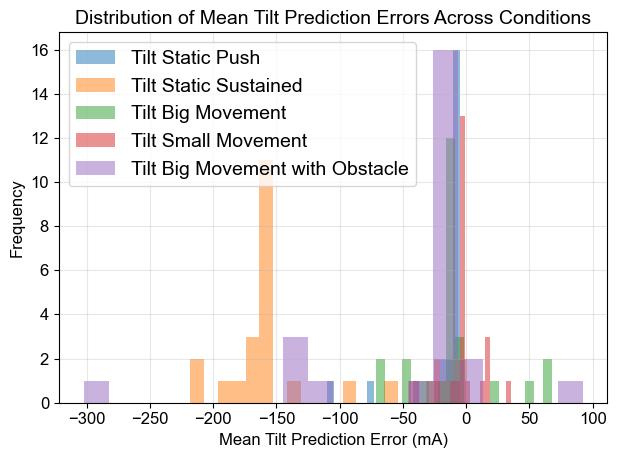

In [45]:
plt.hist(tilt_push_error_stats['tilt_error_mean'], bins=20, alpha=0.5, label='Tilt Static Push')
plt.hist(tilt_sustained_error_stats['tilt_error_mean'], bins=20, alpha=0.5, label='Tilt Static Sustained')
plt.hist(big_tilt_moving_error_stats['tilt_error_mean'], bins=20, alpha=0.5, label='Tilt Big Movement')
plt.hist(small_tilt_moving_error_stats['tilt_error_mean'], bins=20, alpha=0.5, label='Tilt Small Movement')
plt.hist(big_obstacle_tilt_moving_error_stats['tilt_error_mean'], bins=20, alpha=0.5, label='Tilt Big Movement with Obstacle')
plt.xlabel('Mean Tilt Prediction Error (mA)')
plt.ylabel('Frequency')
plt.title('Distribution of Mean Tilt Prediction Errors Across Conditions')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

### Impedance plots

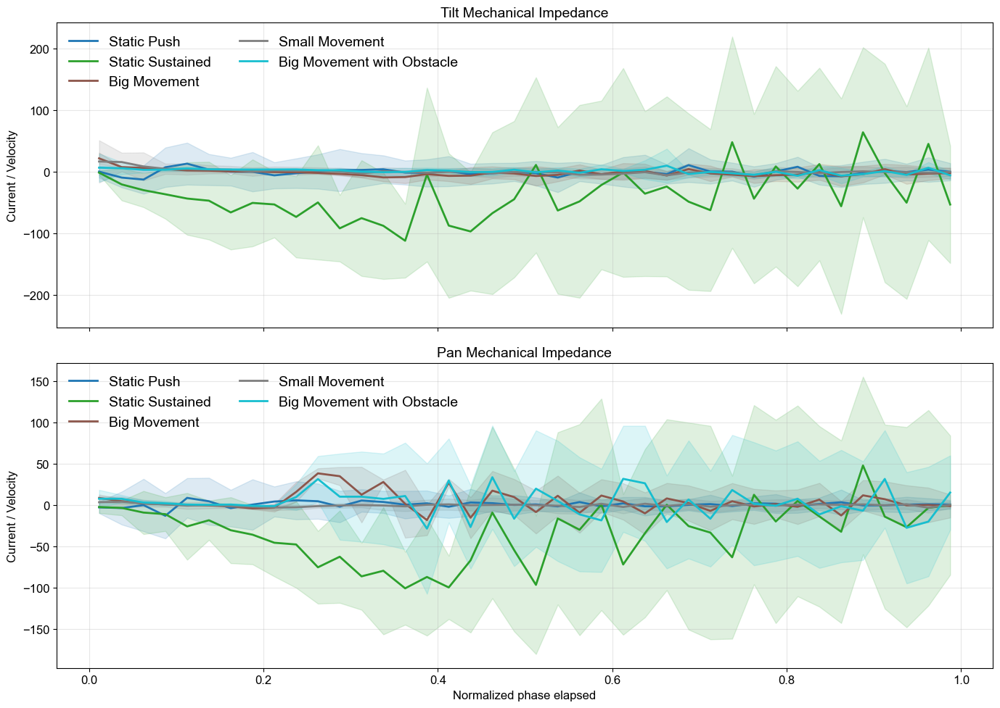

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

condition_dfs = [
    ('Static Push', tilt_static_push_df, pan_static_push_df),
    ('Static Sustained', tilt_static_sustained_df, pan_static_sustained_df),
    ('Big Movement', big_move_tilt_df, big_move_pan_df),
    ('Small Movement', small_move_tilt_df, small_move_pan_df),
    ('Big Movement with Obstacle', big_move_obstacle_tilt_df, big_move_obstacle_pan_df),
]

n_phase_bins = 40
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
panel_specs = [('Tilt', 0, axes[0]), ('Pan', 1, axes[1])]
colors = plt.cm.tab10(np.linspace(0, 1, len(condition_dfs)))

for panel_name, motor_idx, ax in panel_specs:
    for color, (condition_name, tilt_df, pan_df) in zip(colors, condition_dfs):
        df = tilt_df if motor_idx == 0 else pan_df
        trial_frames = []

        for (source_file, transition), group in df.groupby(['source_file', 'transition']):
            group = group.sort_values('phase_elapsed').copy()

            phase_elapsed = group['phase_elapsed'].to_numpy(dtype=float)
            current = group['present_current'].apply(lambda value: np.asarray(value, dtype=float)[motor_idx]).to_numpy(dtype=float)
            position = group['present_position'].apply(lambda value: np.asarray(value, dtype=float)[motor_idx]).to_numpy(dtype=float)

            if len(phase_elapsed) < 2:
                continue

            dt = np.diff(phase_elapsed)
            velocity = np.diff(position) / dt
            valid_mask = np.isfinite(dt) & np.isfinite(velocity) & (np.abs(dt) > 1e-9) & (np.abs(velocity) > 1e-9)

            if not valid_mask.any():
                continue

            trial_df = pd.DataFrame({
                'run_id': f'{source_file}::{transition}',
                'phase_elapsed': phase_elapsed[1:][valid_mask],
                'impedance': current[1:][valid_mask] / velocity[valid_mask],
            })

            phase_min = trial_df['phase_elapsed'].min()
            phase_max = trial_df['phase_elapsed'].max()
            if phase_max > phase_min:
                trial_df['phase_norm'] = (trial_df['phase_elapsed'] - phase_min) / (phase_max - phase_min)
            else:
                trial_df['phase_norm'] = 0.0

            trial_frames.append(trial_df[['run_id', 'phase_norm', 'impedance']])

        if not trial_frames:
            continue

        impedance_df = pd.concat(trial_frames, ignore_index=True)
        impedance_df['phase_bin'] = pd.cut(impedance_df['phase_norm'], bins=n_phase_bins, include_lowest=True)

        per_run_bin = (
            impedance_df.groupby(['run_id', 'phase_bin'], observed=True)['impedance']
            .mean()
            .reset_index()
        )

        summary = (
            per_run_bin.groupby('phase_bin', observed=True)['impedance']
            .agg(impedance_mean='mean', impedance_std='std')
            .reset_index()
        )
        summary['phase_center'] = summary['phase_bin'].apply(lambda interval: interval.mid)

        ax.plot(summary['phase_center'], summary['impedance_mean'], color=color, linewidth=2.0, label=condition_name)
        ax.fill_between(
            summary['phase_center'],
            summary['impedance_mean'] - summary['impedance_std'].fillna(0.0),
            summary['impedance_mean'] + summary['impedance_std'].fillna(0.0),
            color=color,
            alpha=0.15,
        )

    ax.set_title(f'{panel_name} Mechanical Impedance')
    ax.set_ylabel('Current / Velocity')
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False, ncols=2)

axes[-1].set_xlabel('Normalized phase elapsed')
plt.tight_layout()
plt.show()

## Perturbation Classificaiton

In [47]:
pan_static_push_df.head()

,transition,tick,time,perturbation_type,phase_elapsed,present_position,goal_position,present_current,model_prediction,gyro,accel,euler_angles,source_file,json_header
7389,0,42,1.050,push,0.024,"[181.2305, 205.6641]","[181.0, 206.0]","[-50.4, 60.48]","[245.6786, 74.4469]","[-1.5625, 1.7988, -1.34]","[0.1055, 0.0113, -0.9511]","[-0.8899, 7.0532, -137.7576]",pan_static_mode_log_20251021_090220_push.json,static_push_data
7390,0,43,1.075,push,0.049,"[181.2305, 205.6641]","[181.0, 206.0]","[-47.04, 63.84]","[245.0672, 71.1141]","[-0.8007, 1.038, 0.0279]","[0.1088, 0.0133, -0.9524]","[-0.9119, 7.0532, -137.7795]",pan_static_mode_log_20251021_090220_push.json,static_push_data
7391,0,44,1.100,push,0.074,"[181.2305, 205.6641]","[181.0, 206.0]","[-47.04, 63.84]","[245.2279, 74.4603]","[0.5139, -0.1582, -0.4552]","[0.1168, 0.0224, -0.9527]","[-0.9338, 7.0642, -137.7905]",pan_static_mode_log_20251021_090220_push.json,static_push_data
7392,0,45,1.125,push,0.099,"[181.2305, 205.6641]","[181.0, 206.0]","[-47.04, 60.48]","[245.3741, 74.4896]","[-0.0117, 0.0029, -0.6743]","[0.1178, 0.0184, -0.9526]","[-0.9338, 7.0532, -137.7905]",pan_static_mode_log_20251021_090220_push.json,static_push_data
7393,0,46,1.150,push,0.124,"[181.2305, 205.6641]","[181.0, 206.0]","[-50.4, 60.48]","[245.4151, 71.118]","[-0.457, 0.9299, -0.3483]","[0.1108, 0.0095, -0.9518]","[-0.9338, 7.0422, -137.8015]",pan_static_mode_log_20251021_090220_push.json,static_push_data


In [48]:
import numpy as np
from scipy.fft import dct
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import pandas as pd
from sklearn.pipeline import Pipeline



# ---------------------------------------------------------------------------
# Feature extraction helpers
# ---------------------------------------------------------------------------

def phase_bin_means(err, n_bins=5):
    """
    Divide the trial into n_bins equal-length windows and compute
    mean absolute error in each. Returns a vector of length n_bins.
    This directly encodes the temporal shape of the error profile.
    """
    bins = np.array_split(err, n_bins)
    return [np.mean(np.abs(b)) for b in bins]


def early_to_late_ratio(err, early_frac=0.3):
    """
    Ratio of mean |error| in the early phase to mean |error| in the
    late phase. Front-loaded transients (push) will be >> 1; sustained
    errors will be near 1; obstacle errors (late) will be < 1.
    A small epsilon avoids division by zero on near-zero late phases.
    """
    n = len(err)
    early = np.mean(np.abs(err[:int(n * early_frac)]))
    late  = np.mean(np.abs(err[int(n * (1 - early_frac)):]))
    return early / (late + 1e-9)


def time_to_peak(err):
    """
    Normalised phase position [0, 1] of maximum absolute error.
    Early → transient push; late → obstacle during movement.
    """
    return np.argmax(np.abs(err)) / len(err)


def half_decay_time(err):
    """
    Time (in normalised phase units) for the error to fall to 50% of
    its peak value after the peak. Returns 1.0 if the signal never
    decays (i.e. sustained perturbation).
    """
    peak_idx = np.argmax(np.abs(err))
    peak_val = np.abs(err[peak_idx])
    if peak_val == 0:
        return 0.0
    post_peak = np.abs(err[peak_idx:])
    below = np.where(post_peak <= 0.5 * peak_val)[0]
    if len(below) == 0:
        return 1.0   # never decays → sustained
    return below[0] / len(err)


def lag1_autocorrelation(err):
    """
    Pearson correlation between e(t) and e(t+1).
    Near 1 → persistent/sustained error.
    Near 0 or negative → transient/oscillatory error.
    """
    if len(err) < 2:
        return 0.0
    return np.corrcoef(err[:-1], err[1:])[0, 1]


def temporal_center_of_mass(err):
    """
    Phase position [0, 1] at which the absolute error energy is centred.
    Encodes whether the perturbation is front-, mid-, or back-loaded.
    """
    t = np.arange(len(err))
    abs_err = np.abs(err)
    total = abs_err.sum()
    if total == 0:
        return 0.5
    return np.dot(t, abs_err) / (total * len(err))


def dct_shape_coefficients(err, n_coeff=4):
    """
    First n_coeff DCT-II coefficients of the normalised error signal.
    Coeff 0 ≈ mean (DC); coeff 1 ≈ linear trend; coeff 2 ≈ curvature.
    These compactly encode the smooth temporal shape of the profile.
    Normalise by signal length so coefficients are amplitude-independent.
    """
    normed = err / (np.max(np.abs(err)) + 1e-9)
    coeffs = dct(normed, norm='ortho')
    return list(coeffs[1:n_coeff + 1])   # skip coeff 0 (redundant with mean)


def sign_consistency(err):
    """
    Proportion of timesteps sharing the same sign as the peak error.
    Near 1 → the error stays on one side (e.g. sustained load in one
    direction). Near 0.5 → oscillatory or noisy.
    """
    dominant_sign = np.sign(err[np.argmax(np.abs(err))])
    return np.mean(np.sign(err) == dominant_sign)




# ---------------------------------------------------------------------------
# Feature names (must match extraction order below)
# ---------------------------------------------------------------------------

FEATURE_NAMES = (
    # --- Original features (kept for backward comparison) ---
    ['max_abs_err', 'std_err', 'mean_err', 
     'sum_err', 'range_err'] +

    # --- Phase-binned means: coarse temporal profile shape ---
    [f'bin_mean_{i+1}of5' for i in range(5)] +

    # --- Temporal structure ---
    ['early_to_late_ratio',       # front-loaded vs back-loaded
     'time_to_peak',              # when does the error peak?
     'half_decay_time',           # how fast does it decay?
     'lag1_autocorr',             # persistence
     'temporal_com',              # centre-of-mass of error energy
     'sign_consistency'] +         # does error stay on one side?
        

    # --- DCT shape coefficients: smooth profile shape ---
    [f'dct_coeff_{i+1}' for i in range(4)]
)


# ---------------------------------------------------------------------------
# Main feature extraction loop  (structure unchanged from original)
# ---------------------------------------------------------------------------

target_tasks = {
    'Static Push':           [(pan_static_push_df, 1),      (tilt_static_push_df, 0)],
    'Static Sustained':      [(pan_static_sustained_df, 1), (tilt_static_sustained_df, 0)],
    '5 Deg Move':            [(small_move_pan_df, 1),        (small_move_tilt_df, 0)],
    '30 Deg Move':           [(big_move_pan_df, 1),          (big_move_tilt_df, 0)],
    '30 Deg Move + Obstacle':[(big_move_obstacle_pan_df, 1), (big_move_obstacle_tilt_df, 0)],
}

features_list = []
labels_list   = []

for condition, df_axis_pairs in target_tasks.items():
    for df, axis in df_axis_pairs:
        for (source, trans), group in df.groupby(['source_file', 'transition']):
            try:
                curr = np.stack(group['present_current'].values)
                pred = np.stack(group['model_prediction'].values)
                err  = curr[:, axis] - pred[:, axis]
            except Exception:
                continue

            if len(err) < 10:
                continue

            n         = len(err)
            err_early = err[:int(n * 0.3)]

            # ---- original features ----------------------------------------
            orig = [
                np.max(np.abs(err)),
                np.std(err),
                np.mean(err),
                np.sum(err),
                np.max(err) - np.min(err),
            ]

            # ---- new temporal features ------------------------------------
            temporal = (
                phase_bin_means(err, n_bins=5) +
                [
                    early_to_late_ratio(err),
                    time_to_peak(err),
                    half_decay_time(err),
                    lag1_autocorrelation(err),
                    temporal_center_of_mass(err),
                    sign_consistency(err),
                ] +
                dct_shape_coefficients(err, n_coeff=4)
            )

            features_list.append(orig + temporal)
            labels_list.append(condition)

X = np.array(features_list)
y = np.array(labels_list)
print(f"Total extracted runs : {len(X)}")
print(f"Features per run     : {X.shape[1]}  ({len(FEATURE_NAMES)} named)")

# ---------------------------------------------------------------------------
# Classification
# ---------------------------------------------------------------------------

if len(X) > 0:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('rf', RandomForestClassifier(random_state=42, oob_score=True))
    ])

    param_grid = {
        'rf__n_estimators' : [100, 300, 500],
        'rf__max_depth' : [3, 5, 7],
        'rf__min_samples_split': [2, 5, 10],
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring='accuracy')
    grid_search.fit(X, y) # Pass raw X, the pipeline handles scaling per fold

    best = grid_search.best_estimator_
    rf = best.named_steps['rf']
    print("\nBest Parameters :", grid_search.best_params_)
    print(f"CV Accuracy      : {grid_search.best_score_:.3f}")
    if hasattr(rf, 'oob_score_'):
        print(f"OOB Score        : {rf.oob_score_:.3f}")
    else:
        print("OOB Score        : N/A")

    # --- Cross-validated predictions for confusion matrix & report ----------
    from sklearn.model_selection import cross_val_predict
    # use the pipeline (best) and raw X so scaling is applied inside the pipeline
    y_pred = cross_val_predict(best, X, y, cv=cv)
    print("\nClassification Report:\n", classification_report(y, y_pred))

    # --- Feature importance -------------------------------------------------
    importances = pd.Series(rf.feature_importances_, index=FEATURE_NAMES)
    print("\nTop-10 feature importances:")
    print(importances.nlargest(10).to_string())

    # --- Ablation: original features only vs temporal features only ---------
    orig_idx     = list(range(6))
    temporal_idx = list(range(6, X.shape[1]))

    for label, idx in [('Original features only', orig_idx),
                        ('Temporal features only', temporal_idx),
                        ('All features',           list(range(X.shape[1])))]:
        X_subset = X[:, idx]
        # wrap classifier with scaler so features are standardized for each CV fold
        ablation_pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('rf', RandomForestClassifier(random_state=42))
        ])
        scores = cross_val_score(
            ablation_pipeline,
            X_subset, y, cv=cv, scoring='accuracy'
        )
        print(f"{label:25s} : CV Accuracy = {scores.mean():.3f} ± {scores.std():.3f}")
else:
    print("No valid runs found for feature extraction and classification.")

Total extracted runs : 465
Features per run     : 20  (20 named)

Best Parameters : {'rf__max_depth': 7, 'rf__min_samples_split': 2, 'rf__n_estimators': 100}
CV Accuracy      : 0.991
OOB Score        : 0.987

Classification Report:
                         precision    recall  f1-score   support

           30 Deg Move       1.00      1.00      1.00        49
30 Deg Move + Obstacle       1.00      1.00      1.00        49
            5 Deg Move       1.00      0.99      1.00       151
           Static Push       0.98      0.98      0.98       116
      Static Sustained       0.98      0.99      0.99       100

              accuracy                           0.99       465
             macro avg       0.99      0.99      0.99       465
          weighted avg       0.99      0.99      0.99       465


Top-10 feature importances:
temporal_com           0.119809
bin_mean_5of5          0.108967
bin_mean_1of5          0.100776
bin_mean_4of5          0.078915
dct_coeff_1            0.074693

In [64]:
#table of feature importances
importances_df = pd.DataFrame({
    'feature': FEATURE_NAMES,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)
print("\nFeature Importances:")
print(importances_df.to_string(index=False))


Feature Importances:
            feature  importance
       temporal_com    0.119809
      bin_mean_5of5    0.108967
      bin_mean_1of5    0.100776
      bin_mean_4of5    0.078915
        dct_coeff_1    0.074693
early_to_late_ratio    0.069314
   sign_consistency    0.055437
        max_abs_err    0.052921
          range_err    0.049012
        dct_coeff_4    0.048831
            std_err    0.048095
           mean_err    0.042555
            sum_err    0.039919
      bin_mean_2of5    0.031964
      bin_mean_3of5    0.021690
        dct_coeff_2    0.015061
        dct_coeff_3    0.013434
       time_to_peak    0.012571
      lag1_autocorr    0.011682
    half_decay_time    0.004352


In [49]:

estimators = grid_search.best_params_.get('rf__n_estimators')
max_depth = grid_search.best_params_.get('rf__max_depth')
min_samples_split = grid_search.best_params_.get('rf__min_samples_split')
# Train and evaluate Model
clf = RandomForestClassifier(n_estimators=estimators, max_depth=max_depth, 
                             min_samples_split=min_samples_split, random_state=42,
                             oob_score=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(clf, X, y, cv=cv, scoring='accuracy')
print("\n--- Cross-Validation Accuracy ---")
print(f"Mean Accuracy: {cv_scores.mean()*100:.1f}% ± {cv_scores.std()*100:.1f}%")


clf.fit(X, y)
y_pred = clf.predict(X)
print(f"OOB Score: {clf.oob_score_:.3f}")

print("\n--- Classification Report (Full Dataset Fit) ---")
print(classification_report(y, y_pred, zero_division=0))


importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

print("\n--- Feature Importances ---")
for idx in indices[:10]:
    print(f"{FEATURE_NAMES[idx]:25s} : {importances[idx]:.4f}")



--- Cross-Validation Accuracy ---
Mean Accuracy: 99.1% ± 0.4%
OOB Score: 0.987

--- Classification Report (Full Dataset Fit) ---
                        precision    recall  f1-score   support

           30 Deg Move       1.00      1.00      1.00        49
30 Deg Move + Obstacle       1.00      1.00      1.00        49
            5 Deg Move       1.00      1.00      1.00       151
           Static Push       0.99      1.00      1.00       116
      Static Sustained       1.00      0.99      0.99       100

              accuracy                           1.00       465
             macro avg       1.00      1.00      1.00       465
          weighted avg       1.00      1.00      1.00       465


--- Feature Importances ---
temporal_com              : 0.1198
bin_mean_5of5             : 0.1090
bin_mean_1of5             : 0.1008
bin_mean_4of5             : 0.0789
dct_coeff_1               : 0.0747
early_to_late_ratio       : 0.0693
sign_consistency          : 0.0554
max_abs_err      

In [63]:
importances_df = pd.DataFrame({
    'feature': FEATURE_NAMES,
    'importance': importances
}).sort_values('importance', ascending=False)

print("\n--- Feature Importances ---")
print(importances_df.to_string(index=False))


--- Feature Importances ---
            feature  importance
       temporal_com    0.119809
      bin_mean_5of5    0.108967
      bin_mean_1of5    0.100776
      bin_mean_4of5    0.078915
        dct_coeff_1    0.074693
early_to_late_ratio    0.069314
   sign_consistency    0.055437
        max_abs_err    0.052921
          range_err    0.049012
        dct_coeff_4    0.048831
            std_err    0.048095
           mean_err    0.042555
            sum_err    0.039919
      bin_mean_2of5    0.031964
      bin_mean_3of5    0.021690
        dct_coeff_2    0.015061
        dct_coeff_3    0.013434
       time_to_peak    0.012571
      lag1_autocorr    0.011682
    half_decay_time    0.004352



--- MDI (RandomForest.feature_importances_) ---
temporal_com                   :  11.98%
bin_mean_5of5                  :  10.90%
bin_mean_1of5                  :  10.08%
bin_mean_4of5                  :   7.89%
dct_coeff_1                    :   7.47%
early_to_late_ratio            :   6.93%
sign_consistency               :   5.54%
max_abs_err                    :   5.29%
range_err                      :   4.90%
dct_coeff_4                    :   4.88%
std_err                        :   4.81%
mean_err                       :   4.26%
sum_err                        :   3.99%
bin_mean_2of5                  :   3.20%
bin_mean_3of5                  :   2.17%
dct_coeff_2                    :   1.51%
dct_coeff_3                    :   1.34%
time_to_peak                   :   1.26%
lag1_autocorr                  :   1.17%
half_decay_time                :   0.44%

Computing permutation importance (this may take a moment)...

--- Permutation importance (accuracy) ---
bin_mean_1of5             

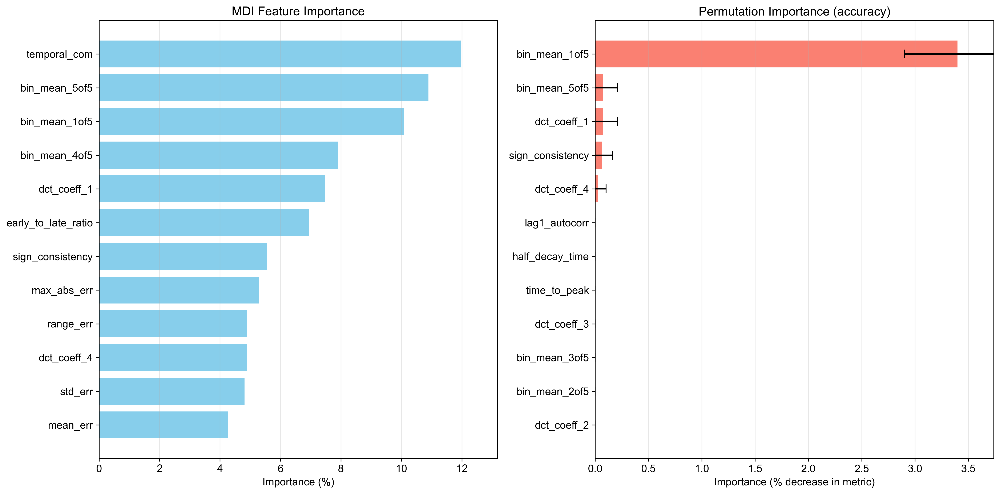

In [50]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# --- user-configurable parameters ---
OUT_DIR = "plots"
JPEG_QUALITY = 95      # 0-100
DPI = 300
N_REPEATS = 30
SCORING = "accuracy"   # change to 'balanced_accuracy' or 'f1_weighted' if preferred
TOP_N = 12
RANDOM_STATE = 42
# -----------------------------------

os.makedirs(OUT_DIR, exist_ok=True)

# Basic checks
try:
    clf  # sklearn RandomForestClassifier instance (fitted)
    X
    y
except NameError:
    raise RuntimeError("Please run the cells that define and fit 'clf', and define 'X' and 'y' first.")

if "FEATURE_NAMES" not in globals():
    FEATURE_NAMES = [f"feat_{i}" for i in range(X.shape[1])]

# Make plots look publication-ready
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 12,
    "figure.dpi": DPI,
})

# 1) MDI (model internal)
mdi = np.asarray(clf.feature_importances_, dtype=float)
mdi_sum = mdi.sum() if mdi.sum() != 0 else 1.0
mdi_pct = 100.0 * mdi / mdi_sum
mdi_order = np.argsort(mdi_pct)[::-1]

print("\n--- MDI (RandomForest.feature_importances_) ---")
for i in mdi_order[:min(len(mdi_pct), 20)]:
    print(f"{FEATURE_NAMES[i]:30s} : {mdi_pct[i]:6.2f}%")

# 2) Permutation importance (metric based, interpretable)
print("\nComputing permutation importance (this may take a moment)...")
perm = permutation_importance(clf, X, y, n_repeats=N_REPEATS, random_state=RANDOM_STATE,
                              scoring=SCORING, n_jobs=-1)
perm_means = perm.importances_mean        # in metric units (accuracy fraction)
perm_stds = perm.importances_std
perm_order = np.argsort(perm_means)[::-1]

print(f"\n--- Permutation importance ({SCORING}) ---")
for i in perm_order[:min(len(perm_means), 20)]:
    print(f"{FEATURE_NAMES[i]:30s} : {perm_means[i]*100:6.3f}% ± {perm_stds[i]*100:5.3f}%")


#PLOT MDI and Permutation importances side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
# MDI plot
mdi_top_indices = mdi_order[:TOP_N]
mdi_top_values = mdi_pct[mdi_top_indices]
mdi_top_names = [FEATURE_NAMES[i] for i in mdi_top_indices]
axes[0].barh(mdi_top_names[::-1], mdi_top_values[::-1], color='skyblue')
axes[0].set_title("MDI Feature Importance")
axes[0].set_xlabel("Importance (%)")
axes[0].set_xlim(0, max(mdi_top_values)*1.1)       
axes[0].grid(True, alpha=0.3, axis='x')
# Permutation importance plot
perm_top_indices = perm_order[:TOP_N]
perm_top_means = perm_means[perm_top_indices] * 100
perm_top_stds = perm_stds[perm_top_indices] * 100
perm_top_names = [FEATURE_NAMES[i] for i in perm_top_indices]
axes[1].barh(perm_top_names[::-1], perm_top_means[::-1], xerr=perm_top_stds[::-1], color='salmon', capsize=5)
axes[1].set_title(f"Permutation Importance ({SCORING})")
axes[1].set_xlabel("Importance (% decrease in metric)")
axes[1].set_xlim(0, max(perm_top_means)*1.1)  
axes[1].grid(True, alpha=0.3, axis='x')
plt.tight_layout()
output_path = os.path.join(OUT_DIR, f"feature_importance_comparison_{SCORING}.jpeg")
#plt.savefig(output_path, quality=JPEG_QUALITY, dpi=DPI, bbox_inches='tight')
plt.show()

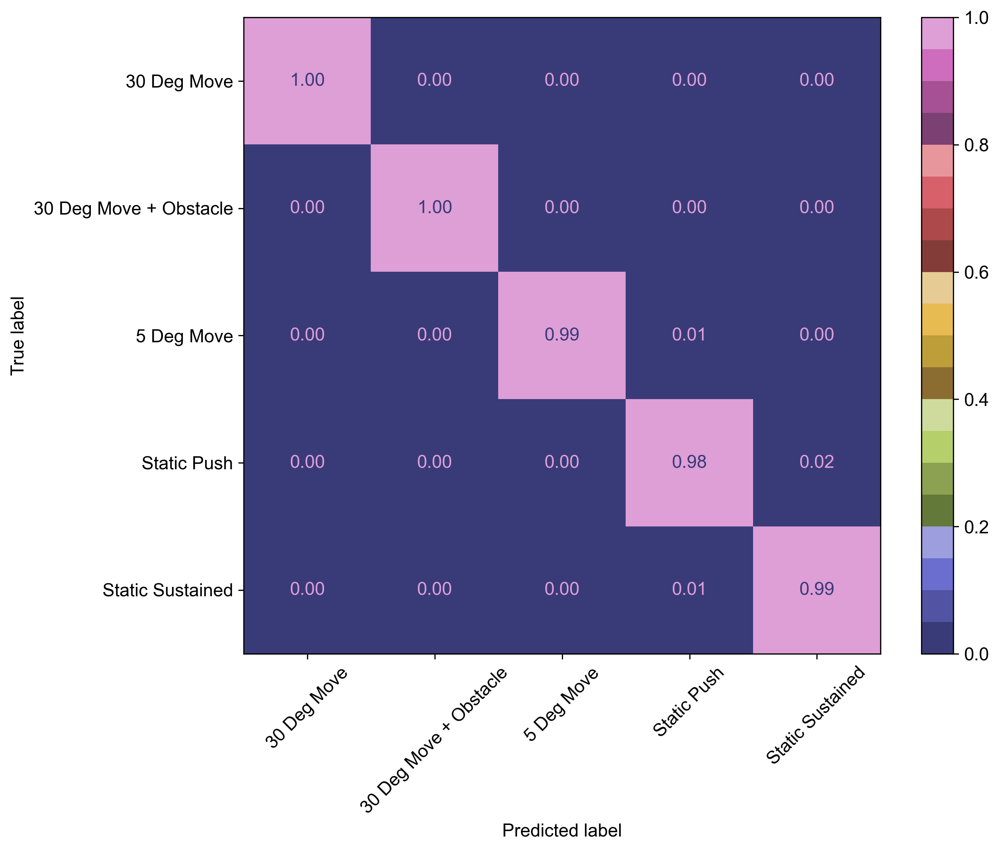

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

# Generate cross-validated predictions so the confusion matrix reflects real performance
y_pred_cv = cross_val_predict(clf, X, y, cv=cv)

# Create the confusion matrix, normalized by 'true' (rows)
# This will show the proportion of each true class that was predicted as the various conditions.
cm_normalized = confusion_matrix(y, y_pred_cv, labels=clf.classes_, normalize='true')

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=clf.classes_)
# values_format='.2f' ensures we print formatted decimals (e.g., 0.95 instead of 0.95321)
disp.plot(cmap='tab20b', ax=ax, xticks_rotation=45, values_format='.2f')

#plt.title('Normalized Confusion Matrix\n(Proportion of True Conditions Classified)')
plt.tight_layout()
plt.savefig("plots/perturbation_classification_confusion_matrix.jpeg", dpi=300, bbox_inches="tight")
plt.show()

### Compare with raw current

In [52]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


target_tasks = {
    'Static Push': [(pan_static_push_df, 1), (tilt_static_push_df, 0)],
    'Static Sustained': [(pan_static_sustained_df, 1), (tilt_static_sustained_df, 0)],
    '5 Deg Move': [(small_move_pan_df, 1), (small_move_tilt_df, 0)],
    '30 Deg Move': [(big_move_pan_df, 1), (big_move_tilt_df, 0)],
    '30 Deg Move + Obstacle': [(big_move_obstacle_pan_df, 1), (big_move_obstacle_tilt_df, 0)]
}


def summary_features(x):
    """Six summary statistics used in the paper."""
    n = len(x)
    early = x[:max(1, int(n * 0.3))]

    return [
        np.max(np.abs(x)),
        np.std(x),
        np.mean(x),
        np.max(np.abs(early)),
        np.sum(x),
        np.max(x) - np.min(x)
    ]


rows = []

for condition, df_axis_pairs in target_tasks.items():
    for df, axis in df_axis_pairs:
        for (source, trans), group in df.groupby(['source_file', 'transition']):
            try:
                curr = np.stack(group['present_current'].values)
                pred = np.stack(group['model_prediction'].values)

                current_axis = curr[:, axis]
                prediction_axis = pred[:, axis]
                error_axis = current_axis - prediction_axis

            except Exception:
                continue

            if len(error_axis) < 10:
                continue

            rows.append({
                "condition": condition,
                "group": f"{source}_{trans}_{axis}",
                "error_features": summary_features(error_axis),
                "current_features": summary_features(current_axis),
                "combined_features": summary_features(error_axis) + summary_features(current_axis)
            })


data = pd.DataFrame(rows)

X_error = np.vstack(data["error_features"])
X_current = np.vstack(data["current_features"])
X_combined = np.vstack(data["combined_features"])

y = data["condition"].values
groups = data["group"].values

print("Trials:", len(y))
print(data["condition"].value_counts())

Trials: 465
condition
5 Deg Move                151
Static Push               116
Static Sustained          100
30 Deg Move                49
30 Deg Move + Obstacle     49
Name: count, dtype: int64


In [53]:
param_grid = {
    "clf__n_estimators": [100, 300, 500],
    "clf__max_depth": [3, 5, 7],
    "clf__min_samples_split": [2, 5, 10]
}

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=123
)

scoring = {
    "accuracy": make_scorer(accuracy_score),
    "macro_f1": make_scorer(f1_score, average="macro")
}


def evaluate_feature_set(X, y, groups, name):
    pipe = Pipeline([
        # StandardScaler is not necessary for Random Forest,
        # but keeping it inside the pipeline avoids leakage if you compare to SVM/logistic baselines later.
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(random_state=42, class_weight="balanced"))
    ])

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1
    )

    X = np.asarray(X)
    y = np.asarray(y).ravel()
    groups = np.asarray(groups).ravel()

    test_accuracy = []
    test_macro_f1 = []
    estimators = []

    for train_idx, test_idx in outer_cv.split(X, y, groups=groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        groups_train = groups[train_idx]

        search.fit(X_train, y_train, groups=groups_train)
        best_estimator = search.best_estimator_
        y_pred = best_estimator.predict(X_test)

        test_accuracy.append(accuracy_score(y_test, y_pred))
        test_macro_f1.append(f1_score(y_test, y_pred, average="macro"))
        estimators.append(best_estimator)

    scores = {
        "test_accuracy": np.asarray(test_accuracy),
        "test_macro_f1": np.asarray(test_macro_f1),
        "estimator": estimators
    }

    print(f"\n{name}")
    print(f"Accuracy: {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")
    print(f"Macro-F1: {scores['test_macro_f1'].mean():.3f} ± {scores['test_macro_f1'].std():.3f}")

    return scores


scores_error = evaluate_feature_set(X_error, y, groups, "Prediction-error features")
scores_current = evaluate_feature_set(X_current, y, groups, "Raw-current baseline")
scores_combined = evaluate_feature_set(X_combined, y, groups, "Error + current features")


Prediction-error features
Accuracy: 0.955 ± 0.030
Macro-F1: 0.949 ± 0.041

Raw-current baseline
Accuracy: 0.983 ± 0.011
Macro-F1: 0.979 ± 0.019

Error + current features
Accuracy: 0.994 ± 0.005
Macro-F1: 0.993 ± 0.006


# Model architecture visualisation


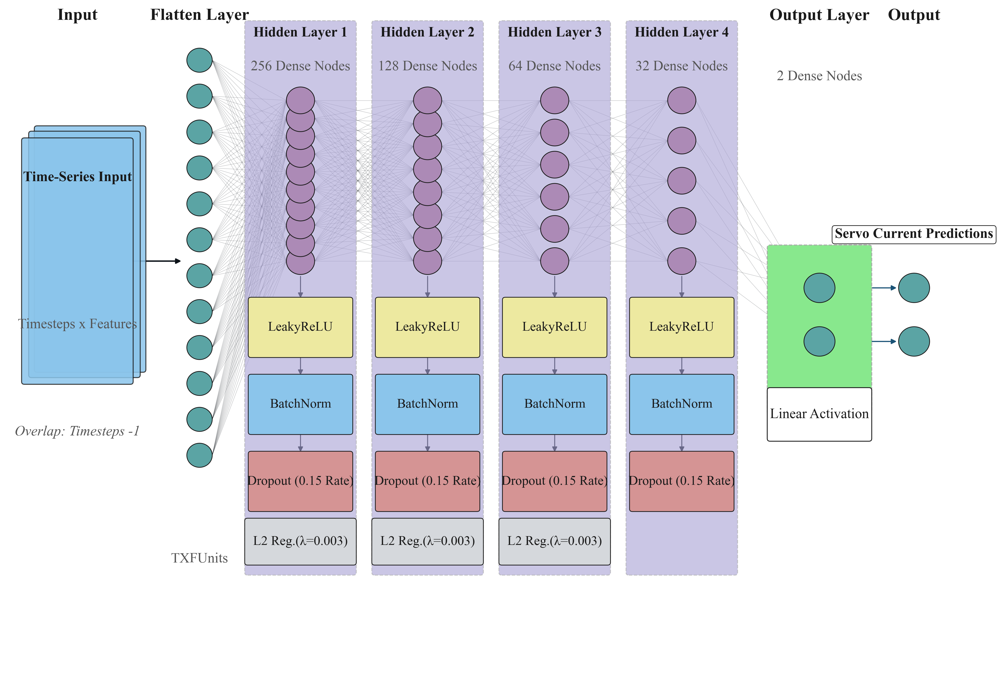

Saved -> plots/mlp_architecture.jpeg


In [54]:
"""
Replicates Panel A from the MLP Architecture figure:
Architecture of the Custom Multilayer Perceptron with Time-Series Input,
Regularization, and Training Strategy.
"""

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10,
    "savefig.dpi": 300,
})

# --- colour palette ---
TEAL = "#5BA4A4"
HIDDEN_NODE = "#AC8AB6"
HIDDEN_LAYER = "#a8a1d5"
BATCHNORM_COLOR = "#8BC5EB"
LeakyReLU_COLOR = "#EDE9A0"
OUTPUT_COLOR = "#88E88D"
DROPOUT_COLOR = "#D59494"
GREY_LIGHT = "#D5D8DC"
WHITE = "#FFFFFF"
BLACK = "#1A1A1A"
DARK_GREY = "#555555"
ARROW_FULL = "#0D1319"
ARROW_ACT = "#27AE60"
ARROW_REG = "#8E44AD"
ARROW_OUT = "#1A5276"

# ============================================================================
# Layout controls: edit only these values to reflow the full diagram.
# ============================================================================
FIG_W, FIG_H = 15, 10
Y_MIN, Y_MAX = 0, 10

MARGIN_LEFT = 0.25
MARGIN_RIGHT = 0.9

# Headers and labels
HEADER_FONRSIZE = 18
LABEL_FONTSIZE = 15

# Horizontal spacing controls
GAP_INPUT_TO_FLATTEN = 0.8
GAP_FLATTEN_TO_HIDDEN = 0.5
GAP_BETWEEN_HIDDEN = 0.3
GAP_HIDDEN_TO_OUTPUT = 0.5
GAP_OUTPUT_TO_PRED = 0.90

# Input block
INPUT_W = 1.5
INPUT_H = 3.6
INPUT_Y = 4.4
INPUT_STACK_OFFSETS = [0.18, 0.10, 0.0]

# Flatten layer
FLATTEN_NODE_COUNT = 12
FLATTEN_NODE_R = 0.18
FLATTEN_NODE_Y0 = 3.3
FLATTEN_NODE_Y1 = 9.2

# Hidden layers
HIDDEN_LAYER_COUNT = 4
HIDDEN_BOX_W = 1.5
HIDDEN_BOX_H = 8.2
HIDDEN_BOX_Y = 1.55
HIDDEN_NODE_COUNTS = [10, 8, 6, 5]
HIDDEN_DENSE_LABELS = ["256 Dense Nodes", "128 Dense Nodes", "64 Dense Nodes", "32 Dense Nodes"]
HIDDEN_TITLES = ["Hidden Layer 1", "Hidden Layer 2", "Hidden Layer 3", "Hidden Layer 4"]
HIDDEN_NODE_R = 0.20
NODE_BAND_TOP_MARGIN = 1.15
NODE_BAND_HEIGHT = 2.4

SUB_BOX_W = 1.4
SUB_BOX_H = 0.82
SUB_BOX_GAP = 0.33
SUB_STACK_BOTTOM_PAD = 0.95

L2_BOX_H = 0.62
L2_BOX_Y = 1.70
L2_BOX_PAD_X = 0.0

# Output block
OUT_BOX_W = 1.4
OUT_BOX_H = 2.45
OUT_BOX_Y = 3.55
OUT_YS = [5.0, 5.8]
OUT_NODE_R = 0.22

LINEAR_BOX_W = 1.4
LINEAR_BOX_H = 0.72
LINEAR_BOX_Y = 3.55

# Predictions
PRED_YS = [5.0, 5.8]
PRED_NODE_R = 0.22

# Connection style
FULL_CONN_LW = 0.35
FULL_CONN_ALPHA = 0.30

LABEL_FONT = "Times New Roman"


def draw_box(ax, x, y, w, h, color, label=None,
             edgecolor=BLACK, lw=1.0, alpha=1.0, label_color=BLACK,
             bold=False, linestyle="solid", fontsize=LABEL_FONTSIZE):
    rect = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04",
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=lw,
        linestyle=linestyle,
        alpha=alpha,
        zorder=3,
    )
    ax.add_patch(rect)
    if label:
        fw = "bold" if bold else "normal"
        ax.text(
            x + w / 2,
            y + h / 2,
            label,
            ha="center",
            va="center",
            fontsize=fontsize,
            color=label_color,
            fontweight=fw,
            zorder=4,
            family=LABEL_FONT,
        )
    return rect


def draw_nodes(ax, cx, ys, r=0.22, color=TEAL, edgecolor=BLACK):
    nodes = []
    for y in ys:
        circ = plt.Circle((cx, y), r, color=color, ec=edgecolor, lw=0.8, zorder=5)
        ax.add_patch(circ)
        nodes.append((cx, y, r))
    return nodes


def arrow(ax, x1, y1, x2, y2, color=ARROW_FULL, lw=1.2, arrowstyle="-|>", zorder=2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle=arrowstyle, color=color, lw=lw),
        zorder=zorder,
    )


def connect_layers(ax, left_nodes, right_nodes, color=ARROW_FULL, lw=0.4, alpha=0.35):
    for lx, ly, lr in left_nodes:
        for rx, ry, rr in right_nodes:
            if rx >= lx:
                x1, x2 = lx + lr, rx - rr
            else:
                x1, x2 = lx - lr, rx + rr
            ax.plot([x1, x2], [ly, ry], color=color, lw=lw, alpha=alpha, zorder=1)


# ============================================================================
# Dynamic x-layout derived from widths + gaps.
# ============================================================================
input_front_x = MARGIN_LEFT
input_right_edge = input_front_x + INPUT_W

flatten_cx = input_right_edge + GAP_INPUT_TO_FLATTEN + FLATTEN_NODE_R
flatten_right_edge = flatten_cx + FLATTEN_NODE_R

first_hidden_cx = flatten_right_edge + GAP_FLATTEN_TO_HIDDEN + HIDDEN_BOX_W / 2
hidden_centers = [first_hidden_cx + i * (HIDDEN_BOX_W + GAP_BETWEEN_HIDDEN) for i in range(HIDDEN_LAYER_COUNT)]

last_hidden_right = hidden_centers[-1] + HIDDEN_BOX_W / 2
out_cx = last_hidden_right + GAP_HIDDEN_TO_OUTPUT + OUT_BOX_W / 2
out_right = out_cx + OUT_NODE_R

pred_cx = out_right + GAP_OUTPUT_TO_PRED + PRED_NODE_R

x_max = pred_cx + PRED_NODE_R + MARGIN_RIGHT
x_min = 0

# ============================================================================
# Figure setup
# ============================================================================
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H), dpi=300)
ax.set_xlim(x_min, x_max)
ax.set_ylim(Y_MIN, Y_MAX)
ax.axis("off")
ax.set_facecolor("white")
fig.patch.set_facecolor("white")


# Input stack (offset cards)
for offset in INPUT_STACK_OFFSETS:
    draw_box(
        ax,
        input_front_x + offset,
        INPUT_Y + offset,
        INPUT_W,
        INPUT_H,
        color=BATCHNORM_COLOR,
        edgecolor=BLACK,
        lw=1.0,
        alpha=0.85,
    )

input_cx = input_front_x + INPUT_W / 2
ax.text(input_cx, 7.35, "Time-Series Input", ha="center", va="bottom", fontsize=LABEL_FONTSIZE, fontweight="bold", color=BLACK, family=LABEL_FONT)
ax.text(input_cx, 5.25, "Timesteps x Features", ha="center", va="center", fontsize=LABEL_FONTSIZE, color=DARK_GREY, family=LABEL_FONT)
ax.text(input_cx, 3.55, "Overlap: Timesteps -1", ha="center", va="bottom", fontsize=LABEL_FONTSIZE, color=DARK_GREY, style="italic", family=LABEL_FONT)


# Flatten layer
flatten_ys = np.linspace(FLATTEN_NODE_Y0, FLATTEN_NODE_Y1, FLATTEN_NODE_COUNT)
flatten_nodes = draw_nodes(ax, flatten_cx, flatten_ys, r=FLATTEN_NODE_R, color=TEAL)
ax.text(flatten_cx, 9.1, "TxF", ha="center", va="bottom", color=DARK_GREY, family=LABEL_FONT, fontsize=LABEL_FONTSIZE)
ax.text(flatten_cx, 1.85, "TXFUnits", ha="center", va="top", color=DARK_GREY, family=LABEL_FONT, fontsize=LABEL_FONTSIZE)

# Input -> Flatten arrow
arrow(ax, input_right_edge, INPUT_Y + (INPUT_H / 2), flatten_cx - FLATTEN_NODE_R - 0.05, INPUT_Y + (INPUT_H / 2), color=ARROW_FULL, lw=1.5)

# Hidden layers
hidden_layer_nodes = []
sub_labels = ["LeakyReLU", "BatchNorm", "Dropout (0.15 Rate)"]
sub_colors = [LeakyReLU_COLOR, BATCHNORM_COLOR, DROPOUT_COLOR]

for idx, (cx, n_nodes, dense_label, title) in enumerate(zip(hidden_centers, HIDDEN_NODE_COUNTS, HIDDEN_DENSE_LABELS, HIDDEN_TITLES)):
    box_x = cx - HIDDEN_BOX_W / 2

    draw_box(
        ax,
        box_x,
        HIDDEN_BOX_Y,
        HIDDEN_BOX_W,
        HIDDEN_BOX_H,
        color=HIDDEN_LAYER,
        edgecolor="#AAAAAA",
        lw=1.0,
        linestyle="--",
        alpha=0.6,
    )

    ax.text(cx, HIDDEN_BOX_Y + HIDDEN_BOX_H - 0.05, title, ha="center", va="top", fontsize=LABEL_FONTSIZE, fontweight="bold", color=BLACK, family=LABEL_FONT)
    ax.text(cx, HIDDEN_BOX_Y + HIDDEN_BOX_H - 0.55, dense_label, ha="center", va="top", fontsize=LABEL_FONTSIZE, color=DARK_GREY, family=LABEL_FONT)

    node_band_top = HIDDEN_BOX_Y + HIDDEN_BOX_H - NODE_BAND_TOP_MARGIN
    node_band_bottom = node_band_top - NODE_BAND_HEIGHT
    ys = np.linspace(node_band_bottom, node_band_top, n_nodes)
    nodes = draw_nodes(ax, cx, ys, r=HIDDEN_NODE_R, color=HIDDEN_NODE)
    hidden_layer_nodes.append(nodes)

    # Sub-boxes: width and x-position are driven by SUB_BOX_W and layer center cx.
    sub_stack_total_h = len(sub_labels) * SUB_BOX_H + (len(sub_labels) - 1) * SUB_BOX_GAP
    sub_bottom = HIDDEN_BOX_Y + SUB_STACK_BOTTOM_PAD
    sub_top = sub_bottom + sub_stack_total_h

    if sub_top > node_band_bottom - 0.15:
        sub_bottom = max(HIDDEN_BOX_Y + 0.1, node_band_bottom - 0.15 - sub_stack_total_h)

    for j, (label, color) in enumerate(zip(sub_labels, sub_colors)):
        y = sub_bottom + (len(sub_labels) - 1 - j) * (SUB_BOX_H + SUB_BOX_GAP)
        x = cx - SUB_BOX_W / 2
        draw_box(ax, x, y, SUB_BOX_W, SUB_BOX_H, color=color, edgecolor=BLACK, lw=0.8, fontsize=LABEL_FONTSIZE - 1)
        ax.text(
            x + SUB_BOX_W / 2,
            y + SUB_BOX_H / 2,
            label,
            ha="center",
            va="center",
            fontsize=LABEL_FONTSIZE - 1,
            color=BLACK,
            family=LABEL_FONT,
            zorder=4,
        )

    if idx < 3:
        l2_w = HIDDEN_BOX_W - 2 * L2_BOX_PAD_X
        l2_x = cx - l2_w / 2
        draw_box(
            ax,
            l2_x,
            L2_BOX_Y,
            l2_w,
            L2_BOX_H,
            color=GREY_LIGHT,
            label="L2 Reg.(λ=0.003)",
            edgecolor=BLACK,
            lw=0.8,
            fontsize=LABEL_FONTSIZE - 1,
        )

    # Internal arrows stay aligned after any spacing/width change.
    leaky_top = sub_bottom + 2 * (SUB_BOX_H + SUB_BOX_GAP) + SUB_BOX_H
    bn_top = sub_bottom + 1 * (SUB_BOX_H + SUB_BOX_GAP) + SUB_BOX_H
    dropout_top = sub_bottom + SUB_BOX_H
    first_node_y = node_band_bottom

    arrow(ax, cx, first_node_y - HIDDEN_NODE_R, cx, leaky_top, color=ARROW_FULL, lw=1.0, arrowstyle="-|>")
    arrow(ax, cx, sub_bottom + 2 * (SUB_BOX_H + SUB_BOX_GAP), cx, bn_top, color=ARROW_FULL, lw=1.0, arrowstyle="-|>")
    arrow(ax, cx, sub_bottom + (SUB_BOX_H + SUB_BOX_GAP), cx, dropout_top, color=ARROW_FULL, lw=1.0, arrowstyle="-|>")

# Output layer
out_nodes = draw_nodes(ax, out_cx, OUT_YS, r=OUT_NODE_R, color=TEAL)

draw_box(
    ax,
    out_cx - OUT_BOX_W / 2,
    OUT_BOX_Y + 0.4,
    OUT_BOX_W,
    OUT_BOX_H,
    color=OUTPUT_COLOR,
    edgecolor="#AAAAAA",
    lw=1.0,
    linestyle="--",
    fontsize=LABEL_FONTSIZE,
)
ax.text(out_cx, 9.05, "2 Dense Nodes", ha="center", va="top", color=DARK_GREY, family=LABEL_FONT, fontsize=LABEL_FONTSIZE)

draw_box(
    ax,
    out_cx - LINEAR_BOX_W / 2,
    LINEAR_BOX_Y,
    LINEAR_BOX_W,
    LINEAR_BOX_H,
    color=WHITE,
    label="Linear Activation",
    fontsize=LABEL_FONTSIZE,
    edgecolor=BLACK,
    lw=0.9,
)

# Final prediction nodes
pred_nodes = draw_nodes(ax, pred_cx, PRED_YS, r=PRED_NODE_R, color=TEAL)
ax.text(
    pred_cx,
    6.5,
    "Servo Current Predictions",
    ha="center",
    va="bottom",
    family=LABEL_FONT,
    color=BLACK,
    fontweight="bold",
    fontsize=LABEL_FONTSIZE,
    bbox=dict(boxstyle="round,pad=0.2", facecolor=WHITE, edgecolor=BLACK, lw=0.7),
)

# Dynamic fully connected lines
all_layers = [flatten_nodes] + hidden_layer_nodes + [out_nodes]
for left_nodes, right_nodes in zip(all_layers[:-1], all_layers[1:]):
    connect_layers(ax, left_nodes, right_nodes, color=ARROW_FULL, lw=FULL_CONN_LW, alpha=FULL_CONN_ALPHA)

# Output -> prediction arrows
for (_, y_out, r_out), (x_pred, y_pred, r_pred) in zip(out_nodes, pred_nodes):
    arrow(ax, out_cx + r_out, y_out, x_pred - r_pred, y_pred, color=ARROW_OUT, lw=1.2)

# Column headers (x values fully derived)
headers = [
    (input_cx, "Input"),
    (flatten_cx, "Flatten Layer"),
    (out_cx, "Output Layer"),
    (pred_cx, "Output"),
]
for hx, ht in headers:
    ax.text(hx, 9.97, ht, ha="center", va="top", fontweight="bold", color=BLACK, family=LABEL_FONT, fontsize=HEADER_FONRSIZE)

plt.tight_layout(pad=0.3)
plt.savefig("plots/mlp_architecture.jpeg", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved -> plots/mlp_architecture.jpeg")

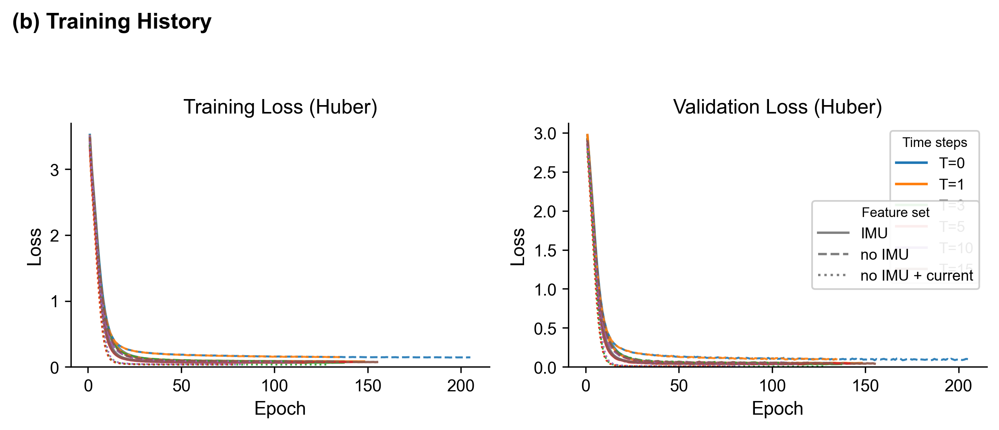

Saved: tMLP_training_history.pdf / .jpeg


In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pickle, os
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "savefig.dpi": 300,
})

# ══════════════════════════════════════════════════════════════════
# PLOT 2 – Training curves (all model groups overlaid)
# ══════════════════════════════════════════════════════════════════
history_dir = '../tMLP_models/history'

# Categorise models into groups
groups = {
    'IMU':             [],   # full features (15)
    'no IMU':          [],   # positional only (6)
    'no IMU + current': [],  # positional + current (8)
}

for fname in sorted(os.listdir(history_dir)):
    if not fname.endswith('.pkl'):
        continue
    with open(os.path.join(history_dir, fname), 'rb') as f:
        h = pickle.load(f)
    # Parse name
    base = fname.replace('history_temporal_mlp_', '').replace('.pkl', '')
    ts = int(base.split('TimeSteps')[1].split('_')[0])
    
    if 'no_IMU_with_current' in base:
        grp = 'no IMU + current'
    elif 'no_IMU' in base:
        grp = 'no IMU'
    else:
        grp = 'IMU'
    
    groups[grp].append({'ts': ts, 'name': base, 'history': h})

# Sort each group by timestep
for g in groups:
    groups[g].sort(key=lambda x: x['ts'])

# Colour map: one colour per timestep, line style per group
ts_colors = {0: '#1f77b4', 1: '#ff7f0e', 3: '#2ca02c', 5: '#d62728',
             10: '#9467bd', 15: '#8c564b'}
grp_styles = {'IMU': '-', 'no IMU': '--', 'no IMU + current': ':'}
grp_lw     = {'IMU': 1.4, 'no IMU': 1.2, 'no IMU + current': 1.1}

fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(8.4, 3.6), sharey=False, facecolor='white')
fig.suptitle("(b) Training History", fontweight='bold', x=0.02, ha='left', fontsize=13)

for grp_name, models in groups.items():
    ls = grp_styles[grp_name]
    lw = grp_lw[grp_name]
    for m in models:
        ts = m['ts']
        h = m['history']
        col = ts_colors.get(ts, '#333')
        epochs = np.arange(1, len(h['loss']) + 1)
        
        ax_train.plot(epochs, h['loss'], color=col, ls=ls, lw=lw, alpha=0.9)
        ax_val.plot(epochs, h['val_loss'], color=col, ls=ls, lw=lw, alpha=0.9)

# Axes formatting
for ax, title in [(ax_train, 'Training Loss (Huber)'), (ax_val, 'Validation Loss (Huber)')]:
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.tick_params(labelsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylim(bottom=0)

# Build legend: timestep colours + group line-styles
ts_handles = [Line2D([0], [0], color=ts_colors[ts], lw=1.5, label=f'T={ts}')
              for ts in sorted(ts_colors.keys())]
grp_handles = [Line2D([0], [0], color='grey', ls=grp_styles[g], lw=1.4, label=g)
               for g in grp_styles]

leg1 = ax_val.legend(handles=ts_handles, loc='upper right', title='Time steps', title_fontsize=8, framealpha=0.92)
ax_val.add_artist(leg1)
ax_val.legend(handles=grp_handles, loc='center right', title='Feature set', title_fontsize=8, framealpha=0.92)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig("tMLP_training_history.pdf", bbox_inches='tight', dpi=300)
plt.savefig("tMLP_training_history.jpeg", bbox_inches='tight', dpi=300)
plt.show()
print("Saved: tMLP_training_history.pdf / .jpeg")

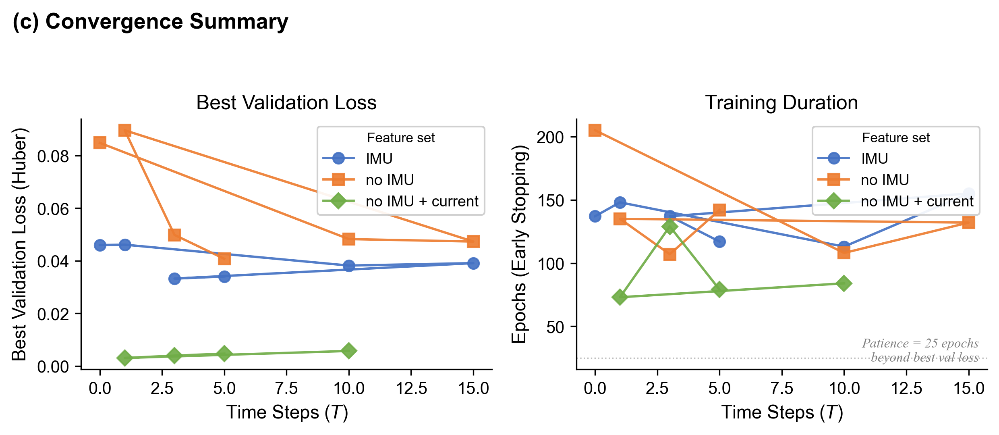

Saved: tMLP_convergence.pdf / .jpeg


In [56]:
import matplotlib.pyplot as plt
import numpy as np
import pickle, os

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "savefig.dpi": 300,
})

# ══════════════════════════════════════════════════════════════════
# PLOT 3 – Convergence summary: best val loss & epochs to converge
# ══════════════════════════════════════════════════════════════════
history_dir = '../tMLP_models/history'

# Collect data
records = []
for fname in sorted(os.listdir(history_dir)):
    if not fname.endswith('.pkl'):
        continue
    with open(os.path.join(history_dir, fname), 'rb') as f:
        h = pickle.load(f)
    base = fname.replace('history_temporal_mlp_', '').replace('.pkl', '')
    ts = int(base.split('TimeSteps')[1].split('_')[0])

    if 'no_IMU_with_current' in base:
        grp = 'no IMU + current'
    elif 'no_IMU' in base:
        grp = 'no IMU'
    else:
        grp = 'IMU'

    best_val = min(h['val_loss'])
    best_ep = int(np.argmin(h['val_loss'])) + 1
    total_ep = len(h['val_loss'])
    records.append({'ts': ts, 'group': grp, 'best_val': best_val,
                    'best_epoch': best_ep, 'total_epochs': total_ep})

# Group markers and colours
grp_markers = {'IMU': 'o', 'no IMU': 's', 'no IMU + current': 'D'}
grp_colors = {'IMU': '#4472c4', 'no IMU': '#ed7d31', 'no IMU + current': '#70ad47'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.4, 3.6), facecolor='white')
fig.suptitle("(c) Convergence Summary", fontweight='bold', x=0.02, ha='left', y=0.99, fontsize=13)

# 1) Best validation loss vs time steps
for grp in grp_colors:
    pts = [r for r in records if r['group'] == grp]
    if not pts:
        continue
    xs = [p['ts'] for p in pts]
    ys = [p['best_val'] for p in pts]
    ax1.plot(xs, ys, marker=grp_markers[grp], color=grp_colors[grp], lw=1.4, ms=6.5, label=grp, alpha=0.92)

ax1.set_xlabel('Time Steps ($T$)', fontsize=11)
ax1.set_ylabel('Best Validation Loss (Huber)', fontsize=11)
ax1.set_title('Best Validation Loss', fontsize=12)
ax1.tick_params(labelsize=10)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(fontsize=9, framealpha=0.92, title='Feature set', title_fontsize=8)

# 2) Total epochs (early stopping) vs time steps
for grp in grp_colors:
    pts = [r for r in records if r['group'] == grp]
    if not pts:
        continue
    xs = [p['ts'] for p in pts]
    ys = [p['total_epochs'] for p in pts]
    ax2.plot(xs, ys, marker=grp_markers[grp], color=grp_colors[grp], lw=1.4, ms=6.5, label=grp, alpha=0.92)

ax2.set_xlabel('Time Steps ($T$)', fontsize=11)
ax2.set_ylabel('Epochs (Early Stopping)', fontsize=11)
ax2.set_title('Training Duration', fontsize=12)
ax2.tick_params(labelsize=10)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(fontsize=9, framealpha=0.92, title='Feature set', title_fontsize=8)

# Add patience annotation
ax2.axhline(y=25, color='grey', ls=':', lw=0.8, alpha=0.5)
ax2.text(0.98, 0.02, 'Patience = 25 epochs\nbeyond best val loss',
         transform=ax2.transAxes, va='bottom', ha='right',
         color='grey', fontstyle='italic', family='Times New Roman', fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("tMLP_convergence.pdf", bbox_inches='tight', dpi=300)
plt.savefig("tMLP_convergence.jpeg", bbox_inches='tight', dpi=300)
plt.show()
print("Saved: tMLP_convergence.pdf / .jpeg")

## Ikaros module conneciton visualisation

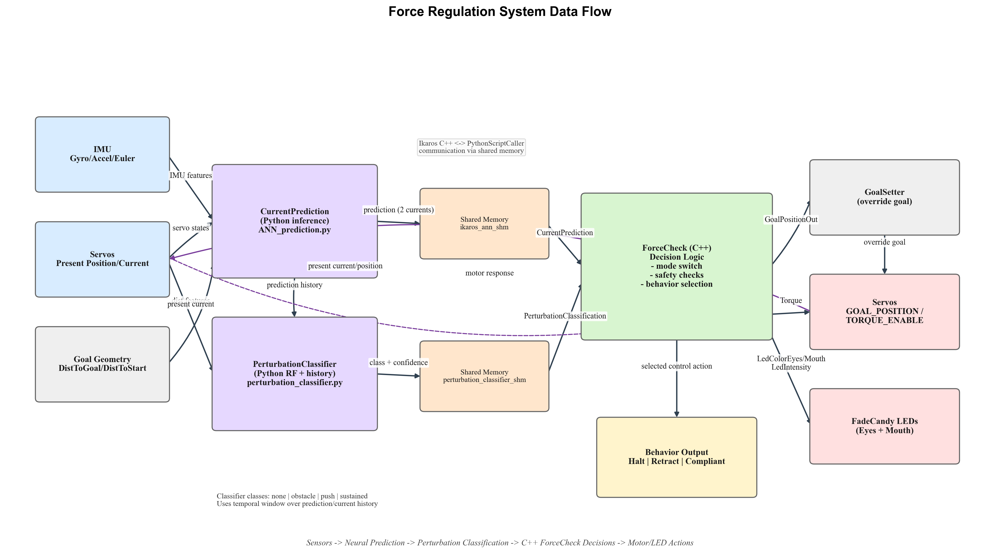

Saved -> plots/force_regulation_dataflow.jpeg


In [57]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({
    "font.size": 10.5,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "savefig.dpi": 300,
})


def draw_force_regulation_dataflow_figure(save_path="plots/force_regulation_dataflow.jpeg"):
    """Paper-style system diagram for the force regulation data flow."""

    # ------------------------------------------------------------------
    # Canvas and style
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(16, 9), dpi=300)
    ax.set_xlim(0, 19)
    ax.set_ylim(0, 11)
    ax.axis("off")
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    colors = {
        "sensor": "#D8ECFF",
        "compute": "#E6D8FF",
        "bridge": "#FFE6CC",
        "decision": "#D8F5D0",
        "actuator": "#FFE0E0",
        "helper": "#EFEFEF",
        "text": "#1A1A1A",
        "arrow": "#2F4050",
        "feedback": "#7A3E9D",
    }

    # ------------------------------------------------------------------
    # Helper functions
    # ------------------------------------------------------------------
    def add_box(x, y, w, h, text, fc, ec="#666666", fs=10, bold=False):
        patch = FancyBboxPatch(
            (x, y), w, h,
            boxstyle="round,pad=0.04,rounding_size=0.08",
            linewidth=1.2,
            edgecolor=ec,
            facecolor=fc,
            zorder=2,
        )
        ax.add_patch(patch)
        ax.text(
            x + w / 2,
            y + h / 2,
            text,
            ha="center",
            va="center",
            fontsize=fs,
            color=colors["text"],
            fontweight="bold" if bold else "normal",
            zorder=3,
            family="Times New Roman",
        )
        return (x, y, w, h)

    def right_mid(box):
        x, y, w, h = box
        return (x + w, y + h / 2)

    def left_mid(box):
        x, y, w, h = box
        return (x, y + h / 2)

    def top_mid(box):
        x, y, w, h = box
        return (x + w / 2, y + h)

    def bottom_mid(box):
        x, y, w, h = box
        return (x + w / 2, y)

    def connect(p1, p2, label=None, color=None, curve=0.0, lw=1.5, ls="-"):
        col = colors["arrow"] if color is None else color
        ax.annotate(
            "",
            xy=p2,
            xytext=p1,
            arrowprops=dict(
                arrowstyle="-|>",
                lw=lw,
                color=col,
                linestyle=ls,
                shrinkA=2,
                shrinkB=2,
                connectionstyle=f"arc3,rad={curve}",
            ),
            zorder=1,
        )
        if label:
            lx = (p1[0] + p2[0]) / 2
            ly = (p1[1] + p2[1]) / 2
            ax.text(
                lx,
                ly + 0.18,
                label,
                fontsize=9,
                family="Times New Roman",
                ha="center",
                va="bottom",
                color=colors["text"],
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.85),
                zorder=4,
            )

    # ------------------------------------------------------------------
    # Boxes (left to right)
    # ------------------------------------------------------------------
    imu = add_box(0.6, 7.6, 2.5, 1.5, "IMU\nGyro/Accel/Euler", colors["sensor"], bold=True)
    servos = add_box(0.6, 5.4, 2.5, 1.5, "Servos\nPresent Position/Current", colors["sensor"], bold=True)
    goal_geom = add_box(0.6, 3.2, 2.5, 1.5, "Goal Geometry\nDistToGoal/DistToStart", colors["helper"], bold=True)

    current_pred_py = add_box(4.0, 5.8, 3.1, 2.3, "CurrentPrediction\n(Python inference)\nANN_prediction.py", colors["compute"], bold=True)
    pred_shm = add_box(8.0, 6.2, 2.4, 1.4, "Shared Memory\nikaros_ann_shm", colors["bridge"], fs=8.5)

    pert_py = add_box(4.0, 2.6, 3.1, 2.3, "PerturbationClassifier\n(Python RF + history)\nperturbation_classifier.py", colors["compute"], bold=True)
    pert_shm = add_box(8.0, 3.0, 2.4, 1.4, "Shared Memory\nperturbation_classifier_shm", colors["bridge"], fs=8.5)

    force_check = add_box(11.1, 4.5, 3.6, 3.0, "ForceCheck (C++)\nDecision Logic\n- mode switch\n- safety checks\n- behavior selection", colors["decision"], bold=True)

    goalsetter = add_box(15.5, 6.7, 2.8, 1.5, "GoalSetter\n(override goal)", colors["helper"], bold=True)
    servos_cmd = add_box(15.5, 4.3, 2.8, 1.5, "Servos\nGOAL_POSITION /\nTORQUE_ENABLE", colors["actuator"], bold=True)
    leds = add_box(15.5, 1.9, 2.8, 1.5, "FadeCandy LEDs\n(Eyes + Mouth)", colors["actuator"], bold=True)

    behavior = add_box(11.4, 1.2, 3.0, 1.6, "Behavior Output\nHalt | Retract | Compliant", "#FFF4CC", bold=True)

    # ------------------------------------------------------------------
    # Connections and labels
    # ------------------------------------------------------------------
    connect(right_mid(imu), left_mid(current_pred_py), "IMU features")
    connect(right_mid(servos), left_mid(current_pred_py), "servo states", curve=-0.05)
    connect(right_mid(goal_geom), (4.0, 6.1), "dist features", curve=0.15)

    connect(right_mid(current_pred_py), left_mid(pred_shm), "prediction (2 currents)")
    connect(right_mid(pred_shm), left_mid(force_check), "CurrentPrediction")

    connect(right_mid(servos), left_mid(pert_py), "present current")
    connect(bottom_mid(current_pred_py), top_mid(pert_py), "prediction history", curve=0.05)
    connect(right_mid(pert_py), left_mid(pert_shm), "class + confidence")
    connect(right_mid(pert_shm), (11.1, 5.7), "PerturbationClassification")

    connect(right_mid(force_check), left_mid(goalsetter), "GoalPositionOut", curve=0.08)
    connect(bottom_mid(goalsetter), top_mid(servos_cmd), "override goal", curve=0.0)
    connect((14.7, 5.0), left_mid(servos_cmd), "Torque")

    connect((14.7, 4.6), left_mid(leds), "LedColorEyes/Mouth\nLedIntensity")
    connect(bottom_mid(force_check), top_mid(behavior), "selected control action")

    # Feedback loop from actuators/sensors back to ForceCheck and models
    connect(left_mid(servos_cmd), right_mid(servos), "motor response", color=colors["feedback"], curve=0.18, lw=1.4)
    connect(top_mid(servos), (11.2, 4.6), "present current/position", color=colors["feedback"], curve=0.15, lw=1.2, ls="--")

    # Shared memory communication note
    ax.text(
        8.95,
        8.5,
        "Ikaros C++ <-> PythonScriptCaller\ncommunication via shared memory",
        ha="center",
        va="center",
        fontsize=8.5,
        family="Times New Roman",
        color="#444444",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#FAFAFA", edgecolor="#DDDDDD"),
    )

    # Class legend for perturbation classifier
    ax.text(
        4.05,
        1.1,
        "Classifier classes: none | obstacle | push | sustained\nUses temporal window over prediction/current history",
        fontsize=8.5,
        ha="left",
        va="center",
        color="#333333",
        family="Times New Roman",
    )

    ax.set_title("Force Regulation System Data Flow", fontweight="bold", pad=14, fontsize=15)
    ax.text(
        9.5,
        0.2,
        "Sensors -> Neural Prediction -> Perturbation Classification -> C++ ForceCheck Decisions -> Motor/LED Actions",
        ha="center",
        va="center",
        fontsize=9.5,
        color="#444444",
        style="italic",
        family="Times New Roman",
    )

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved -> {save_path}")


# Generate figure
draw_force_regulation_dataflow_figure()

In [58]:
## Perturbation Experiment Dataflow (Publication Figure)

This figure summarizes the Ikaros C++ control flow, Python TensorFlow Lite current prediction, IPC via shared memory, and the perturbation protocol used for evaluation.

SyntaxError: invalid syntax (1345433293.py, line 3)

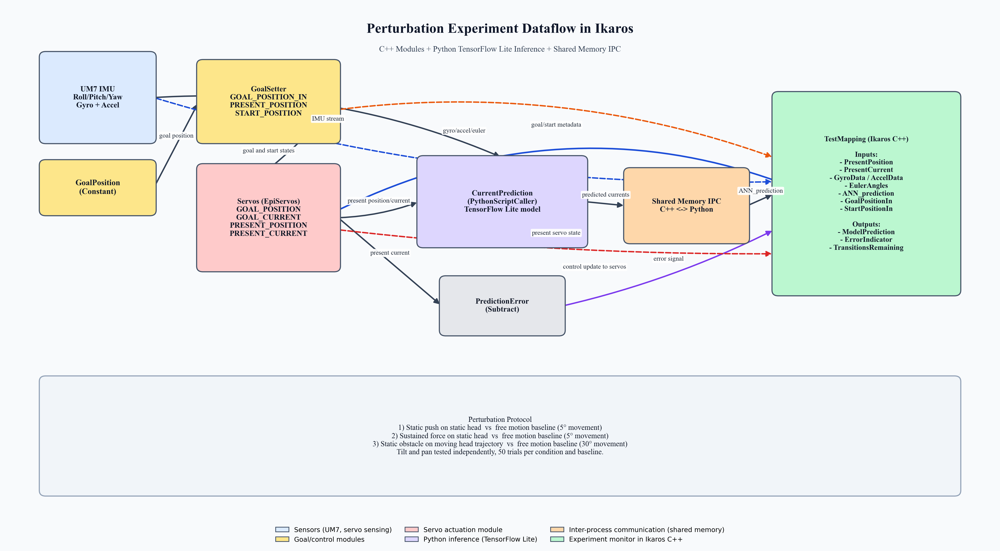

Saved figure: plots/perturbation_experiment_dataflow.png
Saved figure: plots/perturbation_experiment_dataflow.pdf


: 

: 

In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patches as mpatches

plt.rcParams.update({
    "font.size": 10.5,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "savefig.dpi": 300,
})


def draw_perturbation_experiment_dataflow(
    save_path_png="plots/perturbation_experiment_dataflow.jpeg",
    save_path_pdf="plots/perturbation_experiment_dataflow.pdf",
):
    """Create a polished system + protocol diagram for the perturbation experiment."""

    os.makedirs("plots", exist_ok=True)

    # Canvas
    fig, ax = plt.subplots(figsize=(18, 10), dpi=300)
    ax.set_xlim(0, 22)
    ax.set_ylim(0, 13)
    ax.axis("off")
    fig.patch.set_facecolor("#f8fafc")
    ax.set_facecolor("#f8fafc")

    # Color theme
    C = {
        "sensor": "#dbeafe",
        "controller": "#fde68a",
        "actuator": "#fecaca",
        "python": "#ddd6fe",
        "ipc": "#fed7aa",
        "monitor": "#bbf7d0",
        "math": "#e5e7eb",
        "text": "#111827",
        "edge": "#334155",
        "feedback": "#1d4ed8",
        "title": "#0f172a",
    }

    def add_box(x, y, w, h, text, face, edge="#475569", bold=False, z=3, fs=10.5):
        patch = FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.05,rounding_size=0.14",
            linewidth=1.4,
            edgecolor=edge,
            facecolor=face,
            zorder=z,
        )
        ax.add_patch(patch)
        ax.text(
            x + w / 2,
            y + h / 2,
            text,
            ha="center",
            va="center",
            fontsize=fs,
            fontweight="bold" if bold else "normal",
            color=C["text"],
            zorder=z + 1,
            family="Times New Roman",
        )
        return (x, y, w, h)

    def p_right(box):
        x, y, w, h = box
        return (x + w, y + h / 2)

    def p_left(box):
        x, y, w, h = box
        return (x, y + h / 2)

    def p_top(box):
        x, y, w, h = box
        return (x + w / 2, y + h)

    def p_bottom(box):
        x, y, w, h = box
        return (x + w / 2, y)

    def connect(p1, p2, label=None, color=None, rad=0.0, lw=1.8, ls="-"):
        col = C["edge"] if color is None else color
        arrow = FancyArrowPatch(
            p1,
            p2,
            arrowstyle="-|>",
            mutation_scale=14,
            connectionstyle=f"arc3,rad={rad}",
            linewidth=lw,
            linestyle=ls,
            color=col,
            zorder=2,
            shrinkA=3,
            shrinkB=3,
        )
        ax.add_patch(arrow)
        if label:
            lx = (p1[0] + p2[0]) / 2
            ly = (p1[1] + p2[1]) / 2
            ax.text(
                lx,
                ly + 0.22,
                label,
                fontsize=8.5,
                family="Times New Roman",
                ha="center",
                va="center",
                color="#1f2937",
                bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.92},
                zorder=5,
            )

    # Title
    ax.text(
        11,
        12.4,
        "Perturbation Experiment Dataflow in Ikaros",
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        color=C["title"],
        family="Times New Roman",
    )
    ax.text(
        11,
        11.9,
        "C++ Modules + Python TensorFlow Lite Inference + Shared Memory IPC",
        ha="center",
        va="center",
        fontsize=10.5,
        color="#334155",
        family="Times New Roman",
    )

    # Left: sensors and reference
    goal_const = add_box(0.8, 7.8, 2.5, 1.3, "GoalPosition\n(Constant)", C["controller"], bold=True)
    um7 = add_box(0.8, 9.6, 2.5, 2.2, "UM7 IMU\nRoll/Pitch/Yaw\nGyro + Accel", C["sensor"], bold=True, fs=10)
    servos = add_box(4.3, 6.4, 3.1, 2.6, "Servos (EpiServos)\nGOAL_POSITION\nGOAL_CURRENT\nPRESENT_POSITION\nPRESENT_CURRENT", C["actuator"], bold=True, fs=10)
    goalsetter = add_box(4.3, 9.6, 3.1, 2.0, "GoalSetter\nGOAL_POSITION_IN\nPRESENT_POSITION\nSTART_POSITION", C["controller"], bold=True, fs=10)

    # Middle: prediction + comparison
    py_pred = add_box(9.2, 7.0, 3.7, 2.2, "CurrentPrediction\n(PythonScriptCaller)\nTensorFlow Lite model", C["python"], bold=True, fs=10)
    pred_err = add_box(9.7, 4.8, 2.7, 1.4, "PredictionError\n(Subtract)", C["math"], bold=True, fs=10)

    # IPC bridge + C++ monitor
    ipc = add_box(13.8, 7.1, 2.7, 1.8, "Shared Memory IPC\nC++ <-> Python", C["ipc"], bold=True, fs=10)
    test_mapping = add_box(17.1, 5.8, 4.1, 5.0, "TestMapping (Ikaros C++)\n\nInputs:\n- PresentPosition\n- PresentCurrent\n- GyroData / AccelData\n- EulerAngles\n- ANN_prediction\n- GoalPositionIn\n- StartPositionIn\n\nOutputs:\n- ModelPrediction\n- ErrorIndicator\n- TransitionsRemaining", C["monitor"], bold=True, fs=9.5)

    # Protocol panel
    protocol = add_box(
        0.8,
        0.8,
        20.4,
        2.9,
        "Perturbation Protocol\n"
        "1) Static push on static head  vs  free motion baseline (5° movement)\n"
        "2) Sustained force on static head  vs  free motion baseline (5° movement)\n"
        "3) Static obstacle on moving head trajectory  vs  free motion baseline (30° movement)\n"
        "Tilt and pan tested independently, 50 trials per condition and baseline.",
        "#f1f5f9",
        edge="#94a3b8",
        fs=9.5,
        bold=False,
    )

    # Connections from source modules
    connect(p_right(goal_const), p_left(goalsetter), "goal position")
    connect(p_right(goalsetter), p_left(servos), "goal and start states", rad=-0.08)
    connect(p_right(um7), p_top(py_pred), "IMU stream", rad=-0.12)
    connect(p_right(servos), p_left(py_pred), "present position/current", rad=0.08)
    connect(p_right(servos), p_left(pred_err), "present current")

    # Prediction chain
    connect(p_right(py_pred), p_left(ipc), "predicted currents")
    connect(p_right(ipc), p_left(test_mapping), "ANN_prediction")
    connect(p_right(pred_err), (17.1, 7.4), "error signal", color="#7c3aed", rad=0.06)

    # Additional feed into monitor
    connect(p_right(um7), (17.1, 8.6), "gyro/accel/euler", color=C["feedback"], rad=0.08, ls="--")
    connect((7.4, 10.4), (17.1, 9.2), "goal/start metadata", color="#ea580c", rad=-0.12, ls="--")
    connect((7.4, 7.4), (17.1, 6.8), "present servo state", color="#dc2626", rad=0.03, ls="--")

    # Closed-loop feedback
    connect((21.2, 6.2), (5.0, 6.3), "control update to servos", color=C["feedback"], rad=0.35, lw=2.0)

    # Legend
    legend_items = [
        mpatches.Patch(facecolor=C["sensor"], edgecolor="#475569", label="Sensors (UM7, servo sensing)"),
        mpatches.Patch(facecolor=C["controller"], edgecolor="#475569", label="Goal/control modules"),
        mpatches.Patch(facecolor=C["actuator"], edgecolor="#475569", label="Servo actuation module"),
        mpatches.Patch(facecolor=C["python"], edgecolor="#475569", label="Python inference (TensorFlow Lite)"),
        mpatches.Patch(facecolor=C["ipc"], edgecolor="#475569", label="Inter-process communication (shared memory)"),
        mpatches.Patch(facecolor=C["monitor"], edgecolor="#475569", label="Experiment monitor in Ikaros C++"),
    ]
    ax.legend(
        handles=legend_items,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=3,
        frameon=False,
        fontsize=8.5,
    )

    plt.tight_layout()
    plt.savefig(save_path_png, dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.savefig(save_path_pdf, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    print(f"Saved figure: {save_path_png}")
    print(f"Saved figure: {save_path_pdf}")


draw_perturbation_experiment_dataflow()